# 15 · Statistics & Image Basics: Distributions, Histograms, Masks and Similarity
*AI Foundations · Notebook 15 of 19*

To a computer, a photo is just a grid of numbers. That means everything you know about describing data (averages, spread, distributions) applies directly to images, and many classic image-processing tricks turn out to be statistics in disguise. In this notebook you will build a complete toolkit, from the ground up: you will describe pixel values with means, medians, variances and cumulative distributions, use the cumulative distribution to **equalize** a washed-out photo, cut a person out of a video frame and paste them onto a **virtual background** (the same idea video-call apps use), and finally turn images into vectors and compare them with **dot products and cosine similarity**. Exam questions on these topics are usually small grids of numbers computed by hand, where one tiny slip ($>$ instead of $\ge$, $n-1$ instead of $n$, the wrong flattening order) changes the final answer. So we will work every idea out by hand first, then in code, and then on realistic synthetic images.

**What you will learn**
- Images as arrays: shapes `(H, W)` and `(H, W, C)`, `(row, col)` versus `(x, y)` coordinates, `uint8` overflow (why `10 - 20 = 246`) and how to avoid it, row-major versus column-major flattening, and the elementwise (Hadamard) product.
- Descriptive statistics: mean, median, mode, range, variance and standard deviation, and **population versus sample variance** and why the sample version divides by $n-1$ (Bessel's correction, proved and then simulated).
- Quantiles and percentiles (and why software packages disagree), the interquartile range, outliers, and **robust statistics** (median, MAD, median filtering).
- Distributions of pixel values: the empirical **PMF** $P(X=x)$ and **CDF** $P(X\le x)$, the difference between the two, and how to choose histogram bins.
- Contrast: lookup tables, contrast stretching, gamma correction, **histogram equalization** (derived from the CDF, computed by hand, implemented from scratch, compared with OpenCV) and **CLAHE**.
- Background subtraction and compositing: difference images, thresholds ($\ge$ vs $>$), statistically chosen thresholds, **Otsu's method**, morphological cleanup, $O = M\odot I + (1-M)\odot F$, soft masks and alpha blending, and the ways the method fails.
- Linear features and similarity: $\mathbf z = W\mathbf x$ as a bank of dot-product filters, $L_1$/$L_2$ norms, unit vectors, dot product versus cosine similarity (and why normalizing only one side is a trap), nearest-prototype classification and template matching.

**Prerequisites:** Python and NumPy basics (arrays, slicing, broadcasting), high-school algebra, summation notation $\sum$. Knowing what a probability is helps, and everything else is built from scratch.      **Estimated time:** ~6 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are marked ✏️, and each has an automatic checker and a hidden solution (click "Solution" to expand). Quick-check questions have hidden answers.

**Contents**
1. Images are arrays of numbers
2. Describing pixel values: center and spread
3. Population versus sample variance (Bessel's correction)
4. Quantiles, outliers and robust statistics
5. Distributions of pixel values: PMF, CDF and histograms
6. Contrast and point operations
7. Histogram equalization and CLAHE
8. Background subtraction: difference images, thresholds and Otsu's method
9. Cleaning masks and compositing
10. Linear features, norms and similarity
11. Similarity in action: prototypes and template matching
12. Capstone: the tiny virtual-background pipeline by hand
13. Exam-style questions
14. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style, a tiny test harness and a plotting helper.
import math
import statistics
import sys
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# No downloads are needed: every image is generated by code in this notebook, and the
# handwritten digits in Section 11 ship with scikit-learn. DATA_DIR is kept for consistency.
DATA_DIR = Path("data")

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
np.set_printoptions(precision=4, suppress=True, linewidth=110)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__}\nscikit-learn {sklearn.__version__} | opencv {cv2.__version__} | "
      f"matplotlib {matplotlib.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")


def show_images(images, titles=None, ncols=None, size=3.2, vmin=0, vmax=255, cmap="gray", suptitle=None):
    """Show 2-D (grayscale) or (H, W, 3) RGB images side by side.

    Grayscale images are drawn with a FIXED intensity scale vmin..vmax (0..255 by default),
    so that a dull image really looks dull (plt.imshow would otherwise auto-stretch it).
    """
    n = len(images)
    ncols = ncols or n
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(min(12, size * ncols), size * 0.8 * nrows), squeeze=False)
    for k, ax in enumerate(axes.ravel()):
        if k >= n:
            ax.axis("off")
            continue
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
        for spine in ax.spines.values():          # a thin frame, so white images stay visible
            spine.set_visible(True)
            spine.set_linewidth(0.6)
            spine.set_color("0.6")
        img = images[k]
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
        else:
            ax.imshow(img, interpolation="nearest")
        if titles is not None:
            ax.set_title(titles[k], fontsize=10)
    if suptitle:
        fig.suptitle(suptitle)
    fig.tight_layout()
    plt.show()

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | scipy 1.18.1
scikit-learn 1.9.1 | opencv 5.0.0 | matplotlib 3.11.2


## 1. Images are arrays of numbers

A digital camera has a sensor made of millions of tiny light-measuring cells. Each cell reports one number: how much light reached it during the exposure. Arrange those numbers in the same grid as the cells and you have an image. Each grid cell is a **pixel** ("picture element"), and its number is the pixel's **intensity**. Nothing more is going on: every operation in this notebook is arithmetic on such grids.

### 1.1 Grayscale images, shapes and coordinates

A **grayscale image** with $H$ rows and $W$ columns is a matrix $I \in \{0, 1, \dots, 255\}^{H \times W}$. The most common storage type is `uint8` (*unsigned 8-bit integer*): 8 bits give $2^8 = 256$ possible values, so intensities run from $0$ (black) to $255$ (white). In NumPy:

* `img.shape == (H, W)`: **rows first, then columns**. Height comes before width.
* `img[r, c]` is the pixel in row `r` (counted **downward** from the top, starting at 0) and column `c` (counted rightward from the left, starting at 0). The origin `(0, 0)` is the **top-left** corner, so "down" means *increasing* row index, the opposite of the usual math $y$-axis.

```
            c = 0   1   2   3   4   5   6        → columns (image "x")
     r = 0  [ 20  20  20  20  20  20  20 ]
         1  [ 20 230 230 230 230 230  20 ]
         2  [ 20  20  20 230  20  20  20 ]
         3  [ 20  20  20 230  20  20  20 ]
         4  [ 20  20  20 230  20 120  20 ]       img[4, 5] = 120
         5  [ 20  20  20  20  20  20  20 ]
     ↓ rows (image "y")
```

Let's build exactly this tiny image (a bright letter T plus one gray pixel) and poke at it.

In [2]:
tiny = np.full((6, 7), 20, dtype=np.uint8)   # dark background
tiny[1, 1:6] = 230                           # the bar of the T (row 1, columns 1..5)
tiny[2:5, 3] = 230                           # the stem of the T (rows 2..4, column 3)
tiny[4, 5] = 120                             # one gray pixel

print("shape (H, W):", tiny.shape, "| dtype:", tiny.dtype, "| number of pixels:", tiny.size)
print("tiny[4, 5] (row 4, column 5) =", tiny[4, 5])
print("row 1         :", tiny[1])            # a 1-D array of length W
print("column 3      :", tiny[:, 3])         # a 1-D array of length H
print("crop rows 1..2, cols 2..4:\n", tiny[1:3, 2:5])

shape (H, W): (6, 7) | dtype: uint8 | number of pixels: 42
tiny[4, 5] (row 4, column 5) = 120
row 1         : [ 20 230 230 230 230 230  20]
column 3      : [ 20 230 230 230 230  20]
crop rows 1..2, cols 2..4:
 [[230 230 230]
 [ 20 230  20]]


Printing numbers is precise but hard to "see". The helper below draws an image as gray squares and writes each pixel's value on top. We will reuse it for every small hand-worked example.

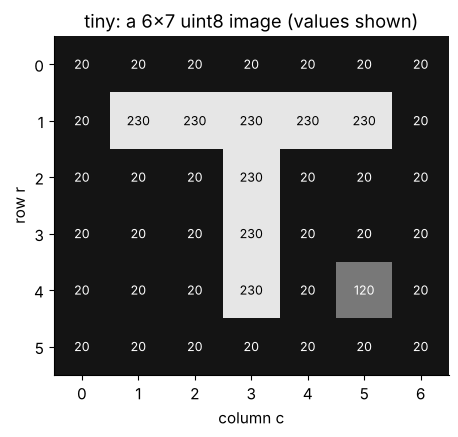

In [3]:
def show_pixels(img, ax, title="", vmin=0, vmax=255, fmt="{:d}", fontsize=9):
    """Draw a small image with its pixel values written inside the cells."""
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest")
    mid = (vmin + vmax) / 2
    for (r, c), v in np.ndenumerate(img):
        ax.text(c, r, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                color="black" if v > mid else "white")
    ax.set_xticks(range(img.shape[1]))
    ax.set_yticks(range(img.shape[0]))
    ax.set_xlabel("column c")
    ax.set_ylabel("row r")
    ax.grid(False)
    ax.set_title(title)


fig, ax = plt.subplots(figsize=(5.2, 4.4))
show_pixels(tiny, ax, "tiny: a 6×7 uint8 image (values shown)")
plt.show()

> **Common pitfall: `(row, col)` versus `(x, y)`.** NumPy indexes `img[row, col]`, which is `img[y, x]`. Many OpenCV functions that take *points* or *sizes* use the opposite order: `cv2.circle(img, center=(x, y), ...)`, `cv2.putText(img, text, org=(x, y), ...)` and `cv2.resize(img, dsize=(width, height))`. Mixing the two conventions is one of the most common bugs in image code. When a result looks transposed or a shape is "almost right", check this first.

The cell below draws a dot with `center=(45, 12)` and then asks NumPy where the dot landed.

In [4]:
canvas = np.zeros((40, 60), dtype=np.uint8)                      # H = 40 rows, W = 60 columns
cv2.circle(canvas, center=(45, 12), radius=3, color=255, thickness=-1)   # center given as (x, y)
rows, cols = np.nonzero(canvas)
print(f"cv2 center (x, y) = (45, 12)  ->  dot found at row {rows.mean():.0f}, column {cols.mean():.0f}")
print("canvas[12, 45] =", canvas[12, 45], "  but canvas[45, 12] would be out of range: H is only", canvas.shape[0])

small = cv2.resize(canvas, dsize=(30, 20))                        # dsize = (width, height)
print("cv2.resize(canvas, dsize=(30, 20)).shape =", small.shape, "-> (H, W) = (20, 30)")

cv2 center (x, y) = (45, 12)  ->  dot found at row 12, column 45
canvas[12, 45] = 255   but canvas[45, 12] would be out of range: H is only 40
cv2.resize(canvas, dsize=(30, 20)).shape = (20, 30) -> (H, W) = (20, 30)


### 1.2 Color images and channels

A color image stores **three** numbers per pixel (red, green, blue), so it is a 3-D array of shape `(H, W, 3)`: the last axis indexes the **channel**. Three conventions to keep straight:

| library | memory layout | channel order |
|---|---|---|
| NumPy / matplotlib / Pillow | `(H, W, C)` "channels-last" | RGB |
| OpenCV (`cv2.imread`) | `(H, W, C)` | **BGR** (blue first) |
| PyTorch tensors | `(C, H, W)` "channels-first" (`(N, C, H, W)` for a batch) | RGB |

A grayscale version is a weighted sum of the channels. The classic *luma* weights (ITU-R BT.601, used by `cv2.cvtColor`) are

$$
Y = 0.299\,R + 0.587\,G + 0.114\,B .
$$

The weights are unequal because human eyes are most sensitive to green and least to blue: pure green looks much brighter to us than pure blue at the same physical intensity.

In [5]:
patch_rgb = np.zeros((2, 4, 3), dtype=np.uint8)
patch_rgb[0] = [(255, 0, 0), (0, 255, 0), (0, 0, 255), (255, 255, 255)]      # red, green, blue, white
patch_rgb[1] = [(255, 255, 0), (128, 128, 128), (200, 120, 40), (10, 200, 230)]  # yellow, gray, orange, cyan-ish

gray_cv = cv2.cvtColor(patch_rgb, cv2.COLOR_RGB2GRAY)        # tell OpenCV our order is RGB
weights = np.array([0.299, 0.587, 0.114])
gray_formula = patch_rgb.astype(np.float64) @ weights         # (2, 4, 3) @ (3,) -> (2, 4)

print("color shape:", patch_rgb.shape, "-> gray shape:", gray_cv.shape)
print("cv2 gray:\n", gray_cv)
print("formula (before rounding):\n", gray_formula.round(2))
print("largest difference after rounding:", np.abs(np.rint(gray_formula) - gray_cv).max())

color shape: (2, 4, 3) -> gray shape: (2, 4)
cv2 gray:
 [[ 76 150  29 255]
 [226 128 135 147]]
formula (before rounding):
 [[ 76.24 149.68  29.07 255.  ]
 [225.93 128.   134.8  146.61]]
largest difference after rounding: 0.0


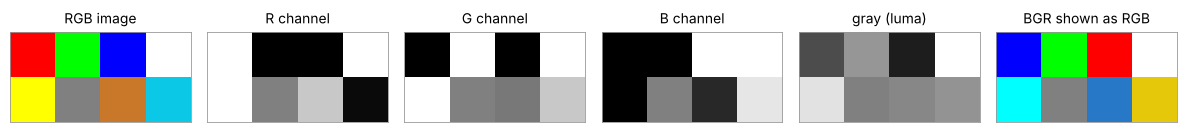

In [6]:
bgr_by_mistake = patch_rgb[..., ::-1]           # reversing the channel axis turns RGB into BGR
show_images(
    [patch_rgb, patch_rgb[..., 0], patch_rgb[..., 1], patch_rgb[..., 2], gray_cv, bgr_by_mistake],
    ["RGB image", "R channel", "G channel", "B channel", "gray (luma)", "BGR shown as RGB"],
    ncols=6, size=2.0,
)

Each channel on its own is a grayscale image: the red channel is bright wherever there is a lot of red. The last panel shows what happens when an OpenCV image (BGR) is handed to matplotlib (which expects RGB) without conversion: red and blue swap. The fix is `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` or `img[..., ::-1]`. From now on we work with grayscale images, but everything carries over to color images channel by channel.

### 1.3 Data types: when $10 - 20 = 246$

A `uint8` stores only 8 bits, so it can only hold $0,\dots,255$. When an arithmetic result does not fit, the hardware keeps the lowest 8 bits and silently throws the rest away. Mathematically, every `uint8` result is computed **modulo 256**:

$$
\text{result} = (\text{true value}) \bmod 256 .
$$

| expression (uint8) | true value | stored result |
|---|---|---|
| $10 - 20$ | $-10$ | $-10 + 256 = 246$ |
| $200 + 100$ | $300$ | $300 - 256 = 44$ |
| $2 \times 200$ | $400$ | $400 - 256 = 144$ |
| $(200 + 100) / 2$ | $150$ | $44 / 2 = 22$ |

This is called **wraparound** (overflow when going above 255, underflow when going below 0). Think of a car's odometer rolling over from 999999 to 000000. For images it is a disaster: a pixel that got slightly *darker* ($10 \to$ "$-10$") suddenly looks like a huge *bright* change ($246$).

In [7]:
a = np.array([[10, 200, 3]], dtype=np.uint8)
b = np.array([[20, 100, 100]], dtype=np.uint8)
print("a          =", a, "\nb          =", b)
print("a - b      =", a - b, "   <- 10-20 and 3-100 wrapped around")
print("a + b      =", a + b, "   <- 200+100 wrapped around")
print("2 * a      =", 2 * a)
print("(a + b)//2 =", (a + b) // 2, "  <- the average of 200 and 100 is NOT 22")
print("result dtype:", (a - b).dtype, "(NumPy keeps uint8 and gives no warning for arrays)")

try:
    a - 300                      # NumPy >= 2: a Python int that does not fit in uint8 is rejected
except OverflowError as err:
    print("a - 300 ->", type(err).__name__ + ":", err)

a          = [[ 10 200   3]] 
b          = [[ 20 100 100]]
a - b      = [[246 100 159]]    <- 10-20 and 3-100 wrapped around
a + b      = [[ 30  44 103]]    <- 200+100 wrapped around
2 * a      = [[ 20 144   6]]
(a + b)//2 = [[15 22 51]]   <- the average of 200 and 100 is NOT 22
result dtype: uint8 (NumPy keeps uint8 and gives no warning for arrays)
a - 300 -> OverflowError: Python integer 300 out of bounds for uint8


NumPy does **not** warn you when array arithmetic wraps. (It warns for single NumPy scalars, and since NumPy 2 it refuses Python integers that cannot fit in the array's type, as shown above, but that does not protect array-with-array arithmetic.) The fixes:

1. **Convert to a wider, signed type before arithmetic**: `a.astype(np.int16) - b` (or `np.int32`, or `np.float64`). Then $10 - 20 = -10$ exactly, and you take `np.abs` afterwards.
2. **Use OpenCV's saturating functions**: `cv2.absdiff(a, b)` computes $|a - b|$ correctly, and `cv2.add` and `cv2.subtract` **clip** to $[0, 255]$ instead of wrapping. Careful: clipping is not the same as an absolute difference, since for two `uint8` pixels $10$ and $20$, `cv2.subtract` gives $0$, not $10$. Also pass real images (2-D NumPy arrays), as in the next cell: OpenCV reads plain Python numbers, and even 1-D arrays of up to four values, as a "scalar" (one number per color channel) rather than as an image, so `cv2.subtract(10, 20)` returns a small `float64` array containing $-10$, with no clipping at all.
3. **Convert back to `uint8` safely**: clip to $[0, 255]$, round, then cast. Casting an out-of-range float directly with `.astype(np.uint8)` is *undefined behavior*: the result depends on your CPU and NumPy version.

In [8]:
diff_int = np.abs(a.astype(np.int16) - b.astype(np.int16))     # widen first, then subtract
print("|a - b| via int16   :", diff_int, diff_int.dtype)
print("cv2.absdiff(a, b)   :", cv2.absdiff(a, b))              # pass 2-D arrays to OpenCV
print("cv2.subtract(a, b)  :", cv2.subtract(a, b), "  <- clipped at 0, not an absolute difference")
print("cv2.add(a, b)       :", cv2.add(a, b), "  <- clipped at 255")


def to_uint8(x):
    """Clip to [0, 255], round to the nearest integer, then cast to uint8 (the safe way)."""
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)


wild = np.array([300.7, -5.2, 255.9, 128.5])
print("unsafe .astype(uint8):", wild.astype(np.uint8), "  <- platform-dependent garbage")
print("to_uint8             :", to_uint8(wild))
print("np.mean / np.sum on uint8 are safe:", np.full(1000, 255, np.uint8).mean(),
      np.full(1000, 255, np.uint8).sum())

|a - b| via int16   : [[ 10 100  97]] int16
cv2.absdiff(a, b)   : [[ 10 100  97]]
cv2.subtract(a, b)  : [[  0 100   0]]   <- clipped at 0, not an absolute difference
cv2.add(a, b)       : [[ 30 255 103]]   <- clipped at 255
unsafe .astype(uint8): [ 44 251 255 128]   <- platform-dependent garbage
to_uint8             : [255   0 255 128]
np.mean / np.sum on uint8 are safe: 255.0 255000


Two details in that output deserve a comment. First, `np.rint` rounds halves **to the nearest even integer**, so `128.5` became `128`, not `129`. We will meet this rounding rule again in Section 7, where it matters. Second, reductions such as `np.sum` and `np.mean` are safe because NumPy accumulates small integer types in a wide type (`np.mean` even returns a float). It is the *elementwise* operators `+ - * //` that wrap.

> **Key idea.** Before doing arithmetic on images, decide which type the *result* needs. Differences can be negative and sums can exceed 255, so compute in `int16`/`int32`/`float64`, and only convert back with clip → round → cast at the very end.

#### ✏️ Exercise 1: an absolute difference that cannot wrap

Write `abs_diff_u8(a, b)` that returns $|a - b|$ for two `uint8` arrays of the same shape. The result must be a `uint8` array, correct for every pair of values, and you may **not** use OpenCV.

In [9]:
# ✏️ Exercise 1: absolute difference of two uint8 images without wraparound
def abs_diff_u8(a, b):
    """Return |a - b| elementwise as a uint8 array (a, b: uint8 arrays of equal shape)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    x = np.array([[10, 200, 3, 0, 255]], dtype=np.uint8)
    y = np.array([[20, 100, 100, 255, 0]], dtype=np.uint8)
    out = abs_diff_u8(x, y)
    assert isinstance(out, np.ndarray) and out.dtype == np.uint8, f"expected a uint8 array, got {getattr(out, 'dtype', type(out))}"
    assert out.shape == x.shape, f"shape changed: {out.shape}"
    assert out.tolist() == [[10, 100, 97, 255, 255]], f"got {out.tolist()}"
    r = np.random.default_rng(0)
    p, q = r.integers(0, 256, (2, 30, 40), dtype=np.uint8)
    assert np.array_equal(abs_diff_u8(p, q), cv2.absdiff(p, q)), "disagrees with cv2.absdiff on random images"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def abs_diff_u8(a, b):
    d = a.astype(np.int16) - b.astype(np.int16)   # -255..255 fits in int16
    return np.abs(d).astype(np.uint8)             # 0..255 fits in uint8 again
```
Widening to a signed type makes the subtraction exact, and the absolute value is between 0 and 255, so the final cast is safe. An equivalent trick that stays in `uint8` is `np.maximum(a, b) - np.minimum(a, b)`, because the larger minus the smaller can never go negative.
</details>

### 1.4 Flattening: row-major versus column-major order

Many methods (linear layers, dot products, classical classifiers) want a **vector**, not a grid. *Flattening* (also called *vectorizing*) lists the $H \cdot W$ pixels in some fixed order. There are two standard orders:

* **Row-major** (`order="C"`, NumPy's default, also C, PyTorch): read like a book, left to right along row 0, then row 1, and so on. Pixel $(r, c)$ lands at position
$$
k = r \cdot W + c .
$$
* **Column-major** (`order="F"`, as in Fortran, MATLAB, R, Julia): read down column 0, then column 1, and so on, like newspaper columns. Pixel $(r, c)$ lands at position
$$
k = c \cdot H + r .
$$

Going back: in row-major order, position $k$ is pixel $(r, c) = (\lfloor k / W \rfloor,\; k \bmod W)$.

In [10]:
grid = np.arange(12).reshape(3, 4) * 10        # H = 3, W = 4, and the values tell us where each pixel sits
print("grid (H=3, W=4):\n", grid)
print("row-major    ravel(order='C'):", grid.ravel(order="C"))
print("column-major ravel(order='F'):", grid.ravel(order="F"))
print("grid.T.ravel() equals the F-order:", np.array_equal(grid.T.ravel(), grid.ravel(order="F")))

r, c = 2, 1
H, W = grid.shape
print(f"\npixel ({r}, {c}) holds {grid[r, c]}: C-position {r * W + c} -> {grid.ravel('C')[r * W + c]}, "
      f"F-position {c * H + r} -> {grid.ravel('F')[c * H + r]}")
print("np.ravel_multi_index((2, 1), (3, 4)) =", np.ravel_multi_index((2, 1), (3, 4)),
      "| with order='F':", np.ravel_multi_index((2, 1), (3, 4), order="F"))

x_f = grid.ravel(order="F")
print("\nF-flatten then default (C) reshape scrambles the image:\n", x_f.reshape(3, 4))
print("F-flatten then reshape(order='F') restores it:", np.array_equal(x_f.reshape(3, 4, order="F"), grid))

grid (H=3, W=4):
 [[  0  10  20  30]
 [ 40  50  60  70]
 [ 80  90 100 110]]
row-major    ravel(order='C'): [  0  10  20  30  40  50  60  70  80  90 100 110]
column-major ravel(order='F'): [  0  40  80  10  50  90  20  60 100  30  70 110]
grid.T.ravel() equals the F-order: True

pixel (2, 1) holds 90: C-position 9 -> 90, F-position 5 -> 90
np.ravel_multi_index((2, 1), (3, 4)) = 9 | with order='F': 5

F-flatten then default (C) reshape scrambles the image:
 [[  0  40  80  10]
 [ 50  90  20  60]
 [100  30  70 110]]
F-flatten then reshape(order='F') restores it: True


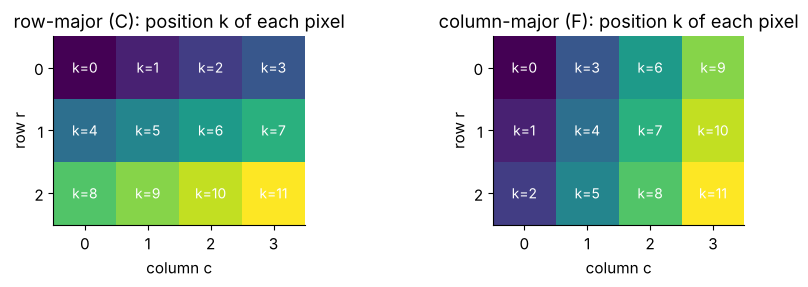

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, order, name in zip(axes, ["C", "F"], ["row-major (C)", "column-major (F)"]):
    pos = np.arange(grid.size).reshape(grid.shape, order=order)     # position of each pixel in the vector
    ax.imshow(pos, cmap="viridis", interpolation="nearest")
    for (rr, cc), k in np.ndenumerate(pos):
        ax.text(cc, rr, f"k={k}", ha="center", va="center", color="white", fontsize=10)
    ax.set_title(f"{name}: position k of each pixel")
    ax.set_xlabel("column c")
    ax.set_ylabel("row r")
    ax.set_xticks(range(4))
    ax.set_yticks(range(3))
    ax.grid(False)
fig.tight_layout()
plt.show()

> **Common pitfall.** If you flatten with one order and reshape (or build weights) with the other, nothing crashes: you just get a silently scrambled image or meaningless features. Exam questions state the order explicitly ("row by row, left to right, top to bottom" means row-major). In Section 12 you will see a wrong order change the final answer of a whole pipeline.

#### ✏️ Exercise 2: flat positions by hand

Implement `flat_index(r, c, shape, order)` (the position of pixel `(r, c)` in the flattened vector) and its inverse `unflat_index(k, shape, order)` (returns the tuple `(r, c)`), for `order` equal to `"C"` or `"F"`. Use the formulas above, and do not call `np.ravel_multi_index`.

In [12]:
# ✏️ Exercise 2: row-major and column-major positions
def flat_index(r, c, shape, order="C"):
    """Position of pixel (r, c) in an image of the given (H, W) shape after flattening."""
    # YOUR CODE HERE
    raise NotImplementedError


def unflat_index(k, shape, order="C"):
    """Inverse of flat_index: return (r, c) for position k."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert flat_index(2, 1, (3, 4), "C") == 9, f"C: expected 9, got {flat_index(2, 1, (3, 4), 'C')}"
    assert flat_index(2, 1, (3, 4), "F") == 5, f"F: expected 5, got {flat_index(2, 1, (3, 4), 'F')}"
    for shape in [(3, 4), (5, 2), (1, 7), (6, 6)]:
        for order in ["C", "F"]:
            for k in range(shape[0] * shape[1]):
                rc = tuple(int(v) for v in np.unravel_index(k, shape, order=order))
                assert tuple(unflat_index(k, shape, order)) == rc, f"unflat_index({k}, {shape}, {order!r}) should be {rc}"
                assert flat_index(*rc, shape, order) == k, f"flat_index{rc} with {shape}, {order!r} should be {k}"


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def flat_index(r, c, shape, order="C"):
    H, W = shape
    return r * W + c if order == "C" else c * H + r

def unflat_index(k, shape, order="C"):
    H, W = shape
    if order == "C":
        return (k // W, k % W)
    return (k % H, k // H)
```
In row-major order each complete row contributes $W$ positions, so the row is $\lfloor k/W\rfloor$ and the column is the remainder. Column-major order is the same idea with the roles of rows and columns swapped.
</details>

### 1.5 The elementwise (Hadamard) product and masks

For two matrices of the **same shape**, the **Hadamard product** multiplies matching entries:

$$
(A \odot B)_{ij} = A_{ij}\, B_{ij} .
$$

In NumPy this is simply `A * B`. Do not confuse it with the **matrix product** `A @ B`, which needs `A.shape[1] == B.shape[0]` and sums products along rows and columns. The Hadamard product is how **masks** work: if $M$ contains only 0s and 1s, then $M \odot I$ keeps the pixels of $I$ where $M = 1$ and sets the rest to 0, and $(1 - M) \odot F$ does the opposite. Adding the two gives the compositing formula $O = M \odot I + (1 - M) \odot F$ of Section 9.

In [13]:
I_small = np.array([[50, 60], [70, 80]])
F_small = np.array([[1, 2], [3, 4]])
M_small = np.array([[1, 0], [1, 1]])
print("M ⊙ I  (A * B):\n", M_small * I_small)
print("M @ I  (matrix product, something else entirely):\n", M_small @ I_small)
print("M ⊙ I + (1 - M) ⊙ F:\n", M_small * I_small + (1 - M_small) * F_small)

# Inverting a mask: the right tool depends on the mask's dtype
m_int = np.array([0, 1, 1, 0])
print("\n1 - m (int 0/1 mask)     :", 1 - m_int, "  <- correct")
print("~m    (int 0/1 mask)     :", ~m_int, "  <- bitwise NOT of integers, wrong!")
print("~m    (uint8 0/1 mask)   :", ~m_int.astype(np.uint8), "  <- also wrong")
print("~m    (boolean mask)     :", ~m_int.astype(bool), "  <- correct for booleans")
try:
    np.True_ - m_int.astype(bool)
except TypeError as err:
    print("True - bool mask         : TypeError:", str(err)[:60] + "...")

M ⊙ I  (A * B):
 [[50  0]
 [70 80]]
M @ I  (matrix product, something else entirely):
 [[ 50  60]
 [120 140]]
M ⊙ I + (1 - M) ⊙ F:
 [[50  2]
 [70 80]]

1 - m (int 0/1 mask)     : [1 0 0 1]   <- correct
~m    (int 0/1 mask)     : [-1 -2 -2 -1]   <- bitwise NOT of integers, wrong!
~m    (uint8 0/1 mask)   : [255 254 254 255]   <- also wrong
~m    (boolean mask)     : [ True False False  True]   <- correct for booleans
True - bool mask         : TypeError: numpy boolean subtract, the `-` operator, is not supported, ...


> **Common pitfall.** `~` means "logical NOT" only for **boolean** arrays. On integers it is a bitwise NOT ($\sim 1 = -2$ for signed integers, $\sim 1 = 254$ for `uint8`). Use `~M` or `np.logical_not(M)` for boolean masks and `1 - M` for 0/1 numeric masks, or convert once with `M.astype(bool)` and stay boolean.

**Quick check 1.** (a) An array has shape `(480, 640, 3)`. How tall is the image, and how many numbers does it store? (b) In row-major order, where does pixel $(r, c) = (3, 5)$ of a $10 \times 8$ image land? And in column-major order? (c) Two `uint8` pixels have values $90$ and $250$. What does NumPy return for their difference $90 - 250$, and for their sum?

<details>
<summary>Answer</summary>

(a) Shape is `(H, W, C)`, so the image is 480 pixels tall and 640 wide, and it stores $480 \cdot 640 \cdot 3 = 921{,}600$ numbers.
(b) Row-major: $k = r W + c = 3 \cdot 8 + 5 = 29$. Column-major: $k = c H + r = 5 \cdot 10 + 3 = 53$.
(c) $90 - 250 = -160 \equiv -160 + 256 = 96$ and $90 + 250 = 340 \equiv 340 - 256 = 84$. Both are wrong as intensities, which is why you widen the type first.
</details>

## 2. Describing pixel values: center and spread

Forget for a moment *where* the pixels are and look only at *which values* occur. A patch of $N$ pixels is then simply a dataset of $N$ numbers $x_1, \dots, x_N$, and we can summarize it like any dataset: where is its center, and how spread out is it?

It also helps to phrase this with probability. Pick one of the $N$ pixels **uniformly at random** (each with probability $1/N$) and let $X$ be its gray level. Then $X$ is a **random variable**, and every summary below (mean, median, variance, ...) is a property of $X$. This viewpoint pays off in Sections 3 and 5.

Our running example is a $3 \times 4$ patch from a 4-bit sensor, so the possible gray levels are $0, 1, \dots, 15$ (black is 0, white is 15):

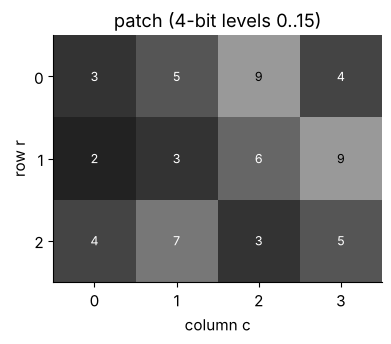

N = 12 | sorted values: [2 3 3 3 4 4 5 5 6 7 9 9]


In [14]:
patch = np.array([[3, 5, 9, 4],
                  [2, 3, 6, 9],
                  [4, 7, 3, 5]], dtype=np.uint8)
values = patch.ravel().astype(np.int64)        # the dataset x_1..x_N (as wide integers, for safe arithmetic)

fig, ax = plt.subplots(figsize=(4.4, 3.2))
show_pixels(patch, ax, "patch (4-bit levels 0..15)", vmin=0, vmax=15)
plt.show()
print("N =", values.size, "| sorted values:", np.sort(values))

### 2.1 Mean, median and mode

* **Mean** (average): $\displaystyle \mu = \frac{1}{N}\sum_{i=1}^{N} x_i$.
* **Median**: sort the values as $x_{(1)} \le x_{(2)} \le \dots \le x_{(N)}$ (the subscript in parentheses means "the $k$-th smallest"). If $N$ is odd, the median is the middle value $x_{((N+1)/2)}$. If $N$ is even, the convention is the **average of the two middle values**, $\tfrac12\big(x_{(N/2)} + x_{(N/2+1)}\big)$.
* **Mode**: the most frequent value. There can be several (a *multimodal* dataset).

**By hand.** Sorted: $2, 3, 3, 3, 4, 4, 5, 5, 6, 7, 9, 9$.

* Sum $= 60$, so $\mu = 60 / 12 = 5$.
* $N = 12$ is even, so the median averages the 6th and 7th values: $m = (4 + 5)/2 = 4.5$.
* The value 3 appears three times (more than any other), so the mode is $3$.
* The **range** (max minus min) is $9 - 2 = 7$.

Notice the order $\text{mode} < \text{median} < \text{mean}$. That ordering is *typical* of a **right-skewed** dataset (a rule of thumb, not a law: it can fail, especially for discrete or multimodal data): a few large values (the two 9s) form a long right tail that pulls the mean up, while the median only cares about the middle of the sorted list.

In [15]:
counts = np.bincount(values, minlength=16)               # counts[v] = how many pixels have value v
print("mean   :", values.mean())
print("median :", np.median(values))
print("mode   :", counts.argmax(), "(appears", counts.max(), "times)")
print("range  :", values.max() - values.min())

tied = pd.Series([1, 1, 2, 2, 3])                        # two values tie for most frequent
print("\nwith a tie, np.bincount(...).argmax() returns only the smallest mode:", np.bincount(tied).argmax())
print("pandas returns every mode:", tied.mode().tolist(), "| scipy.stats.mode:", stats.mode(tied.to_numpy()).mode)

mean   : 5.0
median : 4.5
mode   : 3 (appears 3 times)
range  : 7

with a tie, np.bincount(...).argmax() returns only the smallest mode: 1
pandas returns every mode: [1, 2] | scipy.stats.mode: 1


### 2.2 Each "average" answers a different question

Why have three notions of center? Because each one is the **best single guess** under a different way of scoring mistakes. Suppose you must summarize all pixels by one number $c$:

* If a guess off by $d$ costs $d^2$ (squared error), the best $c$ minimizes $f(c) = \sum_i (x_i - c)^2$. Setting the derivative to zero,
$$
f'(c) = -2 \sum_i (x_i - c) = 0 \iff c = \frac{1}{N}\sum_i x_i = \mu .
$$
Since $f''(c) = 2N > 0$, this is a minimum. Along the way we learned that $\sum_i (x_i - \mu) = 0$: the mean is the **balance point** where positive and negative deviations cancel exactly.
* If a guess off by $d$ costs $|d|$ (absolute error), the best $c$ minimizes $g(c) = \sum_i |x_i - c|$. Away from data points, the slope of $g$ is (number of points below $c$) $-$ (number of points above $c$). The slope is negative while more points lie above $c$ and positive once more lie below, so $g$ is smallest where the two counts balance: at the **median**. For even $N$, *every* $c$ between the two middle values gives the same minimum (the slope there is exactly $0$), and "average the middle two" is just a convention for picking one.
* If any wrong guess costs 1 and a correct guess costs 0, you should guess the most frequent value: the **mode**.

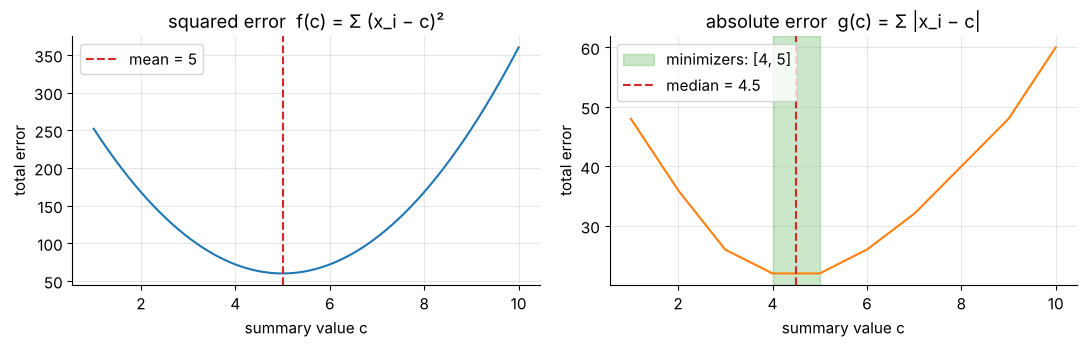

f is minimized at c = 5.0 | g is minimized on the whole interval [4.0, 5.0]


In [16]:
c_grid = np.linspace(1, 10, 901)
sse = ((values[None, :] - c_grid[:, None]) ** 2).sum(axis=1)       # f(c) for every c on the grid
sae = np.abs(values[None, :] - c_grid[:, None]).sum(axis=1)        # g(c) for every c on the grid

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(c_grid, sse)
axes[0].axvline(values.mean(), color="C3", ls="--", label=f"mean = {values.mean():g}")
axes[0].set_title("squared error  f(c) = Σ (x_i − c)²")
axes[1].plot(c_grid, sae, color="C1")
flat = c_grid[np.isclose(sae, sae.min())]
axes[1].axvspan(flat.min(), flat.max(), color="C2", alpha=0.25, label=f"minimizers: [{flat.min():g}, {flat.max():g}]")
axes[1].axvline(np.median(values), color="C3", ls="--", label=f"median = {np.median(values):g}")
axes[1].set_title("absolute error  g(c) = Σ |x_i − c|")
for ax in axes:
    ax.set_xlabel("summary value c")
    ax.set_ylabel("total error")
    ax.legend()
fig.tight_layout()
plt.show()
print("f is minimized at c =", round(float(c_grid[sse.argmin()]), 3),
      "| g is minimized on the whole interval", [float(flat.min()), float(flat.max())])

The left curve is a parabola with its bottom exactly at the mean. The right curve is piecewise linear with a **flat bottom** between the two middle values 4 and 5, exactly as the slope argument predicted.

> **Olympiad tip.** This is why a regression model trained with mean squared error learns to predict a (conditional) **mean**, while one trained with mean absolute error learns a (conditional) **median**. The loss function decides which "average" you get.

### 2.3 Spread: range, variance and standard deviation

The **range** depends only on the two most extreme pixels, so one faulty pixel can change it completely. A better measure uses every deviation $x_i - \mu$. Their plain average is useless (it is always $0$, as we just proved), so we average their **squares**:

$$
\sigma^2 = \operatorname{Var}(X) = \frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2, \qquad \sigma = \sqrt{\sigma^2}.
$$

$\sigma^2$ is the **variance** (measured in *squared* gray levels) and $\sigma$ is the **standard deviation** (back in gray levels, the same unit as the data). For images, $\sigma$ is a simple measure of **contrast**: a flat gray patch has $\sigma = 0$, a patch of black and white pixels has a large $\sigma$.

**By hand.** Group equal values, so each squared deviation is computed once and multiplied by its count:

| value $x$ | count | $x - \mu$ | $(x-\mu)^2$ | count $\times (x-\mu)^2$ |
|---|---|---|---|---|
| 2 | 1 | $-3$ | 9 | 9 |
| 3 | 3 | $-2$ | 4 | 12 |
| 4 | 2 | $-1$ | 1 | 2 |
| 5 | 2 | $0$ | 0 | 0 |
| 6 | 1 | $1$ | 1 | 1 |
| 7 | 1 | $2$ | 4 | 4 |
| 9 | 2 | $4$ | 16 | 32 |
| **total** | **12** | | | **60** |

So $\sigma^2 = 60/12 = 5$ and $\sigma = \sqrt 5 \approx 2.2361$.

**The shortcut formula.** Expanding the square gives an alternative that is handy by hand:

$$
\sigma^2 = \frac1N\sum_i x_i^2 - \frac{2\mu}{N}\sum_i x_i + \mu^2 = \underbrace{\frac1N\sum_i x_i^2}_{E[X^2]} - \mu^2 .
$$

Here $E[X^2] = (4 + 27 + 32 + 50 + 36 + 49 + 162)/12 = 360/12 = 30$, so $\sigma^2 = 30 - 5^2 = 5$, as before.

In [17]:
levels, cnt = np.unique(values, return_counts=True)
mu = values.mean()
table = pd.DataFrame({"value x": levels, "count": cnt, "x - mu": levels - mu,
                      "(x - mu)^2": (levels - mu) ** 2, "count * (x - mu)^2": cnt * (levels - mu) ** 2})
display(table)
print("sum of count*(x-mu)^2 =", table["count * (x - mu)^2"].sum())
print("variance (two-pass)   =", np.var(values), "| std =", round(float(np.std(values)), 4))
print("shortcut E[X^2] - mu^2 =", (values ** 2).mean(), "-", mu ** 2, "=", (values ** 2).mean() - mu ** 2)

,value x,count,x - mu,(x - mu)^2,count * (x - mu)^2
0,2,1,-3.0,9.0,9.0
1,3,3,-2.0,4.0,12.0
2,4,2,-1.0,1.0,2.0
3,5,2,0.0,0.0,0.0
4,6,1,1.0,1.0,1.0
5,7,1,2.0,4.0,4.0
6,9,2,4.0,16.0,32.0


sum of count*(x-mu)^2 = 60.0
variance (two-pass)   = 5.0 | std = 2.2361
shortcut E[X^2] - mu^2 = 30.0 - 25.0 = 5.0


### 2.4 A numerical trap in the shortcut formula

The shortcut $E[X^2] - \mu^2$ is exact in algebra but dangerous on a computer. When the values sit far from zero (say around $10^4$) but vary only a little, $E[X^2]$ and $\mu^2$ are two **huge, nearly equal** numbers, and subtracting them cancels almost all significant digits (*catastrophic cancellation*). `float32` keeps only about 7 significant decimal digits, so the leftover can be pure rounding noise. The two-pass formula (first compute $\mu$, then average $(x_i - \mu)^2$) never forms the huge numbers, which is why `np.var` uses it.

In [18]:
rows_out = []
for offset in [0, 10_000, 1_000_000]:
    x32 = (values + offset).astype(np.float32)          # same spread, shifted far from zero
    shortcut = float((x32 ** 2).mean() - x32.mean() ** 2)
    rows_out.append({"offset": offset, "shortcut E[X^2]-mu^2 (float32)": shortcut,
                     "two-pass np.var (float32)": float(np.var(x32)), "true variance": 5.0})
display(pd.DataFrame(rows_out))

,offset,shortcut E[X^2]-mu^2 (float32),two-pass np.var (float32),true variance
0,0,5.0,5.0,5.0
1,10000,0.0,5.0,5.0
2,1000000,65536.0,5.0,5.0


Shifting every value by a constant does not change the spread, so the true variance stays 5. The shortcut formula in `float32` returns garbage once the offset is large (it can even return a *negative* "variance" for other data), while the two-pass computation stays exact.

> **Going deeper.** If data arrive one value at a time (a video stream) and you cannot store them all, use **Welford's online algorithm**, which updates the mean and the sum of squared deviations with each new value and is as stable as the two-pass method.

**Quick check 2.** Every pixel of an image is (a) increased by 10, or (b) multiplied by 2. What happens to the mean, the median, the variance and the standard deviation in each case?

<details>
<summary>Answer</summary>

(a) Adding a constant shifts every value and the center with it: mean and median increase by 10, while every deviation $x_i - \mu$ is unchanged, so variance and standard deviation do **not** change.
(b) Scaling by 2 doubles the mean, the median and every deviation, so the standard deviation doubles and the variance (built from *squared* deviations) is multiplied by $2^2 = 4$.
In general, for $Y = aX + b$: $\mu_Y = a\mu_X + b$, $\sigma_Y^2 = a^2\sigma_X^2$, $\sigma_Y = |a|\,\sigma_X$.
</details>

## 3. Population versus sample variance (Bessel's correction)

### 3.1 Describing versus estimating

There are two different jobs that both get called "computing the variance", and they need different formulas.

1. **Describing a population.** The $N$ values are *everything* you care about: the 12 pixels of this patch, all pixels of the image on your screen, the 8 pixels an exam question gives you "as the whole population". Then
$$
\sigma^2 = \frac{1}{N}\sum_{i=1}^{N}(x_i - \mu)^2
$$
is simply a fact about those numbers. It is also exactly $\operatorname{Var}(X)$ for "pick one of the pixels uniformly at random" (we verify this in Section 5.3). Nothing is being estimated.
2. **Estimating from a sample.** The $n$ values are a random **sample** from a larger population whose variance you want: 16 video frames used to measure a camera's noise, 50 pixels sampled from a gigantic microscope scan, 30 parts measured from a production line of millions. You do not know the true mean $\mu$ either, so you replace it by the sample mean $\bar x = \frac1n\sum_i x_i$, and the right formula becomes
$$
s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar x)^2 .
$$

Convention: Greek letters ($\mu$, $\sigma^2$) for population quantities, Latin letters ($\bar x$, $s^2$) for numbers computed from a sample. $s^2$ is the **sample variance** and $s$ the **sample standard deviation**. Replacing $n$ by $n - 1$ is called **Bessel's correction**. For our patch, $\sigma^2 = 60/12 = 5$ while $s^2 = 60/11 \approx 5.4545$.

### 3.2 Why $n - 1$? A proof in two steps

Let $X_1, \dots, X_n$ be independent draws from a population with mean $\mu$ and variance $\sigma^2$, and let $\bar X = \frac1n\sum_i X_i$.

**Step 1 (pure algebra).** Write $X_i - \mu = (X_i - \bar X) + (\bar X - \mu)$ and square:

$$
\sum_{i=1}^n (X_i - \mu)^2 = \sum_{i=1}^n (X_i - \bar X)^2 + 2(\bar X - \mu)\underbrace{\sum_{i=1}^n (X_i - \bar X)}_{=\,0} + n(\bar X - \mu)^2 .
$$

The middle sum is zero because deviations from the mean always cancel (Section 2.2). Rearranging,

$$
\sum_{i=1}^n (X_i - \bar X)^2 = \sum_{i=1}^n (X_i - \mu)^2 - n(\bar X - \mu)^2 . \tag{1}
$$

So squared deviations measured from $\bar X$ are **never larger** than those measured from the true $\mu$. That is no accident: $\bar X$ is exactly the number that minimizes the sum of squared deviations *for this sample* (Section 2.2), so it fits the sample better than the true mean does.

**Step 2 (expectations).** Take the average of (1) over all possible samples:

* Each $(X_i - \mu)^2$ has expected value $\sigma^2$ by definition, so the first sum has expected value $n\sigma^2$.
* For independent draws, variances add: $\operatorname{Var}\big(\sum_i X_i\big) = n\sigma^2$, hence $\operatorname{Var}(\bar X) = \frac{1}{n^2}\, n\sigma^2 = \frac{\sigma^2}{n}$. Therefore $E\big[n(\bar X - \mu)^2\big] = n \cdot \frac{\sigma^2}{n} = \sigma^2$.

Putting the pieces together:

$$
E\Big[\sum_{i=1}^n (X_i - \bar X)^2\Big] = n\sigma^2 - \sigma^2 = (n-1)\,\sigma^2 .
$$

Dividing the sum by $n - 1$ therefore gives an estimator whose average is exactly $\sigma^2$: $E[s^2] = \sigma^2$, which statisticians call **unbiased**. Dividing by $n$ instead gives an average of $\frac{n-1}{n}\sigma^2$: systematically too small, by half when $n = 2$.

> **Intuition.** The $n$ deviations $x_i - \bar x$ must add up to zero, so once you know $n - 1$ of them the last one is forced. Only $n - 1$ of them carry independent information about the spread, and we say one **degree of freedom** was spent on estimating the mean. With $n = 1$ there is no information about spread at all: dividing by $n$ would claim the spread is $0$, while dividing by $n - 1$ gives $0/0$, an honest "cannot tell".

### 3.3 Seeing the bias in a simulation

Let's check the theory. We build a large "population": the 1,000,000 pixels of a synthetic inspection image (mostly background around gray level 100, plus 15% brighter defect pixels), compute its true variance $\sigma^2$, and then draw 100,000 random samples of size $n$ (with replacement, so the draws are independent). For each sample we compute both the divide-by-$n$ and the divide-by-$(n-1)$ estimates and average them.

In [19]:
N_POP = 1_000_000
is_defect = rng.random(N_POP) < 0.15
population = np.where(is_defect, rng.normal(150, 25, N_POP), rng.normal(100, 10, N_POP))
population = to_uint8(population)
sigma2 = population.var()                      # the TRUE population variance (divide by N)
print(f"population: N = {N_POP:,} pixels, mean = {population.mean():.2f}, variance sigma^2 = {sigma2:.2f}")

T = 100_000                                     # number of simulated samples for each n
ns = [2, 3, 4, 5, 6, 8, 10, 15, 20, 30]
sim_rows = []
for n in ns:
    samples = population[rng.integers(0, N_POP, size=(T, n))].astype(np.float64)
    ss = ((samples - samples.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)   # sum of squared deviations
    sim_rows.append({"n": n, "E[÷n] / σ²": (ss / n).mean() / sigma2, "theory (n-1)/n": (n - 1) / n,
                     "E[÷(n-1)] / σ²": (ss / (n - 1)).mean() / sigma2,
                     "P(s² < σ²)": ((ss / (n - 1)) < sigma2).mean()})
    if n == 5:
        s2_n5 = ss / (n - 1)                     # keep these for the histogram below
sim = pd.DataFrame(sim_rows).set_index("n")
display(sim.round(4))

population: N = 1,000,000 pixels, mean = 107.52, variance sigma^2 = 497.92


,E[÷n] / σ²,theory (n-1)/n,E[÷(n-1)] / σ²,P(s² < σ²)
n,,,,
2,0.4983,0.5000,0.9967,0.7793
3,0.6670,0.6667,1.0006,0.7193
4,0.7515,0.7500,1.0020,0.6722
5,0.8030,0.8000,1.0037,0.6391
6,0.8285,0.8333,0.9942,0.6208
8,0.8780,0.8750,1.0035,0.5894
10,0.8994,0.9000,0.9993,0.5766
15,0.9384,0.9333,1.0054,0.5556
20,0.9470,0.9500,0.9968,0.5534


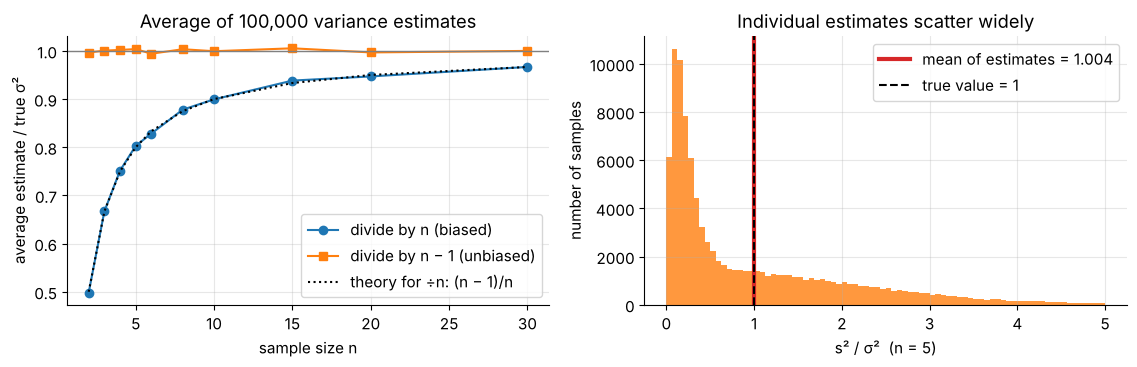

n = 5: 68.9% of the estimates are off by more than a factor of 2


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
axes[0].plot(sim.index, sim["E[÷n] / σ²"], "o-", label="divide by n (biased)")
axes[0].plot(sim.index, sim["E[÷(n-1)] / σ²"], "s-", label="divide by n − 1 (unbiased)")
axes[0].plot(sim.index, sim["theory (n-1)/n"], "k:", label="theory for ÷n: (n − 1)/n")
axes[0].axhline(1, color="gray", lw=1)
axes[0].set_xlabel("sample size n")
axes[0].set_ylabel("average estimate / true σ²")
axes[0].set_title("Average of 100,000 variance estimates")
axes[0].legend()
axes[1].hist(s2_n5 / sigma2, bins=80, range=(0, 5), color="C1", alpha=0.8)
axes[1].axvline((s2_n5 / sigma2).mean(), color="C3", lw=3, label=f"mean of estimates = {(s2_n5 / sigma2).mean():.3f}")
axes[1].axvline(1, color="k", ls="--", label="true value = 1")
axes[1].set_xlabel("s² / σ²  (n = 5)")
axes[1].set_ylabel("number of samples")
axes[1].set_title("Individual estimates scatter widely")
axes[1].legend()
fig.tight_layout()
plt.show()
ratio5 = s2_n5 / sigma2
print(f"n = 5: {np.mean((ratio5 < 0.5) | (ratio5 > 2)):.1%} of the estimates are off by more than a factor of 2")

The divide-by-$n$ averages sit right on the theoretical curve $(n-1)/n$, far below 1 for small samples, while the divide-by-$(n-1)$ averages hover around 1 for every $n$ (the small wiggles are simulation noise). The right panel adds a sober lesson: *unbiased* only means "correct on average". A single $s^2$ from 5 values can easily be off by a factor of 2 or more, and the last column of the table shows that for this skewed population $s^2$ is actually *below* $\sigma^2$ more often than not. The average comes out right only because the rare overestimates are large.

### 3.4 Which formula does your library use?

Software disagrees on the default, and nothing warns you. The parameter `ddof` ("delta degrees of freedom") sets the divisor to $N - \text{ddof}$.

| tool | default divisor | how to get the other one |
|---|---|---|
| `np.var`, `np.std` | $N$ (`ddof=0`) | `ddof=1` |
| pandas `Series.var()`, `.std()`, `DataFrame.describe()` | $n-1$ (`ddof=1`) | `ddof=0` |
| Python `statistics` | `pvariance`, `pstdev`: $N$, and `variance`, `stdev`: $n-1$ | (two functions) |
| PyTorch `torch.var`, `torch.std` | $n-1$ (`correction=1`) | `correction=0` |
| spreadsheets | `VAR.P`: $N$, `VAR.S`: $n-1$ | (two functions) |

In [21]:
s = pd.Series(values)
print("np.var(values)             =", np.var(values), "   (divide by N)")
print("np.var(values, ddof=1)     =", round(float(np.var(values, ddof=1)), 4), "(divide by N - 1)")
print("pd.Series(values).var()    =", round(s.var(), 4), "(pandas defaults to N - 1!)")
print("statistics.pvariance       =", statistics.pvariance(values.tolist()))
print("statistics.variance        =", round(statistics.variance(values.tolist()), 4))
print("std: numpy", round(float(np.std(values)), 4), "| pandas", round(s.std(), 4))

np.var(values)             = 5.0    (divide by N)
np.var(values, ddof=1)     = 5.4545 (divide by N - 1)
pd.Series(values).var()    = 5.4545 (pandas defaults to N - 1!)
statistics.pvariance       = 5
statistics.variance        = 5.4545
std: numpy 2.2361 | pandas 2.3355


> **Common pitfall.** Mixing NumPy and pandas silently changes your numbers: `df["x"].std()` and `np.std(df["x"].to_numpy())` differ. In an exam, read which variance is requested. "The 8 pixels are the whole population" means divide by 8, while "estimate the variance of the process from these 8 measurements" means divide by 7.

> **Going deeper.** (1) Even though $s^2$ is unbiased for $\sigma^2$, the sample standard deviation $s$ is slightly **biased low** for $\sigma$, because the square root is concave: $E[s] \le \sqrt{E[s^2]} = \sigma$ (Jensen's inequality). (2) Unbiased is not the same as "most accurate": for normally distributed data, dividing by $n+1$ gives the smallest mean squared error, trading a little bias for less variance. (3) If you sample *without* replacement from a finite population of size $N$, then $s^2$ is unbiased for $\frac{N}{N-1}\sigma^2$ rather than for $\sigma^2$, and for large $N$ the difference is negligible.

**Quick check 3.** Divide by $N$ or by $n - 1$?
(a) You report the contrast (standard deviation) of the whole image you are displaying.
(b) You record one pixel in 16 frames of an empty, static scene to estimate the camera's noise level.
(c) A problem says: "treat the 8 pixels as the entire population".
(d) You measure the brightness of 10 bulbs to estimate the variability of all bulbs the factory makes.

<details>
<summary>Answer</summary>

(a) $N$: you describe the image itself. (b) $n - 1$: the 16 values are a sample of the camera's random noise and you want the noise level of the process. (c) $N$, as instructed. (d) $n - 1$: the 10 bulbs are a sample from a much larger population.
</details>

#### ✏️ Exercise 3: both variances from scratch

Implement `variances(x)` that returns the pair `(population_variance, sample_variance)` for a 1-D array, using only sums (no `np.var`, `np.std`, pandas or `statistics`). For a single value the sample variance is undefined: return `float("nan")` for it.

In [22]:
# ✏️ Exercise 3: population and sample variance
def variances(x):
    """Return (population variance, sample variance) of a 1-D array x as Python floats."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    pop_v, samp_v = variances(np.array([3, 5, 9, 4, 2, 3, 6, 9, 4, 7, 3, 5]))
    assert np.isclose(pop_v, 5.0), f"population variance of the patch should be 5.0, got {pop_v}"
    assert np.isclose(samp_v, 60 / 11), f"sample variance of the patch should be 60/11, got {samp_v}"
    r = np.random.default_rng(1)
    for n in [2, 7, 50]:
        x = r.normal(100, 15, n)
        p_, s_ = variances(x)
        assert np.isclose(p_, np.var(x)) and np.isclose(s_, np.var(x, ddof=1)), f"wrong result for n = {n}"
    p1, s1 = variances(np.array([42.0]))
    assert p1 == 0.0 and np.isnan(s1), f"for one value expected (0.0, nan), got {(p1, s1)}"
    big = np.array([255, 255, 0, 0], dtype=np.uint8)              # uint8 input must not wrap
    assert np.isclose(variances(big)[0], 127.5 ** 2), "uint8 input: convert to float before squaring"


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def variances(x):
    x = np.asarray(x, dtype=np.float64)      # widen first: squaring uint8 would wrap
    n = x.size
    ss = ((x - x.sum() / n) ** 2).sum()     # two-pass: deviations first, then squares
    return float(ss / n), (float(ss / (n - 1)) if n > 1 else float("nan"))
```
Both estimates share the same sum of squared deviations, and only the divisor differs. Converting to `float64` first avoids `uint8` wraparound when squaring.
</details>

## 4. Quantiles, outliers and robust statistics

### 4.1 Quantiles and percentiles, and why tools disagree

The median splits the sorted data in half. Generalize: the **$q$-quantile** (for $0 \le q \le 1$) is a value with a fraction $q$ of the data at or below it. Multiply by 100 and it is called a **percentile**: the 0.9-quantile is the 90th percentile. The **quartiles** are $Q_1$ (25%), $Q_2$ (50%, the median) and $Q_3$ (75%).

For a whole population with cumulative distribution $F(x) = P(X \le x)$ (Section 5), the cleanest definition is

$$
Q(q) = \min\{x : F(x) \ge q\} ,
$$

the smallest value whose cumulative probability reaches $q$ (the **inverted CDF**). For a finite sample there is a snag: $q \cdot n$ is rarely a whole number, so "the value with 75% of the data below it" usually falls *between* two data points, and there is no single right answer. Hyndman and Fan (1996) catalogued nine conventions in use, and NumPy implements all nine through `np.quantile(x, q, method=...)`.

**NumPy's default, `method="linear"`** (also the default of pandas and R, and the rule used by the spreadsheet function `PERCENTILE.INC`): sort the data as $x_{(0)} \le \dots \le x_{(n-1)}$ (**0-based** positions), then

$$
h = (n-1)\,q, \qquad j = \lfloor h \rfloor, \qquad g = h - j, \qquad Q(q) = x_{(j)} + g\,\big(x_{(j+1)} - x_{(j)}\big).
$$

In words: find the fractional position $h$ in the sorted list and interpolate linearly between its two neighbors.

**By hand** (patch, $n = 12$, sorted: $2,3,3,3,4,4,5,5,6,7,9,9$, so $x_{(0)} = 2, \dots, x_{(11)} = 9$):

| $q$ | $h = 11q$ | neighbors $x_{(j)}, x_{(j+1)}$ | linear $Q(q)$ | inverted CDF |
|---|---|---|---|---|
| 0.25 | 2.75 | 3, 3 | $3 + 0.75 \cdot 0 = 3$ | 3 |
| 0.50 | 5.5 | 4, 5 | $4 + 0.5 \cdot 1 = 4.5$ | 4 |
| 0.75 | 8.25 | 6, 7 | $6 + 0.25 \cdot 1 = 6.25$ | 6 |
| 0.90 | 9.9 | 7, 9 | $7 + 0.9 \cdot 2 = 8.8$ | 9 |

For the inverted-CDF column use the cumulative fractions: $F(6) = 9/12 = 0.75 \ge 0.75$, so $Q(0.75) = 6$, while $F(7) = 10/12 \approx 0.83 < 0.9 \le F(9) = 1$, so $Q(0.9) = 9$.

In [23]:
methods = ["linear", "lower", "higher", "nearest", "midpoint", "inverted_cdf", "weibull", "hazen", "median_unbiased"]
qs = [0.25, 0.5, 0.75, 0.9]
qtable = pd.DataFrame({m: [float(np.quantile(values, q, method=m)) for q in qs] for m in methods},
                      index=[f"q = {q}" for q in qs]).T
display(qtable.round(3))
print("pandas default:", pd.Series(values).quantile([0.75, 0.9]).tolist(), "(same as NumPy 'linear')")

,q = 0.25,q = 0.5,q = 0.75,q = 0.9
linear,3.0,4.5,6.250,8.8
lower,3.0,4.0,6.000,7.0
higher,3.0,5.0,7.000,9.0
nearest,3.0,5.0,6.000,9.0
midpoint,3.0,4.5,6.500,8.0
inverted_cdf,3.0,4.0,6.000,9.0
weibull,3.0,4.5,6.750,9.0
hazen,3.0,4.5,6.500,9.0
median_unbiased,3.0,4.5,6.583,9.0


pandas default: [6.25, 8.8] (same as NumPy 'linear')


On 12 values, the 90th percentile is 7, 8, 8.8 or 9 depending on the convention. With thousands of pixels the conventions nearly agree, but on exam-sized data they do not, so always state (or read) which one is meant. When nothing is said, NumPy's linear rule is the safe default in code. Note also the 0-based position $h = (n-1)q$: using $nq$ or $(n+1)q$ silently switches to a different convention.

### 4.2 Five-number summary, IQR and box plots

The **five-number summary** (min, $Q_1$, median, $Q_3$, max) describes a dataset compactly, and a **box plot** draws it. The **interquartile range** $\text{IQR} = Q_3 - Q_1$ is the width of the middle half of the data. **Tukey's rule** flags values outside the *fences*

$$
\big[\,Q_1 - 1.5\,\text{IQR},\;\; Q_3 + 1.5\,\text{IQR}\,\big]
$$

as potential outliers. For the patch: $Q_1 = 3$, $Q_3 = 6.25$, $\text{IQR} = 3.25$, fences $[3 - 4.875,\; 6.25 + 4.875] = [-1.875,\; 11.125]$, so nothing is flagged.

### 4.3 What a single bad pixel does

Real sensors have **hot pixels**: cells stuck near maximum brightness. Replace one of the 9s in our patch by a stuck value of 15 and compare the summaries. We also need one new robust measure of spread, the **median absolute deviation**

$$
\text{MAD} = \operatorname{median}_i\, \big|x_i - \operatorname{median}(x)\big| .
$$

For the patch, the absolute deviations from $4.5$ are $0.5$ (four times), $1.5$ (four times), $2.5$ (twice) and $4.5$ (twice). Their median is $\text{MAD} = 1.5$. For normally distributed data $\text{MAD} \approx 0.6745\,\sigma$, so $\hat\sigma = 1.4826 \cdot \text{MAD}$ estimates the standard deviation (here $1.4826 \times 1.5 \approx 2.22$, close to $\sigma \approx 2.24$).

In [24]:
hot = values.copy()
hot[2] = 15                                     # the 9 at row 0, column 2 becomes a stuck pixel


def summarize(x):
    """Classic and robust summaries of a 1-D array."""
    med = np.median(x)
    q1, q3 = np.quantile(x, [0.25, 0.75])
    return {"mean": x.mean(), "median": med, "std (÷N)": x.std(), "MAD": np.median(np.abs(x - med)),
            "1.4826·MAD": 1.4826 * np.median(np.abs(x - med)), "IQR": q3 - q1, "range": np.ptp(x)}


display(pd.DataFrame({"original patch": summarize(values), "with hot pixel 15": summarize(hot)}).T.round(4))

z_classic = (hot - hot.mean()) / hot.std()                                    # uses mean and std
z_modified = 0.6745 * (hot - np.median(hot)) / np.median(np.abs(hot - np.median(hot)))   # uses median and MAD
print("classic z-score of the hot pixel  :", round(z_classic[2], 4), "-> NOT flagged by the rule |z| > 3")
print("modified z-score of the hot pixel :", round(z_modified[2], 4), "-> flagged by the rule |M| > 3.5")
q1, q3 = np.quantile(hot, [0.25, 0.75])
print("Tukey fences:", [float(q1 - 1.5 * (q3 - q1)), float(q3 + 1.5 * (q3 - q1))], "-> 15 is outside, flagged")

,mean,median,std (÷N),MAD,1.4826·MAD,IQR,range
original patch,5.0,4.5,2.2361,1.5,2.2239,3.25,7.0
with hot pixel 15,5.5,4.5,3.4278,1.5,2.2239,3.25,13.0


classic z-score of the hot pixel  : 2.7714 -> NOT flagged by the rule |z| > 3
modified z-score of the hot pixel : 4.7215 -> flagged by the rule |M| > 3.5
Tukey fences: [-1.875, 11.125] -> 15 is outside, flagged


One wrong pixel out of twelve moved the mean by half a gray level and inflated the standard deviation by more than 50%, while the median, MAD and IQR did not move at all. The z-scores show a subtle trap called **masking**: the classic score $z_i = (x_i - \bar x)/\sigma$ uses a standard deviation that the outlier itself inflated, so the outlier hides behind it ($z = 2.77 < 3$). The **modified z-score**

$$
M_i = \frac{0.6745\,\big(x_i - \operatorname{median}(x)\big)}{\text{MAD}}
$$

is built from robust ingredients, and the common rule $|M_i| > 3.5$ (Iglewicz and Hoaglin) catches it ($M = 4.72$).

The precise way to compare estimators is the **breakdown point**: the smallest fraction of the data that, if replaced by arbitrary garbage, can drag the estimate arbitrarily far.

| estimator | breakdown point | why |
|---|---|---|
| mean, standard deviation, range | $0\%$ (one value suffices) | one huge value dominates the sum |
| IQR | $25\%$ | $Q_3$ survives until a quarter of the data is corrupted |
| median, MAD | $50\%$ | the middle of the sorted list stays honest until half the data is bad |

### 4.4 An experiment: more and more hot pixels

Take a clean $64 \times 64$ texture (gray level about $100 \pm 8$) and turn a growing fraction $\varepsilon$ of its pixels into hot pixels (255). Watch the classic and the robust estimates.

,mean,median,std,1.4826·MAD,IQR/1.349
eps,,,,,
0.00,99.88,99.75,7.92,8.03,8.01
0.01,101.42,99.83,17.34,8.10,8.10
0.02,102.98,99.92,23.09,8.16,8.20
0.05,107.61,100.26,34.70,8.54,8.58
0.10,115.47,100.85,47.14,9.28,9.34
0.20,130.88,102.29,62.45,11.09,12.11
0.30,146.48,104.31,71.36,14.61,117.12
0.40,161.94,107.72,76.21,23.28,116.31
0.45,169.68,110.72,77.40,32.02,115.67


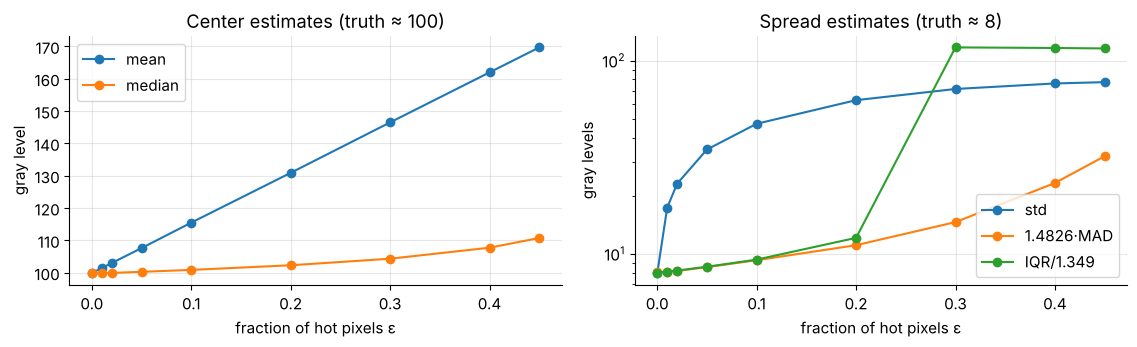

In [25]:
g_contam = np.random.default_rng(7)                       # a local generator keeps this experiment reproducible
texture = g_contam.normal(100, 8, size=64 * 64)
eps_list = [0, 0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.45]
contam_rows = []
for eps in eps_list:
    x = texture.copy()
    hit = g_contam.choice(x.size, size=int(round(eps * x.size)), replace=False)
    x[hit] = 255.0
    med = np.median(x)
    q1, q3 = np.percentile(x, [25, 75])
    contam_rows.append({"eps": eps, "mean": x.mean(), "median": med, "std": x.std(),
                        "1.4826·MAD": 1.4826 * np.median(np.abs(x - med)), "IQR/1.349": (q3 - q1) / 1.349})
contam = pd.DataFrame(contam_rows).set_index("eps")
display(contam.round(2))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
contam[["mean", "median"]].plot(ax=axes[0], marker="o")
axes[0].set_title("Center estimates (truth ≈ 100)")
axes[0].set_ylabel("gray level")
contam[["std", "1.4826·MAD", "IQR/1.349"]].plot(ax=axes[1], marker="o")
axes[1].set_title("Spread estimates (truth ≈ 8)")
axes[1].set_ylabel("gray levels")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("fraction of hot pixels ε")
fig.tight_layout()
plt.show()

With just 1% hot pixels the standard deviation has already more than doubled, and the mean drifts upward linearly with $\varepsilon$. The median and the scaled MAD drift only slowly until $\varepsilon$ approaches 50%. The IQR-based estimate ($\text{IQR}/1.349$ estimates $\sigma$ for normal data) holds up to 20% contamination and then jumps, exactly at its 25% breakdown point: from then on $Q_3$ is itself a hot pixel.

### 4.5 Robust statistics as an image filter: the median filter

Image filters are statistics computed in a small sliding window. A $3 \times 3$ **mean filter** (`cv2.blur`) replaces every pixel by the mean of its 9 neighbors, and a $3\times 3$ **median filter** (`cv2.medianBlur`) uses their median. Against **salt-and-pepper noise** (random pixels forced to 0 or 255, as from transmission errors or dead and hot pixels), the difference is dramatic: an isolated bad pixel is only 1 of 9 values in each window, so it can never become the median, while it always pulls the mean.

Let us create a synthetic **test card** that we will reuse in later sections. It has flat regions, sharp edges, a gentle gradient and fine stripes.

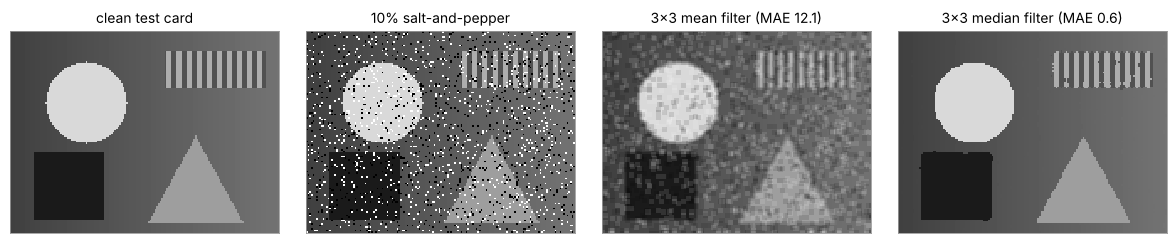

In [26]:
def make_test_card(H=120, W=160):
    """Synthetic test image (floats in [0, 1]): gradient, disc, square, triangle and fine stripes."""
    yy, xx = np.mgrid[0:H, 0:W].astype(float)
    card = 0.25 + 0.2 * xx / (W - 1)                                    # soft left-to-right gradient
    card[(yy - 42) ** 2 + (xx - 45) ** 2 <= 24 ** 2] = 0.85              # bright disc
    card[72:112, 14:56] = 0.10                                           # dark square
    tri = (yy >= 62) & (yy < 114) & (np.abs(xx - 110) <= (yy - 62) * 0.55)
    card[tri] = 0.62                                                     # mid-gray triangle
    stripes = (yy >= 12) & (yy < 34) & (xx >= 92) & (xx < 152)
    card[stripes] = 0.32 + 0.36 * ((xx[stripes] // 3) % 2)               # stripes 3 pixels wide
    return card


card = make_test_card()
clean = to_uint8(255 * card)
noisy = clean.copy()
u = np.random.default_rng(11).random(clean.shape)
noisy[u < 0.05] = 0                                   # 5% pepper
noisy[u > 0.95] = 255                                 # 5% salt
mean_f = cv2.blur(noisy, (3, 3))
median_f = cv2.medianBlur(noisy, 3)


def mae(a, b):
    """Mean absolute error between two images (in gray levels)."""
    return np.abs(a.astype(np.float64) - b.astype(np.float64)).mean()


show_images([clean, noisy, mean_f, median_f],
            ["clean test card", "10% salt-and-pepper", f"3×3 mean filter (MAE {mae(mean_f, clean):.1f})",
             f"3×3 median filter (MAE {mae(median_f, clean):.1f})"], size=3.0)

The mean filter turns every impulse into a gray smudge and softens all edges, while the median filter removes almost every impulse and keeps edges crisp (the mean absolute error to the clean image, shown in the titles, drops from about 12 gray levels to below 1). The thin stripes suffer a little under both filters, since each stripe is only 3 pixels wide and a window can straddle two stripes. Whenever data may contain gross errors, robust statistics are the safer default, and in Section 9 we will use the same "median beats mean" idea to compensate for lighting changes.

#### ✏️ Exercise 4: NumPy's default quantile, from scratch

Implement `quantile_linear(x, q)` following the 0-based linear-interpolation rule of Section 4.1 (for a single `q` between 0 and 1). Do not call `np.quantile`, `np.percentile` or pandas.

In [27]:
# ✏️ Exercise 4: linear-interpolation quantile
def quantile_linear(x, q):
    """Return the q-quantile of the 1-D data x using NumPy's default 'linear' rule."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    v = np.array([3, 5, 9, 4, 2, 3, 6, 9, 4, 7, 3, 5])
    for q, want in [(0.25, 3.0), (0.5, 4.5), (0.75, 6.25), (0.9, 8.8), (0.0, 2.0), (1.0, 9.0)]:
        got = quantile_linear(v, q)
        assert np.isclose(got, want), f"q = {q}: expected {want}, got {got}"
    r = np.random.default_rng(3)
    for n in [1, 2, 5, 40]:
        x = r.normal(0, 1, n)
        for q in [0.1, 0.33, 0.5, 0.99]:
            assert np.isclose(quantile_linear(x, q), np.quantile(x, q)), f"mismatch for n = {n}, q = {q}"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def quantile_linear(x, q):
    s = np.sort(np.asarray(x, dtype=np.float64))
    h = (s.size - 1) * q                  # fractional 0-based position
    j = int(np.floor(h))
    g = h - j
    if j + 1 >= s.size:                   # q = 1 (or n = 1): no right neighbor
        return float(s[-1])
    return float(s[j] + g * (s[j + 1] - s[j]))
```
The only delicate case is the right end: when $h$ is the last position there is no $x_{(j+1)}$, and the answer is simply the maximum.
</details>

#### ✏️ Exercise 5: robust outlier detection

Implement `robust_outliers(x, thresh=3.5)` that returns a boolean array marking the values whose **modified z-score** $|M_i| = |0.6745\,(x_i - \operatorname{median})/\text{MAD}|$ exceeds `thresh`. You may assume $\text{MAD} > 0$.

In [28]:
# ✏️ Exercise 5: modified z-score outliers
def robust_outliers(x, thresh=3.5):
    """Boolean mask of entries of x whose modified z-score exceeds thresh in absolute value."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    v = np.array([3, 5, 15, 4, 2, 3, 6, 9, 4, 7, 3, 5])
    out = robust_outliers(v)
    assert out.dtype == bool and out.shape == v.shape, "return a boolean array with the same shape as x"
    assert out.tolist() == [False, False, True] + [False] * 9, f"only the 15 should be flagged, got {out.tolist()}"
    w = np.array([10.0, 11, 9, 10, 12, 10, 9, 11, 10, -30, 10, 60])
    assert np.flatnonzero(robust_outliers(w)).tolist() == [9, 11], "both a low and a high outlier should be flagged"
    assert robust_outliers(w, thresh=100).sum() == 0, "a huge threshold should flag nothing"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def robust_outliers(x, thresh=3.5):
    x = np.asarray(x, dtype=np.float64)
    med = np.median(x)
    mad = np.median(np.abs(x - med))
    m = 0.6745 * (x - med) / mad
    return np.abs(m) > thresh
```
The median and MAD barely notice the outliers, so the outliers stand out clearly. With the mean and standard deviation they would partly mask themselves.
</details>

## 5. Distributions of pixel values: PMF, CDF and histograms

### 5.1 The PMF and the CDF

Back to the random variable $X$ = "gray level of a pixel chosen uniformly at random". Since $X$ takes whole-number values, its distribution is described by two functions:

* the **probability mass function (PMF)**
$$
p_X(x) = P(X = x) = \frac{\#\{\text{pixels with value } x\}}{N},
$$
* the **cumulative distribution function (CDF)**
$$
F_X(t) = P(X \le t) = \sum_{x \le t} p_X(x) = \frac{\#\{\text{pixels with value} \le t\}}{N}.
$$

The CDF is a running total of the PMF. It starts at $0$ (below the smallest value), never decreases, jumps up by $p_X(x)$ at each value $x$ that occurs, stays flat between them, and ends at $1$. For the patch:

| $x$ | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|---|---|---|---|---|---|---|---|---|
| count | 1 | 3 | 2 | 2 | 1 | 1 | 0 | 2 |
| $p_X(x)$ | 1/12 | 3/12 | 2/12 | 2/12 | 1/12 | 1/12 | 0 | 2/12 |
| $F_X(x)$ | 1/12 | 4/12 | 6/12 | 8/12 | 9/12 | 10/12 | 10/12 | 12/12 |

Every probability about $X$ can be read off the CDF. Because $X$ is integer-valued, the difference between $<$ and $\le$ **matters** (unlike for continuous variables):

| event | formula | patch example |
|---|---|---|
| $X = x$ | $p_X(x) = F(x) - F(x-1)$ | $P(X = 3) = 3/12 = 0.25$ |
| $X \le t$ | $F(t)$ | $P(X \le 3) = 4/12 \approx 0.3333$ |
| $X < t$ | $F(t) - p_X(t) = F(t-1)$ | $P(X < 5) = F(4) = 6/12 = 0.5$ |
| $X > t$ | $1 - F(t)$ | $P(X > 7) = 1 - 10/12 = 2/12$ |
| $X \ge t$ | $1 - F(t-1)$ | $P(X \ge 6) = 1 - F(5) = 4/12$ |
| $a < X \le b$ | $F(b) - F(a)$ | $P(3 < X \le 7) = 10/12 - 4/12 = 0.5$ |

Two more details: the CDF is defined for **every** $t$, including levels that never occur ($p_X(8) = 0$, yet $F(8) = F(7) = 10/12$), and $F(t) = 0$ below the minimum and $1$ at or above the maximum.

> **Common pitfall.** $P(X = x)$ and $P(X \le x)$ are different numbers ($0.25$ versus $0.3333$ for $x = 3$). Exam options love to swap them. If a question writes $F_X(t)$ or "cumulative", it means $\le$.

In [29]:
L_patch = 16                                              # 4-bit image: levels 0..15
pmf = np.bincount(values, minlength=L_patch) / values.size
cdf = np.cumsum(pmf)
display(pd.DataFrame({"count": np.bincount(values, minlength=L_patch), "pmf p(x)": pmf, "cdf F(x)": cdf}).loc[2:9].T.round(4))


def F(t):
    """CDF of the patch at any integer t (works below 0 and above 15 too)."""
    return 0.0 if t < 0 else 1.0 if t >= L_patch else float(cdf[t])


print("P(X = 3)       =", pmf[3], "  vs  P(X <= 3) = F(3) =", round(F(3), 4))
print("P(X < 5)       = F(4)        =", F(4), " | direct count:", np.mean(values < 5))
print("P(X >= 6)      = 1 - F(5)    =", round(1 - F(5), 4), " | direct count:", round(np.mean(values >= 6), 4))
print("P(3 < X <= 7)  = F(7) - F(3) =", round(F(7) - F(3), 4), " | direct count:", np.mean((values > 3) & (values <= 7)))
print("level 8 never occurs: p(8) =", pmf[8], "but F(8) =", round(F(8), 4), "= F(7)")

,2,3,4,5,6,7,8,9
count,1.0000,3.0000,2.0000,2.0000,1.0000,1.0000,0.0000,2.0000
pmf p(x),0.0833,0.2500,0.1667,0.1667,0.0833,0.0833,0.0000,0.1667
cdf F(x),0.0833,0.3333,0.5000,0.6667,0.7500,0.8333,0.8333,1.0000


P(X = 3)       = 0.25   vs  P(X <= 3) = F(3) = 0.3333
P(X < 5)       = F(4)        = 0.5  | direct count: 0.5
P(X >= 6)      = 1 - F(5)    = 0.3333  | direct count: 0.3333
P(3 < X <= 7)  = F(7) - F(3) = 0.5  | direct count: 0.5
level 8 never occurs: p(8) = 0.0 but F(8) = 0.8333 = F(7)


### 5.2 Picturing the PMF and the CDF

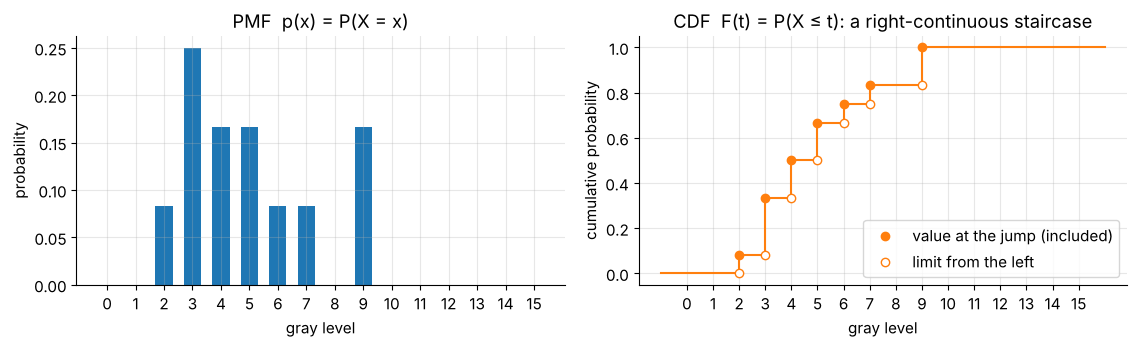

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
xs = np.arange(L_patch)
axes[0].bar(xs, pmf, width=0.6, color="C0")
axes[0].set_title("PMF  p(x) = P(X = x)")
axes[0].set_ylabel("probability")
axes[1].step(np.r_[-1, xs, 16], np.r_[0, cdf, 1], where="post", color="C1")
jumps = np.flatnonzero(pmf)
axes[1].plot(jumps, cdf[jumps], "o", color="C1", label="value at the jump (included)")
axes[1].plot(jumps, cdf[jumps] - pmf[jumps], "o", mfc="white", color="C1", label="limit from the left")
axes[1].set_title("CDF  F(t) = P(X ≤ t): a right-continuous staircase")
axes[1].set_ylabel("cumulative probability")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlabel("gray level")
    ax.set_xticks(range(0, 16))
fig.tight_layout()
plt.show()

Filled dots mark the value of the CDF *at* each jump: because $F(t) = P(X \le t)$ includes the point $t$ itself, the staircase takes the **upper** value at every jump (it is *right-continuous*). The open circles show the value just before the jump, which is $P(X < t)$.

### 5.3 Mean and variance straight from the PMF

Grouping equal values (as in the table of Section 2.3) is the same as weighting each level by its probability:

$$
\mu = E[X] = \sum_x x\,p_X(x), \qquad \sigma^2 = \operatorname{Var}(X) = \sum_x (x - \mu)^2\,p_X(x).
$$

Since $p_X(x) = \text{count}(x)/N$, these are *exactly* the population formulas with divisor $N$. So for "a uniformly chosen pixel", the divide-by-$N$ variance is not a choice or an approximation: it **is** the variance of $X$. The $n-1$ only enters when the pixels are a sample used to estimate something beyond them.

In [31]:
mu_pmf = (xs * pmf).sum()
var_pmf = ((xs - mu_pmf) ** 2 * pmf).sum()
print("E[X] from the PMF   =", round(mu_pmf, 10), "| np.mean =", values.mean())
print("Var(X) from the PMF =", round(var_pmf, 10), "| np.var  =", np.var(values))

E[X] from the PMF   = 5.0 | np.mean = 5.0
Var(X) from the PMF = 5.0 | np.var  = 5.0


### 5.4 Histograms of images

A **histogram** counts how many pixels fall into each *bin* (an interval of values). For an 8-bit image the natural choice is one bin per gray level, 256 bins: `np.bincount(img.ravel(), minlength=256)`, or OpenCV's `cv2.calcHist`. Divide the counts by the number of pixels and you get the empirical PMF, and take the running sum and you get the empirical CDF. *Histogram, PMF and CDF are three views of the same information.*

Let's make a second synthetic image, bright coins on a darker wooden table, whose histogram has two clear humps (we will segment it automatically in Section 8).

np.bincount equals cv2.calcHist: True
19200 pixels, gray levels 37..212, coins cover 23.3% of the image


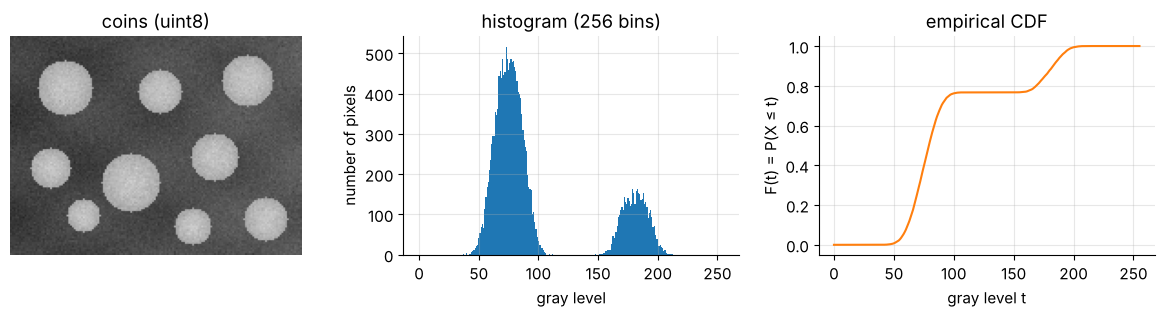

In [32]:
def make_coins(H=120, W=160, noise=6.0, seed=SEED):
    """Synthetic image of bright coins on a darker, textured table. Returns (uint8 image, true coin mask)."""
    g = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:H, 0:W].astype(float)
    img = 62 + 26 * xx / (W - 1) + 10 * np.sin(yy / 9.0) * np.cos(xx / 13.0)   # table: gradient + wood texture
    coin_list = [(28, 30, 15), (30, 82, 12), (24, 130, 14), (72, 22, 11), (80, 66, 16),
                 (66, 112, 13), (100, 140, 12), (104, 100, 10), (98, 40, 9)]      # (row, col, radius)
    truth = np.zeros((H, W), dtype=bool)
    for cy, cx, rad in coin_list:
        d2 = (yy - cy) ** 2 + (xx - cx) ** 2
        disc = d2 <= rad ** 2
        img[disc] = 196 - 30 * d2[disc] / rad ** 2                                # bright center, darker rim
        truth |= disc
    return to_uint8(img + g.normal(0, noise, (H, W))), truth


coins, coins_truth = make_coins()
hist = np.bincount(coins.ravel(), minlength=256)
hist_cv = cv2.calcHist([coins], [0], None, [256], [0, 256]).ravel()
print("np.bincount equals cv2.calcHist:", np.array_equal(hist, hist_cv.astype(int)))
print(f"{coins.size} pixels, gray levels {coins.min()}..{coins.max()}, coins cover {coins_truth.mean():.1%} of the image")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].imshow(coins, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("coins (uint8)")
axes[0].axis("off")
axes[1].bar(np.arange(256), hist, width=1.0)
axes[1].set_title("histogram (256 bins)")
axes[1].set_xlabel("gray level")
axes[1].set_ylabel("number of pixels")
axes[2].plot(np.arange(256), np.cumsum(hist) / coins.size, color="C1")
axes[2].set_title("empirical CDF")
axes[2].set_xlabel("gray level t")
axes[2].set_ylabel("F(t) = P(X ≤ t)")
fig.tight_layout()
plt.show()

The table forms the big hump around 60 to 100, the coins the smaller hump around 170 to 200. In the CDF, each hump becomes a **steep climb** (many pixels per gray level) and the empty valley between them becomes a **flat plateau**. Keep this picture in mind: in Section 7 the CDF itself becomes the contrast-enhancing transformation.

### 5.5 Choosing histogram bins for continuous data

For measurements that are not small integers (brightness averaged over a region, sensor temperatures, model scores), you must choose the bin width $h$, or equivalently the number of bins. This is a classic **bias-variance trade-off**: very wide bins smooth away real structure (two humps merge into one), very narrow bins leave only a few points per bin, so the bar heights become noisy. Common rules for $n$ data points:

| rule | bin width $h$ or number of bins $k$ | comment |
|---|---|---|
| Sturges | $k = \lceil \log_2 n \rceil + 1$ | assumes roughly normal data, so too few bins for large $n$ |
| Scott | $h = 3.49\,\hat\sigma\, n^{-1/3}$ | optimal for normal data, but $\hat\sigma$ is sensitive to outliers |
| Freedman-Diaconis | $h = 2\,\text{IQR}\, n^{-1/3}$ | uses the robust IQR (Section 4) |

All three are built into NumPy: `np.histogram(x, bins="sturges")`, `"scott"`, `"fd"`, or `"auto"` (the larger number of bins of Sturges and FD). Use `density=True` to divide the counts by $n \cdot h$ so that the bars have total **area** 1 and can be compared with a probability density curve.

sturges : 10 bins of width 11.10
scott   :  8 bins of width 13.87
fd      :  9 bins of width 12.33
auto    : 10 bins of width 11.10


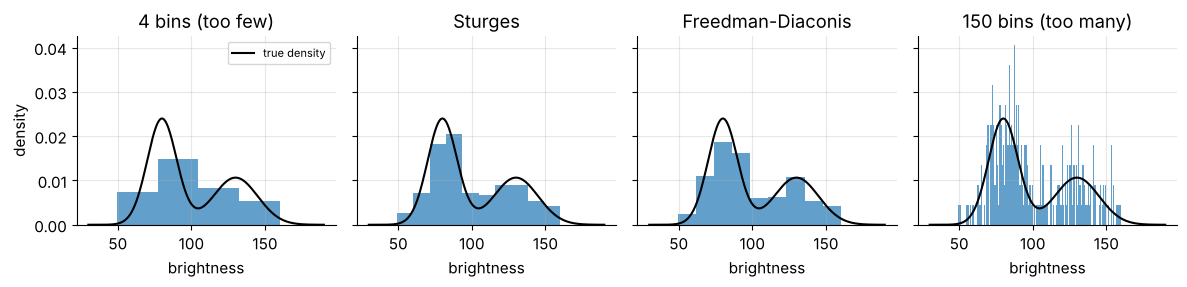

In [33]:
# e.g. the mean brightness of 300 detected objects: 180 dark ones and 120 bright ones
obj_brightness = np.concatenate([rng.normal(80, 10, 180), rng.normal(130, 15, 120)])
for rule in ["sturges", "scott", "fd", "auto"]:
    edges = np.histogram_bin_edges(obj_brightness, bins=rule)
    print(f"{rule:8s}: {len(edges) - 1:2d} bins of width {edges[1] - edges[0]:.2f}")

grid_x = np.linspace(30, 190, 400)
true_pdf = 0.6 * stats.norm.pdf(grid_x, 80, 10) + 0.4 * stats.norm.pdf(grid_x, 130, 15)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.0), sharey=True)
for ax, bins, name in zip(axes, [4, "sturges", "fd", 150], ["4 bins (too few)", "Sturges", "Freedman-Diaconis", "150 bins (too many)"]):
    ax.hist(obj_brightness, bins=bins, density=True, color="C0", alpha=0.7)
    ax.plot(grid_x, true_pdf, "k", lw=1.5, label="true density")
    ax.set_title(name)
    ax.set_xlabel("brightness")
axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

With 4 bins the two groups blur into one lopsided lump, and with 150 bins most bins hold 0 to 3 points and the shape is buried in noise. Sturges and Freedman-Diaconis both reveal the two humps. There is no universally best width, so it is worth trying a couple of values before trusting a histogram's shape.

### 5.6 A trap for integer data: comb artifacts

Pixel values are integers. If the bin width is not a whole number, some bins contain two gray levels and others three, and the histogram grows a fake periodic **comb**. For example, 100 bins over $[0, 256)$ have width $2.56$. The fix is to use integer-width bins whose edges sit **between** integers, for example `np.arange(-0.5, 256, 2)`. (A smaller trap: `np.histogram` treats every bin as half-open $[a, b)$ except the **last**, which is closed $[a, b]$.)

gray levels per bin with 100 bins: (array([2, 3]), array([44, 56]))


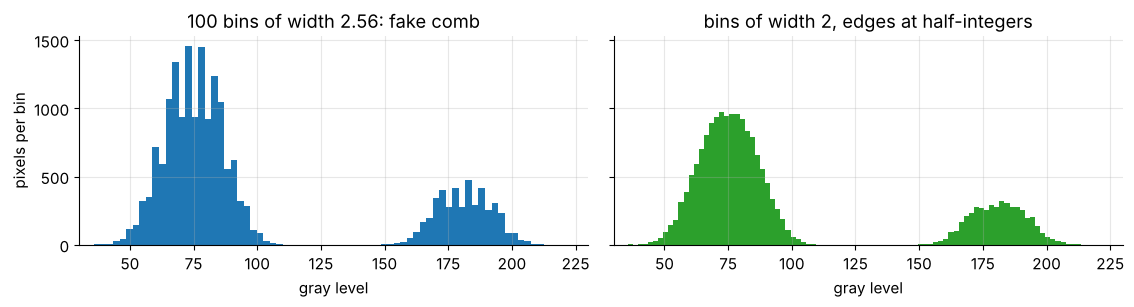

In [34]:
h100, e100 = np.histogram(coins, bins=100, range=(0, 256))
edges2 = np.arange(-0.5, 256, 2)                        # width-2 bins: [-0.5, 1.5), [1.5, 3.5), ...
h2, _ = np.histogram(coins, bins=edges2)
levels_per_bin = np.histogram(np.arange(256), bins=100, range=(0, 256))[0]
print("gray levels per bin with 100 bins:", np.unique(levels_per_bin, return_counts=True))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.2), sharey=True)
axes[0].bar(e100[:-1], h100, width=np.diff(e100), align="edge")
axes[0].set_title("100 bins of width 2.56: fake comb")
axes[1].bar(edges2[:-1], h2, width=2, align="edge", color="C2")
axes[1].set_title("bins of width 2, edges at half-integers")
for ax in axes:
    ax.set_xlim(30, 230)
    ax.set_xlabel("gray level")
axes[0].set_ylabel("pixels per bin")
fig.tight_layout()
plt.show()

**Quick check 4.** Using only the CDF table of Section 5.1, compute $P(4 \le X \le 6)$, $P(X > 5)$, $P(X < 2)$ and $P(X \le 8)$ for the patch.

<details>
<summary>Answer</summary>

$P(4 \le X \le 6) = F(6) - F(3) = 9/12 - 4/12 = 5/12$ (subtract $F(3)$, not $F(4)$, because 4 is included).
$P(X > 5) = 1 - F(5) = 1 - 8/12 = 4/12$.
$P(X < 2) = F(1) = 0$ (no pixel is darker than 2).
$P(X \le 8) = F(8) = 10/12$, the same as $F(7)$ because no pixel has value 8.
</details>

#### ✏️ Exercise 6: PMF and CDF of an image

Implement `pmf_cdf(img, L)` that returns two float arrays of length `L` (the number of gray levels): `pmf[x]` $= P(X = x)$ and `cdf[x]` $= P(X \le x)$ for a pixel chosen uniformly from `img` (any shape, integer values in $0..L-1$).

In [35]:
# ✏️ Exercise 6: empirical PMF and CDF
def pmf_cdf(img, L):
    """Return (pmf, cdf), two float arrays of length L, for the gray levels of img."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    p, c = pmf_cdf(patch, 16)
    assert len(p) == 16 and len(c) == 16, "both arrays must have length L"
    assert np.isclose(p[3], 0.25) and np.isclose(c[3], 4 / 12), f"p(3) should be 0.25 and F(3) = 1/3, got {p[3]}, {c[3]}"
    assert np.isclose(c[8], c[7]) and p[8] == 0, "a level that never occurs has p = 0 and a flat CDF"
    assert np.isclose(c[-1], 1.0) and np.all(np.diff(c) >= -1e-12), "the CDF must end at 1 and never decrease"
    r = np.random.default_rng(5)
    img = r.integers(0, 256, (37, 23), dtype=np.uint8)
    p2, c2 = pmf_cdf(img, 256)
    assert np.allclose(p2 * img.size, np.bincount(img.ravel(), minlength=256)), "pmf times N should equal the counts"
    assert np.allclose(c2, np.cumsum(p2)), "the CDF is the running sum of the PMF"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def pmf_cdf(img, L):
    counts = np.bincount(np.asarray(img).ravel(), minlength=L)[:L]
    pmf = counts / counts.sum()
    return pmf, np.cumsum(pmf)
```
`np.bincount` counts every value at once, and `minlength=L` makes sure that levels which never occur still get a (zero) entry, so `pmf[x]` really refers to gray level `x`.
</details>

## 6. Contrast and point operations

### 6.1 Point operations are lookup tables

A **point operation** changes every pixel using only that pixel's own value: $s = T(r)$, where $r$ is the input gray level and $s$ the output gray level. Position and neighbors play no role. For an 8-bit image there are only 256 possible inputs, so *any* point operation can be stored as a **lookup table (LUT)**: an array `lut` of length 256 with `lut[r] = T(r)`. Applying it is a single fancy-indexing step, `lut[img]` (or `cv2.LUT(img, lut)`), no matter how complicated $T$ is.

Examples: the **negative** $T(r) = 255 - r$, a **brightness shift** $T(r) = \min(r + 60, 255)$, and even **thresholding**, $T(r) = 255$ if $r \ge t$ else $0$, is a point operation (a step-shaped LUT). If $T$ is **increasing**, it preserves the ordering of gray levels: darker stays darker. Everything in this section and in Section 7 is a point operation, and they differ only in *which* table they use.

Our victim is a **foggy** version of the test card: all its values are squeezed into a narrow band of gray levels, so it looks washed out.

foggy: gray levels 95..153 (of 0..255), std = 11.78
lut[img] equals cv2.LUT(img, lut): True


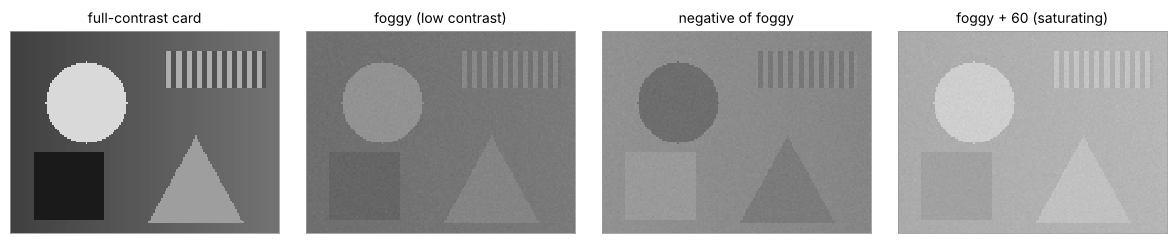

In [36]:
g_fog = np.random.default_rng(21)
foggy = to_uint8(95 + 60 * card + g_fog.normal(0, 2.0, card.shape))     # squeeze into roughly 95..155
dark = to_uint8(70 * card + g_fog.normal(0, 1.5, card.shape))           # an under-exposed version (for 6.3)
print(f"foggy: gray levels {foggy.min()}..{foggy.max()} (of 0..255), std = {foggy.std():.2f}")

r_all = np.arange(256)
lut_negative = (255 - r_all).astype(np.uint8)
lut_brighter = np.minimum(r_all + 60, 255).astype(np.uint8)              # saturate instead of wrapping
neg = lut_negative[foggy]                                                # fancy indexing applies the table
print("lut[img] equals cv2.LUT(img, lut):", np.array_equal(neg, cv2.LUT(foggy, lut_negative)))
show_images([clean, foggy, neg, lut_brighter[foggy]],
            ["full-contrast card", "foggy (low contrast)", "negative of foggy", "foggy + 60 (saturating)"], size=3.0)

Shifting the brightness does not create contrast: the values just move as a block. To make the foggy image use the whole range $0..255$ we need to **stretch** it.

### 6.2 Linear contrast stretching

The simplest stretch maps the darkest value $a$ to $0$ and the brightest value $b$ to $255$ with a straight line, clipping anything outside:

$$
s = \operatorname{clip}\!\left(\frac{r - a}{b - a}\cdot 255,\; 0,\; 255\right).
$$

With $a = \min$ and $b = \max$ this is **min-max normalization** (`cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)`). But you know from Section 4 what the minimum and the maximum are: estimators with a 0% breakdown point. A single hot or dead pixel sets $a = 0$ or $b = 255$, and the stretch does nothing. The robust version uses **percentiles**, typically $a = P_1$ and $b = P_{99}$, and lets the extreme 1% at each end saturate.

min/max of the damaged image: 0, 255  ->  min-max stretch changes nothing
1st/99th percentiles: 99, 149  ->  std before 11.9, after percentile stretch 60.0


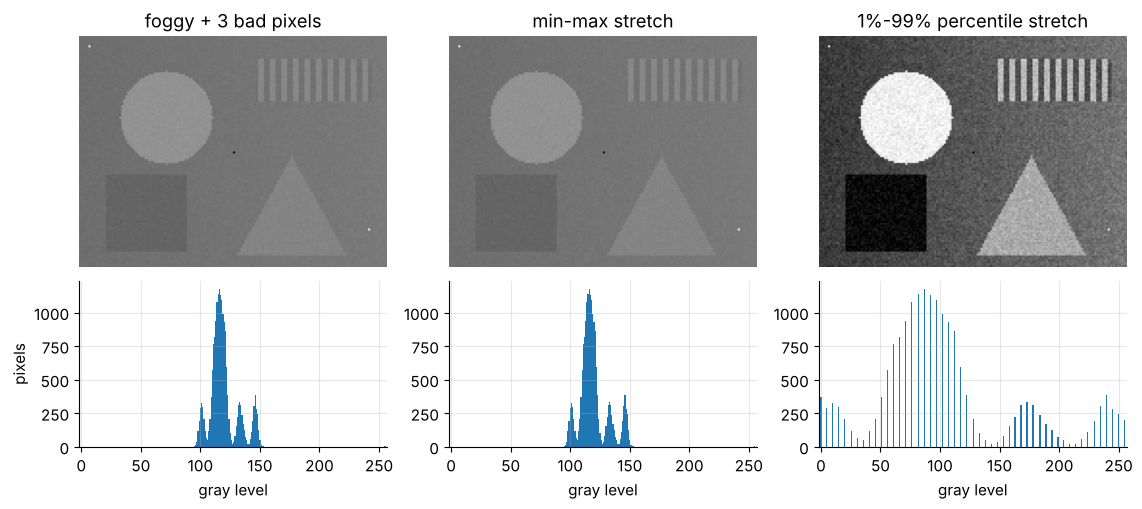

In [37]:
damaged = foggy.copy()
damaged[5, 5] = damaged[100, 150] = 255          # two hot pixels
damaged[60, 80] = 0                              # one dead pixel

minmax = cv2.normalize(damaged, None, 0, 255, cv2.NORM_MINMAX)
a_lo, b_hi = np.percentile(damaged, [1, 99])
pct = to_uint8((damaged.astype(np.float64) - a_lo) / (b_hi - a_lo) * 255)
print(f"min/max of the damaged image: {damaged.min()}, {damaged.max()}  ->  min-max stretch changes nothing")
print(f"1st/99th percentiles: {a_lo:g}, {b_hi:g}  ->  std before {damaged.std():.1f}, after percentile stretch {pct.std():.1f}")

fig, axes = plt.subplots(2, 3, figsize=(11.5, 5.2), gridspec_kw={"height_ratios": [3, 2]})
for k, (im, name) in enumerate([(damaged, "foggy + 3 bad pixels"), (minmax, "min-max stretch"), (pct, "1%-99% percentile stretch")]):
    axes[0, k].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, k].set_title(name)
    axes[0, k].axis("off")
    axes[1, k].bar(r_all, np.bincount(im.ravel(), minlength=256), width=1.0)
    axes[1, k].set_xlim(-2, 257)
    axes[1, k].set_xlabel("gray level")
axes[1, 0].set_ylabel("pixels")
fig.tight_layout()
plt.show()

The percentile stretch spreads the histogram over the full range: same shape, just wider. Notice the **gaps** between the bars: a linear stretch maps about 50 input levels onto 256 output levels, so most output levels are never used. Stretching cannot invent new gray levels. It can only space out the ones you have.

> **Common pitfall.** `plt.imshow` *auto-stretches* grayscale images by default (it maps the image's own min and max to black and white). A foggy image displayed without `vmin=0, vmax=255` looks perfectly contrasty and fools you into thinking nothing needs fixing. Our helper `show_images` always fixes the scale.

### 6.3 Gamma correction

A straight line treats dark and bright levels equally. **Gamma correction** bends the line:

$$
s = 255\left(\frac{r}{255}\right)^{\gamma}.
$$

With $\gamma < 1$ the curve rises steeply near 0, so dark levels are **pulled apart** and shadows become visible, while with $\gamma > 1$ dark levels are squeezed together and bright levels are spread instead. The slope tells the story: $\frac{ds}{dr} = \gamma\,(r/255)^{\gamma - 1}$ is larger than 1 for small $r$ when $\gamma < 1$. (Displays and the sRGB standard apply a similar power law, with an exponent around 2.2, because human perception of brightness is roughly logarithmic.)

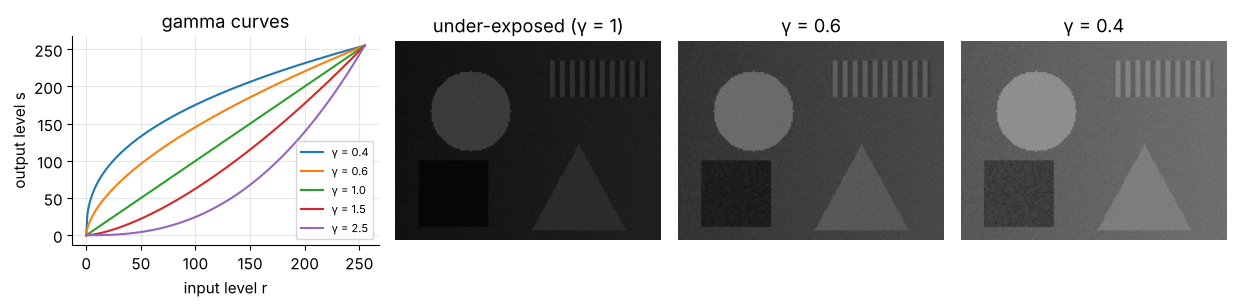

γ = 0.4: levels 10, 30, 60 -> [ 70 108 143]; the 256 inputs give only 173 distinct outputs
γ = 0.6: levels 10, 30, 60 -> [ 37  71 107]; the 256 inputs give only 209 distinct outputs
γ = 2.5: levels 10, 30, 60 -> [0 1 7]; the 256 inputs give only 173 distinct outputs


In [38]:
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.2), gridspec_kw={"width_ratios": [1.15, 1, 1, 1]})
gammas = [0.4, 0.6, 1.0, 1.5, 2.5]
for gam in gammas:
    axes[0].plot(r_all, 255 * (r_all / 255) ** gam, label=f"γ = {gam}")
axes[0].set_xlabel("input level r")
axes[0].set_ylabel("output level s")
axes[0].set_title("gamma curves")
axes[0].legend(fontsize=8)
for ax, gam in zip(axes[1:], [1.0, 0.6, 0.4]):
    lut_gamma = to_uint8(255 * (r_all / 255) ** gam)
    ax.imshow(lut_gamma[dark], cmap="gray", vmin=0, vmax=255)
    ax.set_title("under-exposed (γ = 1)" if gam == 1.0 else f"γ = {gam}")
    ax.axis("off")
fig.tight_layout()
plt.show()

for gam in [0.4, 0.6, 2.5]:
    lut_gamma = to_uint8(255 * (r_all / 255) ** gam)
    print(f"γ = {gam}: levels 10, 30, 60 -> {lut_gamma[[10, 30, 60]]}, and the 256 inputs give only "
          f"{len(np.unique(lut_gamma))} distinct outputs")

The under-exposed image (all values below about 65) becomes readable with $\gamma = 0.6$ or $0.4$. The last printout shows a cost that is easy to overlook: after rounding to integers, a gamma table is **not one-to-one**. Where the curve is flat, several input levels land on the same output level and can never be told apart again, while where it is steep some output levels are skipped. Every 8-bit point operation that stretches one range must compress another.

**Quick check 5.** Which of these 8-bit point operations can be undone exactly: (a) the negative $255 - r$, (b) $\min(r + 60, 255)$, (c) gamma with $\gamma = 0.5$ and rounding, (d) thresholding?

<details>
<summary>Answer</summary>

Only (a). The negative is a one-to-one table (it is its own inverse). (b) sends every $r \ge 195$ to 255, so those levels merge. (c) merges several bright levels after rounding (192 distinct outputs for 256 inputs). (d) keeps just two values. A LUT is invertible exactly when it is one-to-one.
</details>

#### ✏️ Exercise 7: robust percentile stretch

Implement `percentile_stretch(img, lo=1, hi=99)`: compute $a = $ `np.percentile(img, lo)` and $b = $ `np.percentile(img, hi)`, map $r \mapsto (r - a)/(b - a)\cdot 255$, then clip to $[0, 255]$, round with `np.rint` and return `uint8`.

In [39]:
# ✏️ Exercise 7: percentile-based contrast stretching
def percentile_stretch(img, lo=1, hi=99):
    """Linearly map the lo-th percentile to 0 and the hi-th percentile to 255 (clip, round, uint8)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    ramp = np.arange(101, dtype=np.uint8).reshape(1, -1)        # levels 0..100
    out = percentile_stretch(ramp, 10, 90)                     # a = 10, b = 90
    assert out.dtype == np.uint8 and out.shape == ramp.shape, "return a uint8 image of the same shape"
    got = out[0, [0, 10, 30, 50, 90, 95]].tolist()
    assert got == [0, 0, 64, 128, 255, 255], f"expected [0, 0, 64, 128, 255, 255] at levels 0,10,30,50,90,95, got {got}"
    res = percentile_stretch(damaged)
    assert res.min() == 0 and res.max() == 255 and res.std() > 50, "the damaged foggy image should be strongly stretched"
    assert np.all(np.diff(percentile_stretch(np.arange(256, dtype=np.uint8).reshape(16, 16)).ravel().astype(int)) >= 0), \
        "the mapping must be non-decreasing"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def percentile_stretch(img, lo=1, hi=99):
    a, b = np.percentile(img, [lo, hi])
    s = (img.astype(np.float64) - a) / (b - a) * 255
    return np.clip(np.rint(s), 0, 255).astype(np.uint8)
```
Converting to float before subtracting avoids `uint8` wraparound for pixels darker than $a$, and the clip then sends them to 0 (and pixels brighter than $b$ to 255). Level 50 maps to $40/80 \cdot 255 = 127.5$, which `np.rint` rounds to the even neighbor 128.
</details>

## 7. Histogram equalization and CLAHE

### 7.1 The idea: use the CDF as the lookup table

Look again at the foggy card: about 50 gray levels are used, and most pixels crowd into an even smaller band of them. Contrast stretching spaced *all* levels equally far apart. A smarter rule spaces levels apart **in proportion to how many pixels they hold**: crowded levels get pushed far apart (that is where the detail is), rarely used levels get squeezed together (little is lost there). The ideal result would use every output level equally often, i.e. a **flat histogram**.

Remarkably, the transformation that achieves this is the CDF itself. Here is the argument for a continuous random variable $X$ with a continuous, strictly increasing CDF $F$. Define the new variable $U = F(X)$, which takes values in $[0, 1]$. For any $u \in [0, 1]$:

$$
P(U \le u) = P\big(F(X) \le u\big) = P\big(X \le F^{-1}(u)\big) = F\big(F^{-1}(u)\big) = u .
$$

The second step uses that $F$ is increasing (so applying $F^{-1}$ to both sides keeps the inequality), the third is the definition of the CDF. A variable whose CDF is $P(U \le u) = u$ is **uniform** on $[0, 1]$. So *plugging a variable into its own CDF always produces a uniform variable*, and statisticians call this the **probability integral transform**. Scaling to the gray-level range gives the equalization mapping

$$
T(r) = (L - 1)\,F(r),
$$

where $L$ is the number of gray levels ($L = 256$ for 8 bits). Its slope is $T'(r) = (L-1)\,f(r)$, proportional to the density: steep where pixels are crowded, flat where they are rare. That is exactly the "space levels apart in proportion to their population" rule.

> **Intuition.** Line up all $N$ pixels from darkest to brightest and give each one its *rank*. Equalization replaces every gray level by (approximately) the **fraction of pixels that are at most as bright**, scaled to $0..L-1$. A pixel brighter than 70% of the image becomes level $\approx 0.7\,(L-1)$, whatever its original value was.

For a digital image the argument is only approximately true, because $X$ is discrete: all pixels that share a gray level must move **together** (a point operation cannot split them). The output histogram therefore keeps the same bars, just moved, and it is the output **CDF** that becomes approximately a straight line.

### 7.2 The discrete formula, by hand

For each gray level $b$ that occurs in the image, compute $F(b) = P(X \le b)$ (note the $\le$: the level's own pixels are included) and set

$$
b_{\text{new}} = \left\lfloor (L-1)\,F(b) + 0.5 \right\rfloor ,
$$

i.e. round $(L-1)F(b)$ to the nearest integer, with halves rounded **up**. Example: a $2 \times 7$ image with 3-bit gray levels ($L = 8$, values $0..7$):

$$
G = \begin{bmatrix} 3 & 4 & 4 & 2 & 4 & 5 & 3 \\ 4 & 3 & 5 & 4 & 3 & 4 & 5 \end{bmatrix}, \qquad N = 14 .
$$

| level $b$ | count | $F(b)$ | $7\,F(b)$ | $b_{\text{new}} = \lfloor 7F(b) + 0.5 \rfloor$ |
|---|---|---|---|---|
| 2 | 1 | 1/14 | 0.5 | **1** |
| 3 | 4 | 5/14 | 2.5 | **3** |
| 4 | 6 | 11/14 | 5.5 | **6** |
| 5 | 3 | 14/14 | 7.0 | **7** |

$$
G_{\text{eq}} = \begin{bmatrix} 3 & 6 & 6 & 1 & 6 & 7 & 3 \\ 6 & 3 & 7 & 6 & 3 & 6 & 7 \end{bmatrix}.
$$

The levels $2, 3, 4, 5$ (range 3) became $1, 3, 6, 7$ (range 6). The most crowded level, 4, got the biggest jump (from 3 to 6, a step of $7 \cdot 6/14 = 3$), the lonely level 2 the smallest. The order of the levels is preserved, because the CDF never decreases.

Now the trap hidden in this example: **all three values $0.5, 2.5, 5.5$ are exact halves**. The formula says round halves up. But Python's `round`, `np.round` and `np.rint` all round halves to the **nearest even** integer (Section 1.3), which gives $0, 2, 6, 7$, while truncation (`int(...)` or `np.floor` without the $+0.5$) gives $0, 2, 5, 7$. Three different "equalized" images from one formula. Follow the formula literally.

In [40]:
G = np.array([[3, 4, 4, 2, 4, 5, 3],
              [4, 3, 5, 4, 3, 4, 5]])
L_G = 8
counts_G = np.bincount(G.ravel(), minlength=L_G)
cum_G = np.cumsum(counts_G)                       # cumulative COUNTS: integers, no rounding error
N_G = G.size
present = np.flatnonzero(counts_G)
scaled = (L_G - 1) * cum_G[present] / N_G

display(pd.DataFrame({
    "count": counts_G[present],
    "F(b)": [f"{c}/{N_G}" for c in cum_G[present]],
    "(L-1)F(b)": scaled,
    "floor(x+0.5)  [the formula]": np.floor(scaled + 0.5).astype(int),
    "np.round(x)  [half to even]": np.round(scaled).astype(int),
    "np.floor(x)  [truncation]": np.floor(scaled).astype(int),
}, index=pd.Index(present, name="level b")))

lut_G = np.floor((L_G - 1) * cum_G / N_G + 0.5).astype(int)
G_eq = lut_G[G]
print("G_eq =\n", G_eq)
print(f"before: mean {G.mean():.4f}, std {G.std():.4f} | after: mean {G_eq.mean():.4f}, std {G_eq.std():.4f}")

,count,F(b),(L-1)F(b),floor(x+0.5) [the formula],np.round(x) [half to even],np.floor(x) [truncation]
level b,,,,,,
2,1,1/14,0.5,1,0,0
3,4,5/14,2.5,3,2,2
4,6,11/14,5.5,6,6,5
5,3,14/14,7.0,7,7,7


G_eq =
 [[3 6 6 1 6 7 3]
 [6 3 7 6 3 6 7]]
before: mean 3.7857, std 0.8601 | after: mean 5.0000, std 1.8898


A second, sneakier trap. The obvious code `cdf = np.cumsum(pmf)` adds up floating-point fractions like $2/12$, and floating-point sums carry tiny errors (the famous `0.1 + 0.2 = 0.30000000000000004`). Usually harmless, but at an exact half, an error of $10^{-16}$ in the wrong direction flips the rounding. Here is a $3 \times 4$, 3-bit image where it happens:

In [41]:
J = np.array([[0, 5, 1, 7],
              [3, 5, 0, 6],
              [2, 7, 1, 5]])
cnt_J = np.bincount(J.ravel(), minlength=8)
cdf_float = np.cumsum(cnt_J / J.size)                              # summing float fractions
lut_float = np.floor(7 * cdf_float + 0.5).astype(int)
lut_exact = (7 * 2 * np.cumsum(cnt_J) + J.size) // (2 * J.size)    # floor(7C/N + 1/2) in exact integer arithmetic
print("7*F(3) from float cumsum :", repr(float(7 * cdf_float[3])))
print("7*F(3) exactly           : 7*6/12 =", 7 * 6 / 12)
print("LUT with float cumsum:", lut_float.tolist())
print("LUT exact            :", lut_exact.tolist())

7*F(3) from float cumsum : 3.4999999999999996
7*F(3) exactly           : 7*6/12 = 3.5
LUT with float cumsum: [1, 2, 3, 3, 3, 5, 6, 7]
LUT exact            : [1, 2, 3, 4, 4, 5, 6, 7]


Level 3 should map to $\lfloor 3.5 + 0.5 \rfloor = 4$, but the float version computes $3.4999999999999996$ and maps it to 3. In a random search over small exam-sized histograms, roughly one in twenty showed such a flip. The cure is to work with **integer cumulative counts** $C(b) = \#\{\text{pixels} \le b\}$ and do the rounding with integer arithmetic:

$$
\left\lfloor \frac{(L-1)\,C(b)}{N} + \frac12 \right\rfloor = \left\lfloor \frac{2(L-1)\,C(b) + N}{2N} \right\rfloor \qquad (\text{integer division `//`}).
$$

By hand, keep fractions as fractions ($7 \cdot 6/12 = 3.5$ exactly) and you are safe.

### 7.3 Equalization from scratch

The implementation is four lines: histogram, cumulative counts, the formula as a lookup table, and one fancy-indexing step.

hand example reproduced: True
foggy:     levels 95..153, 59 distinct levels, std 11.78
equalized: levels 0..255, 52 distinct levels, std 73.01


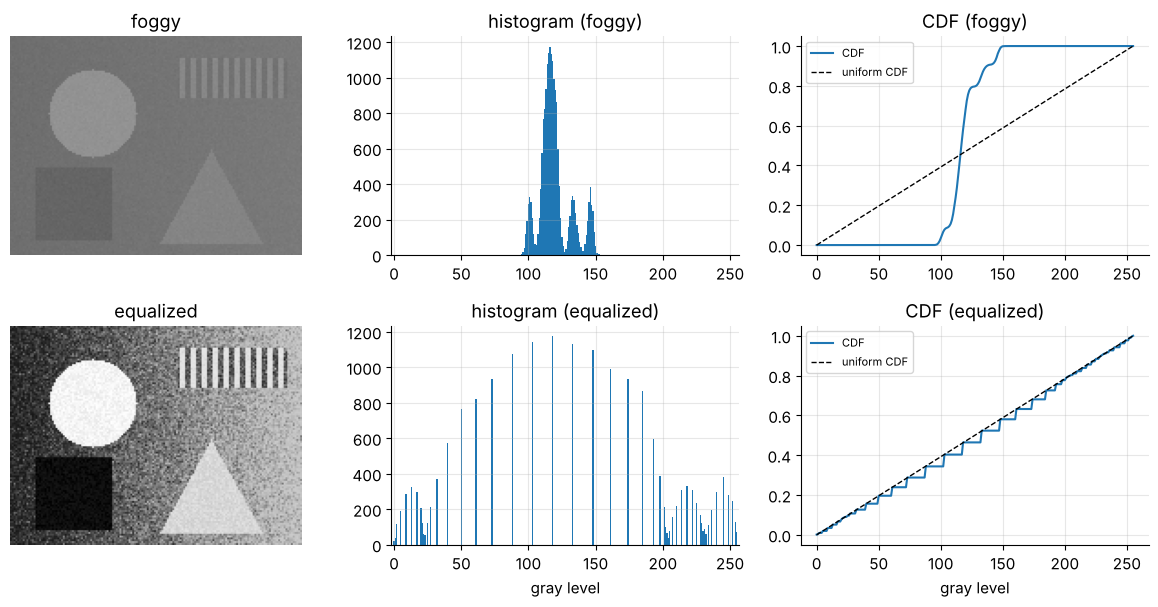

In [42]:
def equalize(img, L=256):
    """Histogram equalization with b_new = floor((L-1) * F(b) + 0.5), in exact integer arithmetic.

    img: integer array with values in 0..L-1. Returns (equalized image as uint8, lookup table of length L).
    """
    counts = np.bincount(img.ravel(), minlength=L)
    cum = np.cumsum(counts).astype(np.int64)               # C(b) = number of pixels <= b
    N = img.size
    lut = ((L - 1) * 2 * cum + N) // (2 * N)               # = floor((L-1) * C/N + 1/2)
    return lut[img].astype(np.uint8), lut.astype(np.uint8)


fog_eq, lut_eq = equalize(foggy)
print("hand example reproduced:", np.array_equal(equalize(G, L=8)[0], G_eq))
print(f"foggy:     levels {foggy.min()}..{foggy.max()}, {len(np.unique(foggy))} distinct levels, std {foggy.std():.2f}")
print(f"equalized: levels {fog_eq.min()}..{fog_eq.max()}, {len(np.unique(fog_eq))} distinct levels, std {fog_eq.std():.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for row, (im, name) in enumerate([(foggy, "foggy"), (fog_eq, "equalized")]):
    axes[row, 0].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[row, 0].set_title(name)
    axes[row, 0].axis("off")
    axes[row, 1].bar(r_all, np.bincount(im.ravel(), minlength=256), width=1.0)
    axes[row, 1].set_title(f"histogram ({name})")
    axes[row, 1].set_xlim(-2, 257)
    axes[row, 2].plot(r_all, np.cumsum(np.bincount(im.ravel(), minlength=256)) / im.size, label="CDF")
    axes[row, 2].plot([0, 255], [0, 1], "k--", lw=1, label="uniform CDF")
    axes[row, 2].set_title(f"CDF ({name})")
    axes[row, 2].legend(fontsize=8, loc="upper left")
axes[1, 1].set_xlabel("gray level")
axes[1, 2].set_xlabel("gray level")
fig.tight_layout()
plt.show()

Three observations:

* The equalized image spans the full range $0..255$ and its standard deviation (a rough measure of global contrast) is several times larger.
* Its **histogram is not flat**: the same bars, moved apart, with gaps between them. Crowded levels were moved far apart, rare levels at the two ends were merged (there are fewer distinct levels than before: a merge happens whenever two neighbors round to the same output). Equalization never creates new levels.
* Its **CDF hugs the diagonal**, the CDF of a uniform distribution. That is what "equalized" really means for a discrete image.

### 7.4 Our formula versus `cv2.equalizeHist`

OpenCV uses a slightly different normalization. With $b_{\min}$ the darkest level that occurs and $C$ the cumulative count, it computes

$$
b_{\text{new}}^{\text{OpenCV}} = \operatorname{round}\!\left( 255 \cdot \frac{C(b) - C(b_{\min})}{N - C(b_{\min})} \right).
$$

Subtracting $C(b_{\min})$ guarantees that the darkest level present becomes exactly $0$ (and the brightest exactly $255$). In the textbook formula the darkest level becomes $\lfloor 255\,F(b_{\min}) + 0.5\rfloor$, which is above $0$ whenever that level holds at least $1/510$ of the pixels. That is also where the two formulas disagree most. Before rounding, with $c_0 = C(b_{\min})$ the number of pixels at the darkest level, their difference is

$$
255\left(\frac{C(b)}{N} - \frac{C(b) - c_0}{N - c_0}\right) = 255\,\frac{c_0\,\big(N - C(b)\big)}{N\,(N - c_0)} ,
$$

which equals $255\,c_0/N = 255\,F(b_{\min})$ at the darkest level and shrinks to $0$ at the brightest. So the gap depends on the **share of pixels at the darkest level**, not on the size of the image. On the foggy card, whose darkest level ($95$) holds only $7$ of its $19{,}200$ pixels, the two agree to within one level (see below). On a large photo in which $10\%$ of the pixels are pure black (clipped shadows, a black border), they differ by up to about $26$ levels ($255 \times 0.1 = 25.5$), and on tiny exam images, where a single pixel is already a large fraction, they can differ a lot. For the hand example $G$ the OpenCV-style mapping (with $7$ in place of $255$) gives $\operatorname{round}(7 \cdot 0/13) = 0$, $\operatorname{round}(7 \cdot 4/13) = 2$, $\operatorname{round}(7 \cdot 10/13) = 5$ and $7$, versus our $1, 3, 6, 7$.

> **Common pitfall.** If a question gives you the formula $\lfloor (L-1)\,\mathrm{CDF}(b) + 0.5\rfloor$, apply it as written. Do not "check" your answer with `cv2.equalizeHist`: it implements a different formula (and works only for 8-bit images).

In [43]:
def equalize_opencv_style(img):
    """Re-implementation of cv2.equalizeHist's mapping (8-bit), to show exactly what it computes."""
    counts = np.bincount(img.ravel(), minlength=256)
    cum = np.cumsum(counts)
    b_min = np.flatnonzero(counts)[0]
    if counts[b_min] == img.size:                                    # constant image: OpenCV returns it unchanged
        return img.copy()
    scale = np.float32(255) / np.float32(img.size - counts[b_min])  # OpenCV works in single precision
    lut = np.rint((cum - counts[b_min]).astype(np.float32) * scale)
    lut = np.clip(lut, 0, 255).astype(np.uint8)
    lut[:b_min] = 0
    return lut[img]


fog_cv = cv2.equalizeHist(foggy)
print("our re-implementation matches cv2.equalizeHist exactly:", np.array_equal(equalize_opencv_style(foggy), fog_cv))
diff_px = int((fog_cv != fog_eq).sum())
print(f"textbook vs OpenCV on the foggy card: {diff_px} of {foggy.size} pixels differ, "
      f"max difference {int(np.abs(fog_cv.astype(int) - fog_eq).max())} level(s)")
const = np.full((3, 4), 77, dtype=np.uint8)
print("constant image of 77s -> textbook:", np.unique(equalize(const)[0]), "| OpenCV:", np.unique(cv2.equalizeHist(const)))

our re-implementation matches cv2.equalizeHist exactly: True
textbook vs OpenCV on the foggy card: 120 of 19200 pixels differ, max difference 1 level(s)
constant image of 77s -> textbook: [255] | OpenCV: [77]


### 7.5 What equalization does and does not do

**It is monotone.** The lookup table is a scaled CDF, so it never decreases: darker stays darker (or equal, when two levels merge). No two gray levels ever swap order.

**It is idempotent: equalizing twice changes nothing.** Take an output level $s$ and let $b'$ be the *largest* input level with $T(b') = s$. Every pixel at most as bright as $b'$ ends up at most $s$, every brighter pixel ends up above $s$, so the new CDF at $s$ equals the old $F(b')$, and the second pass maps $s$ to $\lfloor (L-1)F(b') + 0.5\rfloor = T(b') = s$. Every level stays put.

**It amplifies noise in large flat regions.** The slope of the mapping at level $b$ is $T(b) - T(b-1) \approx (L-1)\,p(b)$. A large, nearly uniform region (the card's background) puts many pixels into a narrow band of levels, so those levels get a large slope, and the small sensor noise inside the region is stretched along with everything else.

pixels changed by a second equalization: 0
background patch: std 2.05 before -> 20.30 after equalization


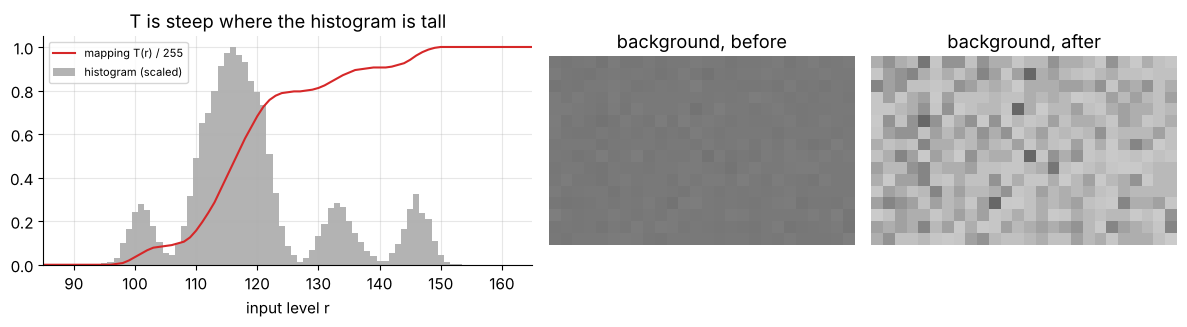

In [44]:
fog_eq2, _ = equalize(fog_eq)
print("pixels changed by a second equalization:", int((fog_eq2 != fog_eq).sum()))

bg_patch = (slice(40, 56), slice(130, 156))          # a plain piece of the card's background
print(f"background patch: std {foggy[bg_patch].std():.2f} before -> {fog_eq[bg_patch].std():.2f} after equalization")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1, 1]})
h_fog = np.bincount(foggy.ravel(), minlength=256)
axes[0].bar(r_all, h_fog / h_fog.max(), width=1.0, color="0.7", label="histogram (scaled)")
axes[0].plot(r_all, lut_eq / 255, color="C3", label="mapping T(r) / 255")
axes[0].set_xlim(85, 165)
axes[0].set_xlabel("input level r")
axes[0].set_title("T is steep where the histogram is tall")
axes[0].legend(fontsize=8, loc="upper left")
for ax, im, name in [(axes[1], foggy, "background, before"), (axes[2], fog_eq, "background, after")]:
    ax.imshow(im[bg_patch], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(name)
    ax.axis("off")
fig.tight_layout()
plt.show()

The background patch looked smooth before. After equalization its noise is about ten times stronger, because it sits on the tallest part of the histogram, where the mapping is steepest. Equalization also has a **global** blind spot: one table for the whole image. If one half of a photo is in shadow and the other in sunlight, a single mapping cannot fix both. The next tool addresses both problems.

### 7.6 CLAHE: local equalization with a speed limit

**CLAHE** (Contrast-Limited Adaptive Histogram Equalization) changes two things:

1. **Adaptive.** Split the image into a grid of tiles and compute a separate equalization table for each tile from that tile's own histogram, so a dark corner and a bright corner each get a mapping suited to their lighting. To avoid visible seams at tile borders, each pixel's output is a **bilinear interpolation** of the tables of the four nearest tile centers.
2. **Contrast-limited.** Before computing each tile's CDF, **clip** every histogram bin at a ceiling of `clipLimit` times the average bin count, and spread the clipped-off excess evenly over all bins. Since the slope of the mapping is proportional to the bin height, the ceiling caps the slope: with $n$ pixels in a tile, a bin holds at most $\beta + E/256$ where $\beta = \texttt{clipLimit}\cdot n/256$ and $E \le n$ is the redistributed excess, so the slope $255\,(\beta + E/256)/n$ stays below $\texttt{clipLimit} + 1$. A flat tile can no longer have its noise multiplied by 10 or 20.

In OpenCV: `cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img)`. Note that `tileGridSize` is **(tiles across, tiles down)**, OpenCV's usual $(x, y)$ = (width, height) order, not NumPy's (rows, cols).

Our test image is a printed page photographed under a lamp near its top-right corner: the bottom-left is in deep shadow, where the ink differs from the paper by only a few gray levels.

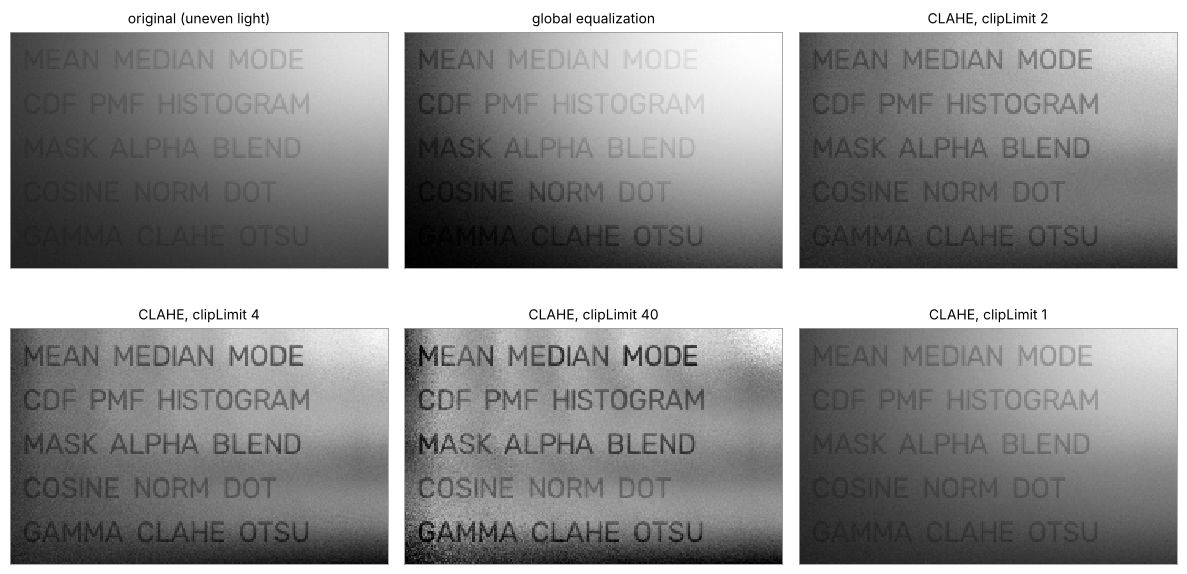

In [45]:
def make_page(H=150, W=240, seed=5):
    """Faint gray text on paper, lit by a lamp near the top-right corner. Returns (uint8 image, ink mask)."""
    g = np.random.default_rng(seed)
    ink = np.zeros((H, W), dtype=np.uint8)
    lines = ["MEAN  MEDIAN  MODE", "CDF  PMF  HISTOGRAM", "MASK  ALPHA  BLEND", "COSINE  NORM  DOT", "GAMMA  CLAHE  OTSU"]
    for k, line in enumerate(lines):
        cv2.putText(ink, line, (8, 24 + 28 * k), cv2.FONT_HERSHEY_SIMPLEX, 0.62, 255, 1, cv2.LINE_AA)
    reflectance = 0.92 - 0.14 * ink / 255.0                   # paper reflects 92% of the light, ink 78%
    yy, xx = np.mgrid[0:H, 0:W].astype(float)
    r2 = ((xx - W) / W) ** 2 + (yy / H) ** 2                  # squared distance from the top-right corner
    illumination = 28 + 222 * np.exp(-r2 / 0.6)
    return to_uint8(illumination * reflectance + g.normal(0, 1.2, (H, W))), ink > 127


page, page_ink = make_page()
page_global = cv2.equalizeHist(page)
page_clahe = {c: cv2.createCLAHE(clipLimit=c, tileGridSize=(6, 3)).apply(page) for c in (1.0, 2.0, 4.0, 40.0)}
show_images([page, page_global, page_clahe[2.0], page_clahe[4.0], page_clahe[40.0], page_clahe[1.0]],
            ["original (uneven light)", "global equalization", "CLAHE, clipLimit 2",
             "CLAHE, clipLimit 4", "CLAHE, clipLimit 40", "CLAHE, clipLimit 1"], ncols=3, size=4.0)

To compare the versions with numbers rather than impressions, measure in each corner the **ink-paper contrast** (mean paper level minus mean ink level, using the known ink mask) and, in a blank piece of paper in the dark corner, the **noise** (standard deviation).

In [46]:
corners = {"dark corner": (slice(100, 150), slice(0, 80)), "bright corner": (slice(0, 50), slice(160, 240))}
blank = (slice(140, 150), slice(0, 16))                       # a small blank patch below the last line, deep in the shadow


def ink_contrast(img, region):
    """Mean paper level minus mean ink level inside a region."""
    sub, ink = img[region].astype(float), page_ink[region]
    return sub[~ink].mean() - sub[ink].mean()


versions = {"original": page, "global equalization": page_global,
            **{f"CLAHE clipLimit={c:g}": page_clahe[c] for c in (1.0, 2.0, 4.0, 40.0)}}
page_table = pd.DataFrame({name: {"contrast, dark corner": ink_contrast(im, corners["dark corner"]),
                                  "contrast, bright corner": ink_contrast(im, corners["bright corner"]),
                                  "noise in blank shadow": im[blank].std()}
                           for name, im in versions.items()}).T
display(page_table.round(1))

,"contrast, dark corner","contrast, bright corner",noise in blank shadow
original,4.5,41.7,1.5
global equalization,8.3,29.4,1.4
CLAHE clipLimit=1,8.0,54.9,2.8
CLAHE clipLimit=2,11.7,70.6,4.2
CLAHE clipLimit=4,19.0,89.6,7.0
CLAHE clipLimit=40,48.1,94.4,23.1


Read the table row by row:

* **Global equalization** helps the shadow only a little (the text contrast there stays faint) and actually *lowers* the contrast in the bright corner: bright paper is a small fraction of the image, so the global table squeezes the bright levels together.
* **CLAHE** raises the contrast in both corners at once, because each tile gets its own table.
* **The clip limit is the knob between "too timid" and "too noisy".** With `clipLimit=1` the gain is at most about 2, and the shadowed text stays faint. Raising the limit increases the contrast in the shadow, but the noise in the blank paper rises with it, and at `clipLimit=40` (practically no limit) the shadow becomes readable at the price of grainy paper. Values around 2 to 4 are common choices. Beware: OpenCV's own default (`cv2.createCLAHE()` with no arguments) is `clipLimit=40`, the nearly unlimited, noisy setting of the last row, so always pass `clipLimit` explicitly.

> **Going deeper.** Equalization is a special case of **histogram matching** (also called histogram specification): to give an image the histogram of a *reference* image with CDF $G$, map each level through $G^{-1}(F(r))$, i.e. first to its quantile in the source, then to the level with the same quantile in the reference. With a uniform reference, $G^{-1}$ is just a scaling, and you get equalization back. This is how photos from two cameras are made to look alike before they are compared.

> **Going deeper.** CLAHE is a standard preprocessing step in medical imaging (X-rays, retinal photos) and for feature detection under bad lighting. Color images are usually converted to a luminance/chrominance space (for example LAB), CLAHE is applied to the lightness channel only, and the result is converted back, so that the colors do not shift.

**Quick check 6.** (a) After equalizing the foggy card, its histogram still has gaps and is far from flat. Did the code fail? (b) Why can CLAHE's output for a tile never be more than about `clipLimit + 1` times as contrasty as its input, while global equalization can multiply local contrast by 10?

<details>
<summary>Answer</summary>

(a) No. A point operation moves all pixels of one level together, so it can only move histogram bars, never split them. What equalization guarantees (approximately) is a straight-line CDF, and the plot in 7.3 shows exactly that. (b) The slope of an equalization table at level $b$ is proportional to the height of bin $b$. Clipping every bin at `clipLimit` times the average (plus the evenly spread excess) caps the height, hence the slope, hence the gain. Without clipping, one very tall bin (a large flat region) produces a very steep step.
</details>

#### ✏️ Exercise 8: the equalization table, exactly

Implement `equalization_lut(img, L)` returning the integer array `lut` of length `L` with `lut[b]` $= \lfloor (L-1)\,C(b)/N + 0.5 \rfloor$, where $C(b)$ is the number of pixels with value $\le b$ and $N$ the number of pixels. Use exact integer arithmetic (no float CDF). Levels that do not occur still get an entry (their value does not matter for the image, but it must follow the formula).

In [47]:
# ✏️ Exercise 8: histogram-equalization lookup table with half-up rounding
def equalization_lut(img, L):
    """Return lut (int array, length L) with lut[b] = floor((L-1) * C(b) / N + 0.5), computed exactly."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    lut = np.asarray(equalization_lut(G, 8))
    assert lut.shape == (8,), f"the table must have length L = 8, got shape {lut.shape}"
    assert lut[[2, 3, 4, 5]].tolist() == [1, 3, 6, 7], f"hand example: levels 2,3,4,5 -> 1,3,6,7, got {lut[[2, 3, 4, 5]].tolist()}"
    assert lut[[0, 1, 6, 7]].tolist() == [0, 0, 7, 7], "levels that do not occur still follow the formula (C(b) is the count of pixels <= b)"
    assert np.asarray(equalization_lut(J, 8))[3] == 4, "level 3 of J must map to 4 (7*6/12 = 3.5 rounds UP): avoid float cumsum"
    img = np.random.default_rng(3).integers(0, 256, size=(37, 41))
    assert np.array_equal(np.asarray(equalization_lut(img, 256)), equalize(img)[1]), "8-bit random image: mismatch"


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def equalization_lut(img, L):
    cum = np.cumsum(np.bincount(np.ravel(img), minlength=L)).astype(np.int64)
    N = np.size(img)
    return ((L - 1) * 2 * cum + N) // (2 * N)
```
Multiplying numerator and denominator by 2 turns "$+0.5$ then floor" into one integer division: $\lfloor (L-1)C/N + 1/2 \rfloor = \lfloor (2(L-1)C + N)/(2N) \rfloor$. Every quantity is an integer, so no rounding error can push an exact half to the wrong side.
</details>

## 8. Background subtraction: difference images, thresholds and Otsu's method

A video-call app that replaces your room with a beach must decide, for every pixel of every frame, "person or room?". The classic approach, used long before deep learning, is **background subtraction**: photograph the empty room once, then flag every pixel of a new frame that differs from that photo by a lot. Everything in this section is statistics on pixel values: averages, noise levels, thresholds and histograms.

### 8.1 A synthetic video call

We generate the scene with code so that we know the **ground truth** (which pixels really belong to the person) and can measure every method exactly. The room has a lit wall, a bright window, a dark bookshelf with books, a picture frame and a desk. Every captured frame adds Gaussian sensor noise with standard deviation $\sigma = 5$ and rounds to `uint8`.

In [48]:
H_S, W_S = 120, 160          # scene size (rows, cols)
SIGMA_CAM = 5.0              # camera noise level (gray levels)


def make_room(H=H_S, W=W_S):
    """The empty room as noise-free float intensities."""
    yy, xx = np.mgrid[0:H, 0:W].astype(float)
    room = 158 - 34 * yy / H                                            # wall, lit from the ceiling
    win = (yy >= 10) & (yy < 50) & (xx >= 114) & (xx < 152)
    room[win] = 228 - 0.3 * (yy[win] - 10)                              # bright window
    room[win & ((np.abs(xx - 133) < 1.5) | (np.abs(yy - 30) < 1.5))] = 112   # window bars
    room[(yy >= 28) & (yy < 98) & (xx >= 8) & (xx < 46)] = 62           # dark bookshelf
    for k, x0 in enumerate(range(10, 44, 4)):                           # book spines on two shelves
        for y0, y1 in [(32, 60), (66, 94)]:
            room[(yy >= y0 + (k % 3) * 2) & (yy < y1) & (xx >= x0) & (xx < x0 + 3)] = 85 + 24 * ((3 * k + y0) % 5)
    room[(yy >= 60) & (yy < 84) & (xx >= 120) & (xx < 146)] = 70        # picture frame ...
    room[(yy >= 63) & (yy < 81) & (xx >= 123) & (xx < 143)] = 185       # ... and picture
    room[yy >= 104] = 96 + 6 * np.sin(xx[yy >= 104] / 5)                # desk with wood grain
    return room


def make_person(cx, H=H_S, W=W_S, shirt=72.0, face=176.0, hair=48.0):
    """Head-and-shoulders silhouette centered at column cx. Returns (float intensities, boolean mask)."""
    yy, xx = np.mgrid[0:H, 0:W].astype(float)
    head = ((yy - 46) / 19) ** 2 + ((xx - cx) / 14.5) ** 2 <= 1
    hair_m = head & (yy < 40 - 0.15 * np.abs(xx - cx))
    neck = (yy >= 60) & (yy < 76) & (np.abs(xx - cx) <= 6.5)
    torso = (((yy - 122) / 46) ** 2 + ((xx - cx) / 40) ** 2 <= 1) & (yy >= 74)
    val = np.zeros((H, W))
    val[torso] = shirt + 6 * np.sin(yy[torso] / 3)                      # shirt with folds
    val[neck] = face - 18
    val[head] = face
    val[hair_m] = hair
    return val, head | neck | torso


def make_beach(H=H_S, W=W_S):
    """The virtual background F: sky, sun, sea and sand."""
    yy, xx = np.mgrid[0:H, 0:W].astype(float)
    F = 205 - 60 * yy / 70                                              # sky gradient
    F[(yy - 40) ** 2 + (xx - 45) ** 2 <= 14 ** 2] = 250                 # sun
    sea = yy >= 70
    F[sea] = 70 + 12 * np.sin(xx[sea] / 4 + yy[sea] / 1.5)              # waves
    F[yy >= 100] = 185 - 0.2 * (yy[yy >= 100] - 100)                    # sand
    return to_uint8(F)


cam = np.random.default_rng(2024)                                       # the camera's noise generator


def capture(true_img, sigma=SIGMA_CAM):
    """Simulate the camera: add Gaussian noise, round and clip to uint8."""
    return to_uint8(true_img + cam.normal(0, sigma, true_img.shape))


room = make_room()
person_val, person_mask = make_person(cx=70)
scene_true = np.where(person_mask, person_val, room)
beach = make_beach()
print(f"scene {H_S}x{W_S}: the person covers {person_mask.mean():.1%} of the pixels")

scene 120x160; the person covers 19.2% of the pixels


**The background model.** One photo of the empty room carries the full camera noise. A better reference is the **average of several empty frames**: by Section 3, the mean of $n$ independent measurements with standard deviation $\sigma$ has standard deviation $\sigma/\sqrt n$. With $n = 16$ frames the reference noise drops from 5 to $5/4 = 1.25$. The same 16 frames also let us **measure** the camera noise: the per-pixel *sample* standard deviation across frames (with $n - 1$ in the denominator, since we are estimating from a sample).

noise of a single empty frame : 4.961   (theory 5.0)
noise of the 16-frame average : 1.248   (theory 1.25)
noise level estimated from the empty frames alone: sigma_hat = 5.017


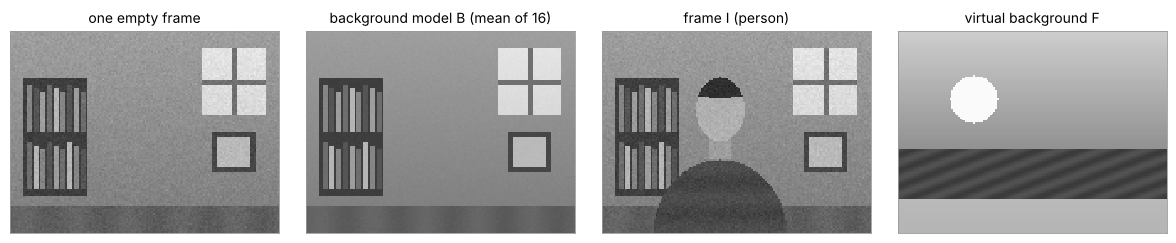

In [49]:
n_bg = 16
empty_frames = np.stack([capture(room) for _ in range(n_bg)])          # shape (16, 120, 160)
B_model = empty_frames.mean(axis=0)                                     # float background model, shape (120, 160)
sigma_hat = np.sqrt(empty_frames.astype(float).var(axis=0, ddof=1).mean())   # pooled per-pixel noise estimate
frame = capture(scene_true)                                             # a frame with the person in it

print(f"noise of a single empty frame : {(empty_frames[0] - room).std():.3f}   (theory {SIGMA_CAM})")
print(f"noise of the 16-frame average : {(B_model - room).std():.3f}   (theory {SIGMA_CAM / np.sqrt(n_bg)})")
print(f"noise level estimated from the empty frames alone: sigma_hat = {sigma_hat:.3f}")
show_images([empty_frames[0], B_model, frame, beach],
            ["one empty frame", "background model B (mean of 16)", "frame I (person)", "virtual background F"], size=3.0)

### 8.2 The difference image and the threshold

For each pixel, compare the frame $I$ with the background model $B$:

$$
D = |I - B|, \qquad M_{ij} = \begin{cases} 1 & \text{if } D_{ij} \ge \tau \\ 0 & \text{otherwise} \end{cases}
$$

$D$ is the **difference image** (large where something changed), $M$ the binary **foreground mask**, $\tau$ the **threshold**. Two details decide exam answers:

* **Absolute value, computed safely.** The person can be darker than the room (dark hair against the wall) or brighter (face against the bookshelf). Both are changes, so we need $|I - B|$, and with `uint8` inputs we must widen first or use `cv2.absdiff` (Section 1.3). The naive `I - B` on `uint8` wraps darker-than-background pixels around to large values and *silently* marks the wrong pixels.
* **$\ge$ versus $>$.** A pixel with $D_{ij}$ exactly equal to $\tau$ is foreground under "$\ge$" and background under "$>$". With integer images ties are common, so read the rule carefully. (OpenCV's `cv2.threshold(..., cv2.THRESH_BINARY)` uses **$>$**.)

D       : [ 3 20 21 19 40]   with tau = 20
D >= 20 : [0 1 1 0 1]
D >  20 : [0 0 1 0 1]
OpenCV THRESH_BINARY with thresh=20: [0 0 1 0 1]  <- strict '>'


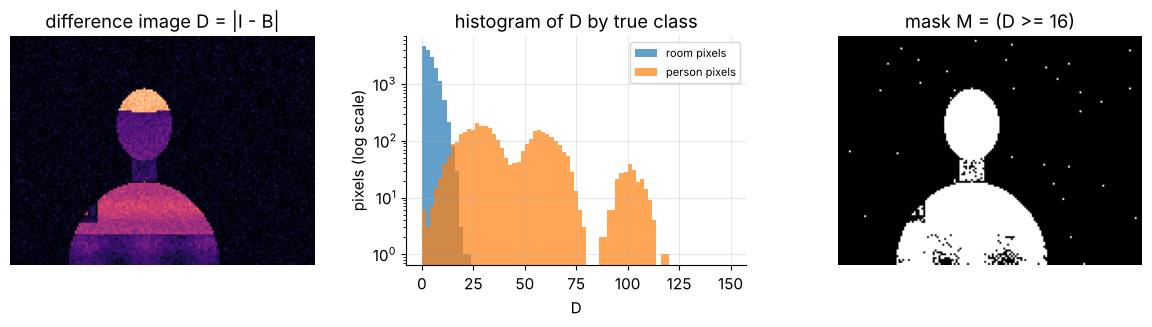

In [50]:
d_row = np.array([3, 20, 21, 19, 40])
print("D       :", d_row, "  with tau = 20")
print("D >= 20 :", (d_row >= 20).astype(int))
print("D >  20 :", (d_row > 20).astype(int))
_, cv_mask = cv2.threshold(d_row.astype(np.uint8), 20, 1, cv2.THRESH_BINARY)
print("OpenCV THRESH_BINARY with thresh=20:", cv_mask.ravel(), " <- strict '>'")

D_img = np.abs(frame.astype(np.float64) - B_model)                     # widen, then subtract
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].imshow(D_img, cmap="magma", vmin=0, vmax=120)
axes[0].set_title("difference image D = |I - B|")
axes[0].axis("off")
axes[1].hist(D_img[~person_mask], bins=np.arange(0, 151, 2), alpha=0.7, label="room pixels")
axes[1].hist(D_img[person_mask], bins=np.arange(0, 151, 2), alpha=0.7, label="person pixels")
axes[1].set_yscale("log")
axes[1].set_xlabel("D")
axes[1].set_ylabel("pixels (log scale)")
axes[1].set_title("histogram of D by true class")
axes[1].legend(fontsize=8)
axes[2].imshow(D_img >= 16, cmap="gray")
axes[2].set_title("mask M = (D >= 16)")
axes[2].axis("off")
fig.tight_layout()
plt.show()

Two humps: the room pixels pile up near $D = 0$ (pure noise), the person's pixels spread out to about 120. They **overlap**: some person pixels have small $D$ because the person happens to be about as bright as the room behind them (the dark shirt in front of the dark bookshelf). No threshold can separate the classes perfectly, and the question is which compromise to pick.

### 8.3 A threshold from the noise statistics

For a room pixel, $I - B$ is the frame's noise minus the background model's noise. These are independent with variances $\sigma^2$ and $\sigma^2/16$, and variances of independent terms **add** (even when the terms are subtracted), so

$$
I - B \sim \mathcal N\!\left(0,\; \sigma_D^2\right), \qquad \sigma_D = \sigma\sqrt{1 + \tfrac{1}{16}} .
$$

A room pixel exceeds $\tau = k\,\sigma_D$ with probability $P(|Z| \ge k) = 2\,(1 - \Phi(k))$, where $Z$ is standard normal and $\Phi$ its CDF. That is a **false-positive rate we can choose in advance**: about 4.6% for $k = 2$, 0.27% for $k = 3$, 0.006% for $k = 4$. This is the same reasoning as a statistical test: "is this pixel's change larger than noise alone would plausibly produce?"

In [51]:
sigma_D = sigma_hat * np.sqrt(1 + 1 / n_bg)
n_room = int((~person_mask).sum())


def mask_scores(mask, truth):
    """False positives, false negatives and IoU = |mask AND truth| / |mask OR truth|."""
    fp = int((mask & ~truth).sum())
    fn = int((~mask & truth).sum())
    iou = (mask & truth).sum() / (mask | truth).sum()
    return fp, fn, iou


rows = []
for k in [1.5, 2, 2.5, 3, 3.5, 4, 5, 6]:
    tau = k * sigma_D
    fp, fn, iou = mask_scores(D_img >= tau, person_mask)
    rows.append({"k": k, "tau": tau, "expected FP": n_room * 2 * stats.norm.sf(k), "FP": fp, "FN": fn, "IoU": iou})
thr_table = pd.DataFrame(rows).set_index("k")
print(f"sigma_D = {sigma_D:.3f}, {n_room} room pixels")
display(thr_table.round(3))

sigma_D = 5.171;  15509 room pixels


,tau,expected FP,FP,FN,IoU
k,,,,,
1.5,7.757,2072.226,2146,29,0.627
2.0,10.343,705.664,731,58,0.822
2.5,12.928,192.611,211,116,0.916
3.0,15.514,41.871,50,210,0.930
3.5,18.100,7.216,5,333,0.909
4.0,20.685,0.982,1,514,0.861
5.0,25.857,0.009,0,912,0.753
6.0,31.028,0.000,0,1411,0.618


The predicted false positives match the measured ones closely, a nice confirmation of the noise model. The two error types trade off as $\tau$ grows: false positives fall fast (the noise is Gaussian, with thin tails) while false negatives rise slowly (the camouflaged shirt pixels). Around $k = 3$, i.e. $\tau \approx 15.5$, the IoU is at its best. We will use $\tau = 16$ from now on.

> **Going deeper.** Without empty frames you could still estimate $\sigma_D$ from the frame itself, using the robust MAD of $I - B$ from Section 4: about 81% of the pixels are pure noise, so the median-based estimate is pulled up by the person only moderately, while the classic standard deviation is ruined. The next cell checks this.

In [52]:
d_signed = frame.astype(np.float64) - B_model
mad_sigma = 1.4826 * np.median(np.abs(d_signed - np.median(d_signed)))
print(f"sigma_D from the empty frames: {sigma_D:.2f} | robust MAD estimate from the frame: {mad_sigma:.2f} | "
      f"plain std of the frame difference: {d_signed.std():.2f}")

sigma_D from the empty frames: 5.17 | robust MAD estimate from the frame: 6.86 | plain std of the frame difference: 21.26


### 8.4 Otsu's method: a threshold from the histogram alone

Sometimes there is no noise model, only an image whose histogram has two humps (like the coins of Section 5). **Otsu's method** picks the threshold $t$ that makes the two resulting classes as compact as possible. Let class 0 be the levels $\le t$ and class 1 the levels $> t$, with weights (pixel fractions) $\omega_0, \omega_1$, means $\mu_0, \mu_1$ and variances $\sigma_0^2, \sigma_1^2$. The overall mean is $\mu_T = \omega_0\mu_0 + \omega_1\mu_1$. The **law of total variance** splits the total variance into a within-class and a between-class part:

$$
\sigma_T^2 = \underbrace{\omega_0\sigma_0^2 + \omega_1\sigma_1^2}_{\sigma_W^2(t)\ \text{(within)}} + \underbrace{\omega_0(\mu_0 - \mu_T)^2 + \omega_1(\mu_1 - \mu_T)^2}_{\sigma_B^2(t)\ \text{(between)}} .
$$

Since $\mu_0 - \mu_T = \omega_1(\mu_0 - \mu_1)$ and $\mu_1 - \mu_T = -\omega_0(\mu_0 - \mu_1)$, the between-class term simplifies to

$$
\sigma_B^2(t) = \omega_0\,\omega_1\,(\mu_0 - \mu_1)^2 .
$$

The total $\sigma_T^2$ does not depend on $t$, so **minimizing the within-class variance is the same as maximizing $\sigma_B^2(t)$**, which needs only weights and means. Otsu's threshold is $t^* = \arg\max_t \sigma_B^2(t)$. The formula has a nice reading: it rewards splits that are both **balanced** ($\omega_0\omega_1$ is largest at $\frac12 \cdot \frac12$) and **well separated** (large $|\mu_0 - \mu_1|$).

**By hand.** A 16-pixel image with levels $0..5$ and counts $h = (2, 5, 1, 1, 4, 3)$, so $\mu_T = (0\cdot2 + 1\cdot5 + 2\cdot1 + 3\cdot1 + 4\cdot4 + 5\cdot3)/16 = 41/16 = 2.5625$. For $t = 2$: class 0 holds $2 + 5 + 1 = 8$ pixels with mean $(0 + 5 + 2)/8 = 0.875$, and class 1 holds 8 pixels with mean $(3 + 16 + 15)/8 = 4.25$. So

$$
\sigma_B^2(2) = \tfrac{8}{16}\cdot\tfrac{8}{16}\cdot(0.875 - 4.25)^2 = 0.25 \cdot 11.390625 \approx 2.8477 .
$$

The full table:

In [53]:
h_hand = np.array([2, 5, 1, 1, 4, 3])
lv = np.arange(len(h_hand))
otsu_rows = []
for t in range(len(h_hand) - 1):
    n0, n1 = h_hand[:t + 1].sum(), h_hand[t + 1:].sum()
    mu0 = (lv[:t + 1] * h_hand[:t + 1]).sum() / n0
    mu1 = (lv[t + 1:] * h_hand[t + 1:]).sum() / n1
    w0, w1 = n0 / h_hand.sum(), n1 / h_hand.sum()
    otsu_rows.append({"t": t, "n0": n0, "n1": n1, "mu0": mu0, "mu1": mu1, "sigma_B^2": w0 * w1 * (mu0 - mu1) ** 2})
display(pd.DataFrame(otsu_rows).set_index("t").round(4))

,n0,n1,mu0,mu1,sigma_B^2
t,,,,,
0,2,14,0.0000,2.9286,0.9381
1,7,9,0.7143,4.0000,2.6568
2,8,8,0.8750,4.2500,2.8477
3,9,7,1.1111,4.4286,2.7084
4,13,3,2.0000,5.0000,1.3711


The maximum is at $t^* = 2$: class 0 is $\{0, 1, 2\}$, class 1 is $\{3, 4, 5\}$, splitting in the sparse valley between the two humps. Notice $t = 3$ comes close: Otsu's objective is often flat near its maximum, so neighboring thresholds give similar masks.

**Efficiently.** Recomputing means for every $t$ costs $O(L^2)$. With the cumulative sums $\omega(t) = \sum_{k \le t} p_k$ and $\mu(t) = \sum_{k \le t} k\,p_k$, a little algebra (substitute $\mu_0 = \mu(t)/\omega(t)$ and $\mu_1 = (\mu_T - \mu(t))/(1 - \omega(t))$) gives

$$
\sigma_B^2(t) = \frac{\big(\mu_T\,\omega(t) - \mu(t)\big)^2}{\omega(t)\,\big(1 - \omega(t)\big)},
$$

so all thresholds are evaluated at once in $O(L)$ with two `np.cumsum` calls.

In [54]:
def otsu_threshold(img, L=256):
    """Otsu's threshold t* (class 0: values <= t*, class 1: values > t*), from scratch."""
    p = np.bincount(np.ravel(img), minlength=L) / np.size(img)
    omega = np.cumsum(p)                                   # weight of class 0 for every t
    mu = np.cumsum(np.arange(L) * p)                       # first moment of class 0 for every t
    mu_T = mu[-1]
    with np.errstate(divide="ignore", invalid="ignore"):   # empty classes give 0/0, and we skip them below
        sigma_b2 = (mu_T * omega - mu) ** 2 / (omega * (1 - omega))
    sigma_b2[~np.isfinite(sigma_b2)] = -1.0                # thresholds with an empty class are not allowed
    return int(np.argmax(sigma_b2))


hand_img = np.repeat(lv, h_hand).astype(np.uint8)
print("hand example: t* =", otsu_threshold(hand_img, L=6))
t_coins = otsu_threshold(coins)
t_cv, coin_mask_cv = cv2.threshold(coins, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"coins: our t* = {t_coins}, OpenCV's Otsu = {t_cv:g}")
fp, fn, iou = mask_scores(coins > t_coins, coins_truth)
print(f"coins mask (coins > t*): IoU with the true coins = {iou:.3f}  (FP {fp}, FN {fn})")
t_D = otsu_threshold(to_uint8(D_img))
fp, fn, iou = mask_scores(D_img > t_D, person_mask)
print(f"difference image: Otsu picks t* = {t_D} -> IoU {iou:.3f}  (FP {fp}, FN {fn}), and the noise-based tau = 16 gives "
      f"IoU {mask_scores(D_img >= 16, person_mask)[2]:.3f}")

hand example: t* = 2
coins: our t* = 112, OpenCV's Otsu = 112
coins mask (coins > t*): IoU with the true coins = 1.000  (FP 0, FN 0)
difference image: Otsu picks t* = 31 -> IoU 0.618  (FP 0, FN 1411); the noise-based tau = 16 gives IoU 0.929


The MAD estimate is about a third too large (the person still contaminates it), yet still usable as a rough noise level, while the plain standard deviation is four times too large and useless.

Back to Otsu. On the coins it is perfect: OpenCV and our implementation agree, and the mask matches the true coins exactly. On the difference image it fails: it picks $t^* = 31$ and misses more than a thousand person pixels. Otsu's criterion implicitly assumes **two humps of comparable spread**. Here one class is a narrow spike holding 81% of the pixels and the other is spread thinly from 0 to 150, so the between-class variance is largest when the threshold cuts into the broad foreground hump. The lesson: Otsu is excellent for clearly bimodal histograms, but when you know the noise, a threshold derived from the noise model is better.

> **Common pitfall.** OpenCV's Otsu returns $t^*$ and builds the mask with **$>$** $t^*$, matching the convention "class 0 = levels $\le t$". If you threshold the same image with `img >= t_star` you move the whole level $t^*$ into the foreground and get a (slightly) different mask.

**Quick check 7.** (a) A threshold $\tau = 2.5\,\sigma_D$ is applied to a $640 \times 480$ frame in which 10% of the pixels belong to a person. About how many room pixels do you expect to be falsely flagged? ($2(1 - \Phi(2.5)) \approx 0.0124$.) (b) For a split with $\omega_0 = 0.25$, $\mu_0 = 40$, $\mu_1 = 160$, what is $\sigma_B^2$?

<details>
<summary>Answer</summary>

(a) There are $0.9 \cdot 307{,}200 = 276{,}480$ room pixels, and $276{,}480 \cdot 0.0124 \approx 3{,}430$ false positives, scattered as isolated specks (Section 9 removes them). (b) $\sigma_B^2 = 0.25 \cdot 0.75 \cdot (40 - 160)^2 = 0.1875 \cdot 14{,}400 = 2{,}700$.
</details>

#### ✏️ Exercise 9: the between-class variance

Implement `between_class_variance(hist, t)`: given the counts `hist[k]` of each level $k$ and a threshold $t$ (class 0 = levels $\le t$), return $\sigma_B^2(t) = \omega_0\,\omega_1\,(\mu_0 - \mu_1)^2$, computed directly from the definition (weights = pixel fractions, means = weighted averages of the levels). Return `0.0` if one class is empty.

In [55]:
# ✏️ Exercise 9: Otsu's between-class variance for one threshold
def between_class_variance(hist, t):
    """sigma_B^2 = w0 * w1 * (mu0 - mu1)^2 for the split {levels <= t} vs {levels > t}."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    got = [round(float(between_class_variance(h_hand, t)), 4) for t in range(5)]
    assert got == [0.9381, 2.6568, 2.8477, 2.7084, 1.3711], f"hand example table mismatch: {got}"
    assert between_class_variance(np.array([0, 0, 5, 3]), 1) == 0.0, "an empty class must give 0.0"
    h_coins = np.bincount(coins.ravel(), minlength=256)
    best = max(range(255), key=lambda t: between_class_variance(h_coins, t))
    assert best == otsu_threshold(coins), f"argmax over t should reproduce Otsu's threshold {otsu_threshold(coins)}, got {best}"


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def between_class_variance(hist, t):
    hist = np.asarray(hist, dtype=float)
    k = np.arange(len(hist))
    n0, n1 = hist[:t + 1].sum(), hist[t + 1:].sum()
    if n0 == 0 or n1 == 0:
        return 0.0
    mu0 = (k[:t + 1] * hist[:t + 1]).sum() / n0
    mu1 = (k[t + 1:] * hist[t + 1:]).sum() / n1
    w0, w1 = n0 / (n0 + n1), n1 / (n0 + n1)
    return w0 * w1 * (mu0 - mu1) ** 2
```
Only weights and means are needed, never the class variances: that is the whole point of the total-variance decomposition.
</details>

## 9. Cleaning masks and compositing

### 9.1 Morphology: erosion, dilation, opening, closing

The thresholded mask has two kinds of blemishes: isolated **specks** (noise pixels that crossed the threshold) and **holes** (person pixels that did not). Both are *small* compared with the person. **Mathematical morphology** removes small structures with two neighborhood operations, using a small **structuring element**, here the $3 \times 3$ square:

* **Erosion** $M \ominus K$: a pixel stays 1 only if **every** pixel in its $3\times3$ neighborhood is 1. Shapes shrink by one pixel all around, and specks vanish. For a 0/1 mask this is a **minimum filter**.
* **Dilation** $M \oplus K$: a pixel becomes 1 if **any** pixel in its neighborhood is 1. Shapes grow, and small holes fill. This is a **maximum filter**.
* **Opening** = erosion, then dilation: specks smaller than $K$ die in the erosion and cannot come back, while large shapes shrink and then regrow to (roughly) their old outline.
* **Closing** = dilation, then erosion: holes smaller than $K$ are filled in the dilation and stay filled, while the outline grows and then shrinks back.

(Min, max, and also the median filter from Section 4, which for a 0/1 mask is a *majority vote*, are all **order statistics** of the neighborhood: robust statistics again.)

A $9 \times 19$ example with a solid $4 \times 4$ blob A, a lonely speck, and a $5 \times 4$ blob B with a one-pixel hole:

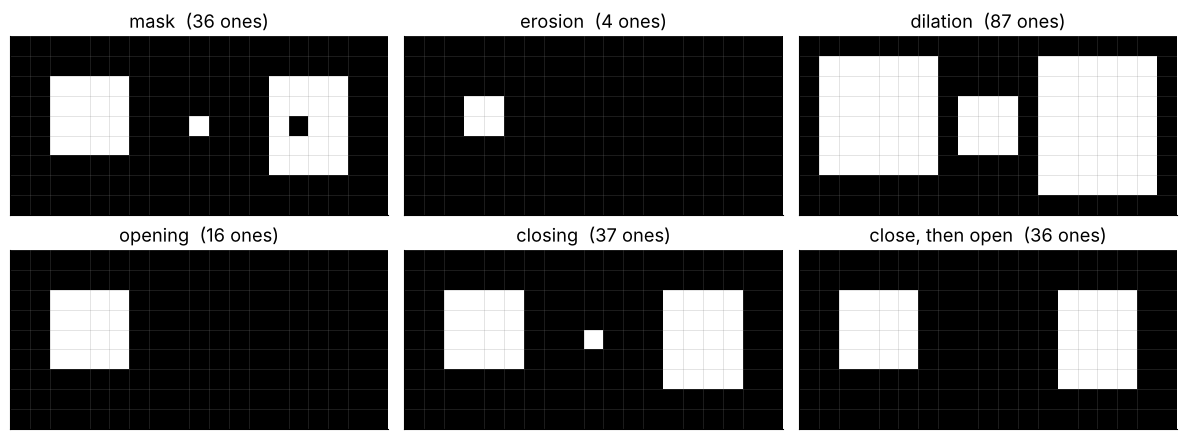

opening          : speck kept? False | hole filled? False | blob A intact? True | blob B present? False
closing          : speck kept? True | hole filled? True | blob A intact? True | blob B present? True
close, then open : speck kept? False | hole filled? True | blob A intact? True | blob B present? True


In [56]:
toy = np.zeros((9, 19), dtype=np.uint8)
toy[2:6, 2:6] = 1            # solid blob A (4 x 4)
toy[4, 9] = 1                # a speck
toy[2:7, 13:17] = 1          # blob B (5 x 4) ...
toy[4, 14] = 0               # ... with a hole
K3 = np.ones((3, 3), dtype=np.uint8)

ops = {
    "mask": toy,
    "erosion": cv2.erode(toy, K3),
    "dilation": cv2.dilate(toy, K3),
    "opening": cv2.morphologyEx(toy, cv2.MORPH_OPEN, K3),
    "closing": cv2.morphologyEx(toy, cv2.MORPH_CLOSE, K3),
    "close, then open": cv2.morphologyEx(cv2.morphologyEx(toy, cv2.MORPH_CLOSE, K3), cv2.MORPH_OPEN, K3),
}
fig, axes = plt.subplots(2, 3, figsize=(12, 4.6))
for ax, (name, m) in zip(axes.ravel(), ops.items()):
    ax.imshow(m, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{name}  ({int(m.sum())} ones)")
    ax.set_xticks(np.arange(-0.5, 19, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 9, 1), minor=True)
    ax.grid(which="minor", color="0.5", lw=0.5)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
fig.tight_layout()
plt.show()
for name in ["opening", "closing", "close, then open"]:
    print(f"{name:17s}: speck kept? {bool(ops[name][4, 9])} | hole filled? {bool(ops[name][4, 14])} | blob A intact? {bool(ops[name][2:6, 2:6].all())} | blob B present? {bool(ops[name][2:7, 13:17].any())}")

Exactly as advertised: **opening** deletes the speck but also wipes out blob B, because the hole makes every pixel of B "touch" a 0 during the erosion. **Closing** fills the hole but keeps the speck. **Closing first, then opening** gets everything right here. Order matters, and so does the size of the structuring element: anything thinner than the element is at risk in an opening, any gap narrower than it gets bridged in a closing.

Now the real mask. We compare the raw mask $D \ge 16$ with several cleanups, using an elliptical $5 \times 5$ element (a rounder neighborhood than the square).

,FP,FN,IoU
raw (D >= 16),34,231,0.9289
opening,0,502,0.8640
closing,60,29,0.9763
"open, then close",0,416,0.8873
"close, then open",27,30,0.9847


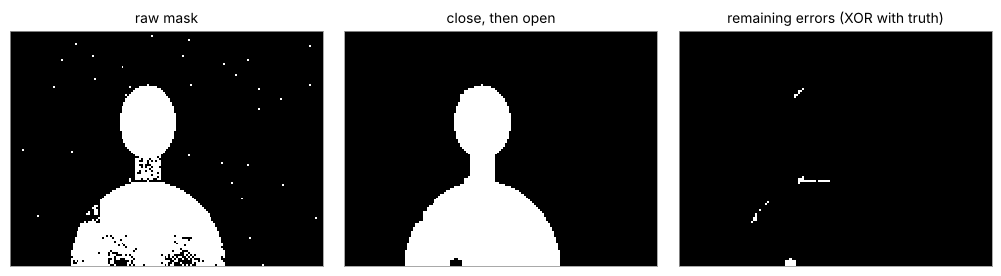

In [57]:
raw_mask = (D_img >= 16).astype(np.uint8)
K_ell = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
opened = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, K_ell)
closed = cv2.morphologyEx(raw_mask, cv2.MORPH_CLOSE, K_ell)
clean_mask = cv2.morphologyEx(closed, cv2.MORPH_OPEN, K_ell)             # close, then open
cleanups = {"raw (D >= 16)": raw_mask, "opening": opened, "closing": closed,
            "open, then close": cv2.morphologyEx(opened, cv2.MORPH_CLOSE, K_ell), "close, then open": clean_mask}
display(pd.DataFrame([dict(zip(["FP", "FN", "IoU"], mask_scores(m.astype(bool), person_mask))) for m in cleanups.values()],
                     index=list(cleanups)).round(4))
show_images([raw_mask * 255, clean_mask * 255, (clean_mask.astype(bool) ^ person_mask) * 255],
            ["raw mask", "close, then open", "remaining errors (XOR with truth)"], size=3.4)

The raw mask has dozens of specks in the room and holes where the person resembles the room (the neck against the bright wall, the shirt against the desk and the bookshelf). Opening alone removes the specks but also erodes the thin neck, so it *loses* accuracy, closing alone fills the holes, and closing then opening gives the best IoU, about 0.985. The remaining errors form a thin band along the outline, which is where the next idea helps.

### 9.2 Compositing: $O = M \odot I + (1 - M) \odot F$

With a 0/1 mask $M$ (1 = person), the output takes the frame's pixel where $M = 1$ and the virtual background's pixel where $M = 0$:

$$
O = M \odot I + (1 - M) \odot F .
$$

For each pixel exactly one of the two terms survives, because $M_{ij}$ and $1 - M_{ij}$ are 0 and 1 in some order. In NumPy: `M * I + (1 - M) * F` for numeric masks, or `np.where(M, I, F)` for boolean masks. For a color image of shape `(H, W, 3)`, give the mask a channel axis, `M[..., None]`, so that broadcasting applies it to all three channels.

> **Common pitfall.** Reversing the mask, $O = (1 - M) \odot I + M \odot F$, swaps the roles: the person is replaced by the beach and the room is kept. On paper the two formulas look almost the same, so check the definition: which value of $M$ means "person"? A second pitfall: with `uint8` arrays, `M * I` is fine (0 or the pixel), but any intermediate that goes below 0 or above 255 wraps. Compute in a wide type and convert at the end.

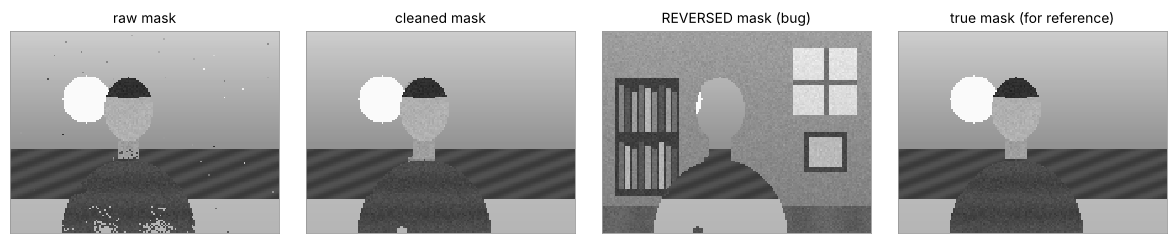

np.where(M, I, F) gives the same result: True


In [58]:
def composite(I, F, M):
    """O = M*I + (1-M)*F for a binary (0/1 or bool) or soft (float in [0, 1]) mask. Returns uint8."""
    M = np.asarray(M, dtype=np.float64)
    return to_uint8(M * I.astype(np.float64) + (1 - M) * F.astype(np.float64))


out_raw = composite(frame, beach, raw_mask)
out_clean = composite(frame, beach, clean_mask)
out_reversed = composite(frame, beach, 1 - clean_mask)
show_images([out_raw, out_clean, out_reversed, composite(frame, beach, person_mask)],
            ["raw mask", "cleaned mask", "REVERSED mask (bug)", "true mask (for reference)"], size=3.0)
print("np.where(M, I, F) gives the same result:", np.array_equal(np.where(clean_mask.astype(bool), frame, beach), out_clean))

### 9.3 Soft masks and alpha blending

A binary mask makes a hard cut: along the outline every pixel is either 100% person or 100% beach, so edges look jagged and, in a video, the noisy outline flickers from frame to frame. Real hair and blurry edges are *partly* person. The fix is a **soft mask** (an **alpha matte**) $\alpha \in [0, 1]$ per pixel:

$$
O = \alpha \odot I + (1 - \alpha) \odot F .
$$

This is the same formula with fractional weights: each output pixel is a **weighted average** (a convex combination) of the frame and the background, so it always lies between the two. A cheap way to get $\alpha$ is **feathering**: blur the binary mask, so that $\alpha$ ramps smoothly from 1 inside to 0 outside over a few pixels.

alpha: min 0.00, max 1.00; fraction of pixels with 0.01 < alpha < 0.99: 7.9%


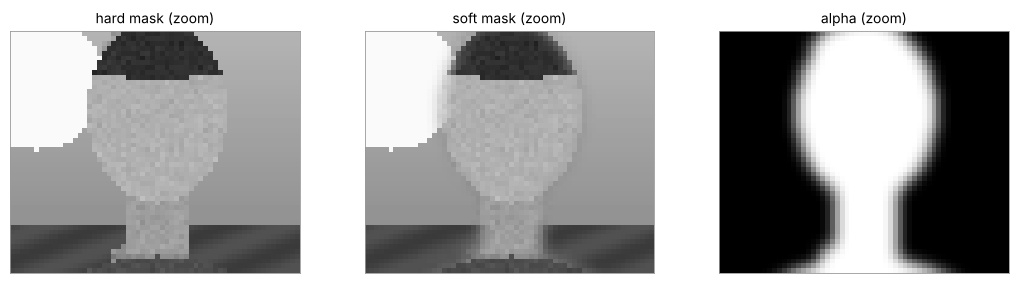

In [59]:
alpha = cv2.GaussianBlur(clean_mask.astype(np.float64), (7, 7), 1.5)    # feathered mask, values in [0, 1]
out_soft = composite(frame, beach, alpha)
print(f"alpha: min {alpha.min():.2f}, max {alpha.max():.2f}, fraction of pixels with 0.01 < alpha < 0.99: "
      f"{np.mean((alpha > 0.01) & (alpha < 0.99)):.1%}")
crop = (slice(30, 80), slice(40, 100))                                   # head and shoulder outline
show_images([out_clean[crop], out_soft[crop], (alpha[crop] * 255)],
            ["hard mask (zoom)", "soft mask (zoom)", "alpha (zoom)"], size=3.6)

The hard composite has a jagged staircase outline. In the soft composite the outline pixels are blends of person and beach, so the edge looks natural. Professional systems estimate $\alpha$ much more carefully (**matting**), today usually with a neural network, but the compositing formula stays exactly the same.

#### ✏️ Exercise 10: mask and composite by hand rules

Implement `virtual_background(I, B, F, tau)` for three `uint8` images of the same shape (frame `I`, background `B`, virtual background `F`): compute $D = |I - B|$ **without** `uint8` wraparound (widen to `int16`, `int32` or `float64` first, as in Section 1.3), the mask $M = 1$ where $D \ge \tau$ (note: $\ge$), and return the pair `(M, O)` with $M$ an integer 0/1 array and $O = M \odot I + (1 - M) \odot F$ as an integer array. Besides a tiny hand-made example, the checker runs your function on the scene of Section 8, with the background model `B_model` rounded to `uint8`.

In [60]:
# ✏️ Exercise 10: threshold mask and composite
def virtual_background(I, B, F, tau):
    """Return (M, O): M = (|I - B| >= tau) as 0/1 ints, O = M*I + (1-M)*F (I, B, F: uint8 arrays)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    I_t = np.array([[90, 14, 200], [20, 130, 33]], dtype=np.uint8)
    B_t = np.array([[70, 30, 185], [30, 100, 33]], dtype=np.uint8)
    F_t = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.uint8)
    M, O = virtual_background(I_t, B_t, F_t, 16)
    M, O = np.asarray(M), np.asarray(O)
    assert M.tolist() == [[1, 1, 0], [0, 1, 0]], f"mask should be [[1, 1, 0], [0, 1, 0]] (|14-30| = 16 counts, |20-30| = 10 does not), got {M.tolist()}"
    assert O.tolist() == [[90, 14, 3], [4, 130, 6]], f"composite should be [[90, 14, 3], [4, 130, 6]], got {O.tolist()}"
    B_u8 = to_uint8(B_model)                                  # the scene's background model, rounded to uint8
    M2, _ = virtual_background(frame, B_u8, beach, 16)
    M2 = np.asarray(M2).astype(bool)
    want = np.abs(frame.astype(np.int16) - B_u8.astype(np.int16)) >= 16
    assert M2.shape == want.shape, f"on the scene, the mask should have shape {want.shape}, got {M2.shape}"
    assert np.array_equal(M2, want), (f"on the scene (frame vs. B_model rounded to uint8), {int((M2 != want).sum())} "
                                      "mask pixels differ from |I - B| >= 16 computed without wraparound")


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def virtual_background(I, B, F, tau):
    D = np.abs(I.astype(np.float64) - B.astype(np.float64))
    M = (D >= tau).astype(np.int64)
    O = M * I.astype(np.int64) + (1 - M) * F.astype(np.int64)
    return M, O
```
The test contains both traps. Pixel $(1, 0)$: $|20 - 30| = 10 < 16$ is background, but `uint8` arithmetic computes $20 - 30 = 246$ and would wrongly call it foreground. Pixel $(0, 1)$: $|14 - 30| = 16$ is foreground only because the rule is $\ge$, and with $>$ it would be background. Widening the type first makes every case correct by construction, and for `uint8` inputs, `int16` or `int32` work just as well as `float64`. Only a **float** background, such as the averaged `B_model` itself, must not be cast to an integer type: that would truncate it and flip pixels whose difference is close to $\tau$.
</details>

### 9.4 A short video, and when background subtraction fails

First the good news. The background model knows nothing about the person, so the method works wherever the person is. Here is a four-frame clip in which the person walks across the room, and each frame goes through the full pipeline (difference, threshold $\tau = 16$, close, open, feathered composite).

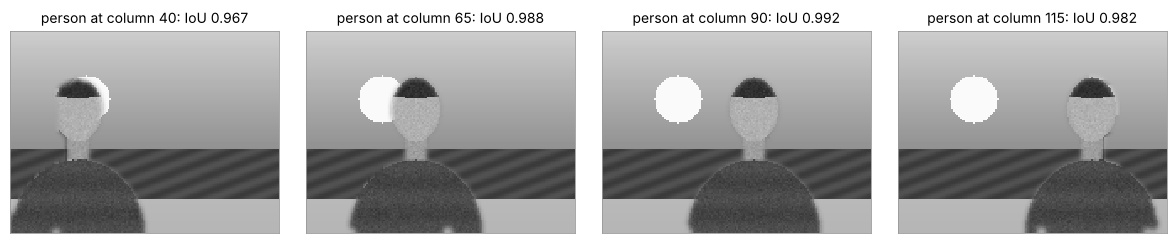

In [61]:
def pipeline_mask(I, B=B_model, tau=16):
    """Difference, threshold (>=), then close and open with the elliptical 5x5 element."""
    raw = (np.abs(I.astype(np.float64) - B) >= tau).astype(np.uint8)
    return cv2.morphologyEx(cv2.morphologyEx(raw, cv2.MORPH_CLOSE, K_ell), cv2.MORPH_OPEN, K_ell).astype(bool)


clip_rng = np.random.default_rng(99)                                   # separate noise generator for the clip
clip_out, clip_titles = [], []
for cx in [40, 65, 90, 115]:
    val, truth = make_person(cx=cx)
    I_t = to_uint8(np.where(truth, val, room) + clip_rng.normal(0, SIGMA_CAM, room.shape))
    m = pipeline_mask(I_t)
    alpha_t = cv2.GaussianBlur(m.astype(np.float64), (7, 7), 1.5)
    clip_out.append(composite(I_t, beach, alpha_t))
    clip_titles.append(f"person at column {cx}: IoU {mask_scores(m, truth)[2]:.3f}")
show_images(clip_out, clip_titles, size=3.0)

The mask follows the person through the room with an IoU between about 0.97 and 0.99 in every frame. It is lowest at column 40, where the dark shirt passes in front of the similarly dark bookshelf. Now the bad news. The method rests on one assumption: **a pixel changes only if the person covers it**. Three everyday situations break it. We simulate each one and run the same pipeline.

,FP,FN,IoU
normal,20,7,0.993
shadow,1296,6,0.739
camouflage,0,1277,0.654
lights dimmed 15%,15178,714,0.158


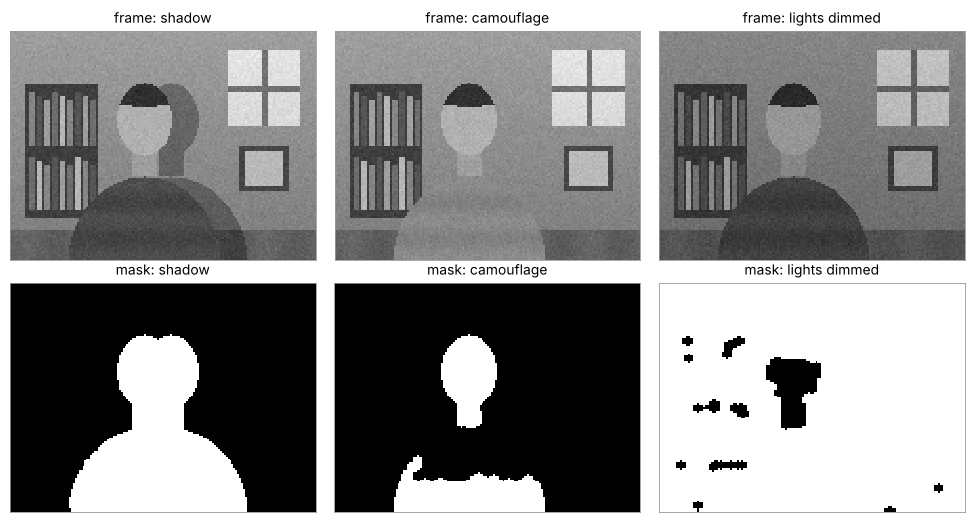

In [62]:


# 1) Shadow: the person blocks part of the light, darkening the wall beside them by 30%.
shadow_val, shadow_shape = make_person(cx=84)                    # the same silhouette, shifted right
shadow_region = shadow_shape & ~person_mask
scene_shadow = np.where(person_mask, person_val, np.where(shadow_region, 0.7 * room, room))
# 2) Camouflage: a light-gray shirt, about as bright as the wall behind it.
camo_val, _ = make_person(cx=70, shirt=133.0)
scene_camo = np.where(person_mask, camo_val, room)
# 3) Lighting change: someone dims the lights by 15% after the background was recorded.
scene_dim = 0.85 * scene_true

cases = {"normal": scene_true, "shadow": scene_shadow, "camouflage": scene_camo, "lights dimmed 15%": scene_dim}
case_frames = {name: capture(sc) for name, sc in cases.items()}
case_masks = {name: pipeline_mask(I) for name, I in case_frames.items()}
display(pd.DataFrame([dict(zip(["FP", "FN", "IoU"], mask_scores(m, person_mask))) for m in case_masks.values()],
                     index=list(case_masks)).round(3))
show_images([case_frames["shadow"], case_frames["camouflage"], case_frames["lights dimmed 15%"],
             case_masks["shadow"] * 255, case_masks["camouflage"] * 255, case_masks["lights dimmed 15%"] * 255],
            ["frame: shadow", "frame: camouflage", "frame: lights dimmed",
             "mask: shadow", "mask: camouflage", "mask: lights dimmed"], ncols=3, size=3.3)

Each failure has its own signature:

* **Shadow** (false positives): a shadow really does change the wall's pixels, by 30% here, far more than the noise. The method has no way to know that "darker wall" is not "person".
* **Camouflage** (false negatives): where the shirt is about as bright as the wall behind it, $|I - B|$ stays below $\tau$ and the torso disappears from the mask. In color, a different hue may still separate them, but in gray it is hopeless.
* **Lighting change** (false positives almost everywhere): a 15% global dimming changes a wall pixel of brightness 140 by about 21 levels, more than $\tau = 16$, so nearly the whole room is flagged.

The lighting change is the easiest to repair, because it affects all pixels the same way: $I \approx g \cdot B$ for room pixels, with one unknown **gain** $g$. Estimate $g$ robustly as the **median** of the per-pixel ratios $I/B$ (the person covers only about a fifth of the image, so the median ignores them), divide the frame by $g$, and subtract as before.

In [63]:
I_dim = case_frames["lights dimmed 15%"]
gain = np.median(I_dim / B_model)
fixed_mask = pipeline_mask(I_dim / gain)
fp, fn, iou = mask_scores(fixed_mask, person_mask)
print(f"estimated gain g = {gain:.3f} (true 0.85), after dividing by g: FP {fp}, FN {fn}, IoU {iou:.3f}")

estimated gain g = 0.845 (true 0.85); after dividing by g: FP 42, FN 5, IoU 0.987


One robust statistic turns a useless mask into a good one. Real systems go further: they **update the background model** slowly over time, $B \leftarrow (1 - a)\,B + a\,I$ with a small rate $a$ applied to background pixels, so gradual lighting changes are absorbed, they model each pixel as a **mixture of Gaussians** (to handle flickering screens or moving leaves), they detect shadows with color (a shadow lowers brightness but keeps the hue), and today they mostly use **neural networks** that segment people directly from a single frame, needing no empty-room photo at all. The compositing step, $O = \alpha \odot I + (1 - \alpha) \odot F$, remains the same.

**Quick check 8.** (a) A frame was captured with every pixel 10% brighter than when the background was recorded. With $\tau = 16$, which room pixels are falsely flagged? (b) Your mask has many one-pixel specks and a few one-pixel holes inside the person. Which operation would you apply first, and why? (c) For a soft mask value $\alpha = 0.25$, frame pixel $I = 200$, background pixel $F = 40$: what is $O$?

<details>
<summary>Answer</summary>

(a) A room pixel of brightness $b$ changes by $0.1\,b$, which reaches 16 when $b \ge 160$: the bright parts of the room (the window, the picture), while darker parts survive. A multiplicative change hits bright pixels hardest. (b) Closing first: an opening applied to a shape with holes can erode it badly (Section 9.1), while a closing fills the holes and leaves the specks to the opening that follows. (c) $O = 0.25 \cdot 200 + 0.75 \cdot 40 = 50 + 30 = 80$.
</details>

## 10. Linear features, norms and similarity

### 10.1 $\mathbf z = W\mathbf x$: a bank of dot-product filters

Flatten an $H \times W$ image (row-major) into a vector $\mathbf x \in \mathbb R^{d}$ with $d = HW$. A **linear feature** is a weighted sum of all the pixels, $z = \mathbf w^\top \mathbf x = \sum_j w_j x_j$, with one weight per pixel. Stack $K$ such weight vectors as the rows of a matrix $W \in \mathbb R^{K \times d}$ and you compute $K$ features at once:

$$
\mathbf z = W\mathbf x \in \mathbb R^{K}, \qquad z_k = \mathbf w_k^\top \mathbf x .
$$

Each row $\mathbf w_k$ can be reshaped back to $H \times W$ and viewed as a small image, a **filter**: the feature is large when the image "looks like" the filter (bright where the filter is positive, dark where it is negative). This is exactly what one layer of a neural network computes, and a convolutional layer is the same idea with a small filter slid over every position (Section 11.2).

Example: a $3 \times 3$ patch and five hand-made filters.

$$
X = \begin{bmatrix} 2 & 7 & 1 \\ 0 & 5 & 3 \\ 4 & 6 & 8 \end{bmatrix}, \qquad
\mathbf x = (2, 7, 1, 0, 5, 3, 4, 6, 8)^\top .
$$

| filter (as a $3\times3$ weight image) | what it measures | $z_k$ |
|---|---|---|
| ones on row 0 | sum of the top row | $2 + 7 + 1 = 10$ |
| ones on column 0 | sum of the left column | $2 + 0 + 4 = 6$ |
| $-1$ on column 0, $+1$ on column 2 | left-to-right change (a vertical edge) | $(1 + 3 + 8) - (2 + 0 + 4) = 6$ |
| $-1$ on row 0, $+1$ on row 2 | top-to-bottom change (a horizontal edge) | $(4 + 6 + 8) - (2 + 7 + 1) = 8$ |
| $4$ at the center, $-1$ at its 4 neighbors | center brighter than its surroundings | $20 - (7 + 0 + 3 + 6) = 4$ |

Filters whose weights sum to zero (the last three) ignore the overall brightness: adding the same constant to every pixel leaves them unchanged. They respond only to **differences** between pixels, which is what edges are.

,z (row-major x),"z (column-major x, a bug)"
top-row sum,10,6
left-column sum,6,10
left-to-right change,6,8
top-to-bottom change,8,6
center-surround,4,4


W shape: (5, 9) | x shape: (9,) | z shape: (5,)
brightness-invariant? z of X+50 minus z of X: [150 150   0   0   0]


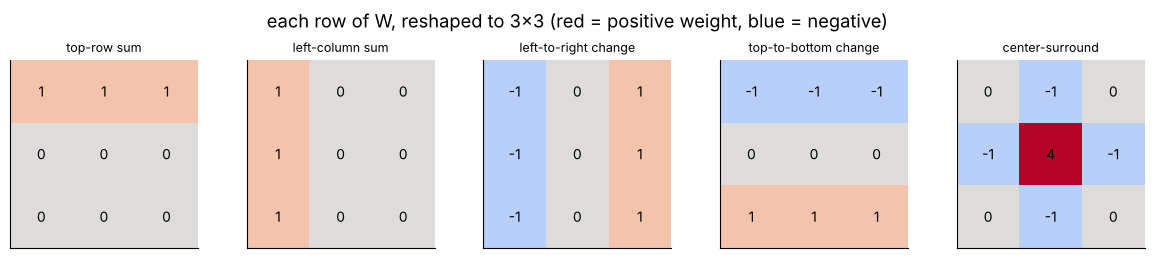

In [64]:
X_patch = np.array([[2, 7, 1],
                    [0, 5, 3],
                    [4, 6, 8]])
filters = {
    "top-row sum": [[1, 1, 1], [0, 0, 0], [0, 0, 0]],
    "left-column sum": [[1, 0, 0], [1, 0, 0], [1, 0, 0]],
    "left-to-right change": [[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]],
    "top-to-bottom change": [[-1, -1, -1], [0, 0, 0], [1, 1, 1]],
    "center-surround": [[0, -1, 0], [-1, 4, -1], [0, -1, 0]],
}
W_bank = np.array([np.ravel(f) for f in filters.values()])          # shape (5, 9): one filter per ROW
z_C = W_bank @ X_patch.ravel(order="C")
z_F = W_bank @ X_patch.ravel(order="F")
display(pd.DataFrame({"z (row-major x)": z_C, "z (column-major x, a bug)": z_F}, index=list(filters)))
print("W shape:", W_bank.shape, "| x shape:", X_patch.ravel().shape, "| z shape:", z_C.shape)
print("brightness-invariant? z of X+50 minus z of X:", W_bank @ (X_patch + 50).ravel() - z_C)

fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
for ax, (name, f) in zip(axes, filters.items()):
    f = np.array(f)
    ax.imshow(f, cmap="coolwarm", vmin=-4, vmax=4)
    for (i, j), v in np.ndenumerate(f):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=10)
    ax.set_title(name, fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("each row of W, reshaped to 3x3 (red = positive weight, blue = negative)")
fig.tight_layout()
plt.show()

Two lessons from the table. First, the zero-sum filters gave the same $z$ after we added 50 to every pixel (the last printout shows the increase: 150 for the top-row sum, 150 for the column sum, 0 for the three zero-sum filters). Second, flattening the patch **column-major** while the filters were written for row-major order produced different features: the row sum and the column sum traded places, and so did the two edge detectors. Column-major flattening of $X$ is the same as row-major flattening of $X^\top$, so every filter is silently applied to the **transposed** image. The symmetric center-surround filter is the only one that does not notice.

### 10.2 Norms: measuring the size of a vector

A **norm** measures the length of a vector. The three you will meet most:

$$
\|\mathbf v\|_1 = \sum_i |v_i|, \qquad \|\mathbf v\|_2 = \sqrt{\sum_i v_i^2}, \qquad \|\mathbf v\|_\infty = \max_i |v_i| .
$$

For $\mathbf v = (3, -4, 12)$: $\|\mathbf v\|_1 = 3 + 4 + 12 = 19$, $\|\mathbf v\|_2 = \sqrt{9 + 16 + 144} = \sqrt{169} = 13$, $\|\mathbf v\|_\infty = 12$. Always $\|\mathbf v\|_\infty \le \|\mathbf v\|_2 \le \|\mathbf v\|_1$. The $L_2$ norm is the ordinary straight-line length (Pythagoras in $d$ dimensions), and $L_1$ is the "taxicab" distance along the axes. Dividing a nonzero vector by its $L_2$ norm gives the **unit vector** $\hat{\mathbf v} = \mathbf v/\|\mathbf v\|_2$, which keeps the direction and has length 1: here $\hat{\mathbf v} = (3/13, -4/13, 12/13)$.

Each norm has its own "unit circle" $\{\mathbf v : \|\mathbf v\| = 1\}$: a diamond for $L_1$, a circle for $L_2$, a square for $L_\infty$.

L1 = 19.0 | L2 = 13.0 | Linf = 12.0
unit vector: [ 0.2308 -0.3077  0.9231] -> its L2 norm: 1.0

For a MATRIX, np.linalg.norm means something else:
  np.linalg.norm(A)    = 5.4772  (Frobenius = L2 of all entries)
  np.linalg.norm(A, 1) = 6.0  (max column sum, NOT the sum of |entries|)
  np.abs(A).sum()      = 10  (L1 of all entries)
  row-wise L2 norms    = [2.2361 5.    ]  (use axis=1 for one norm per row)


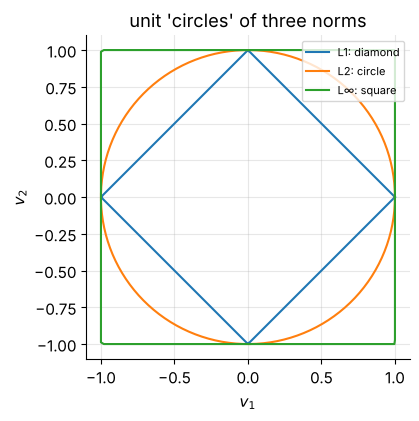

In [65]:
v_norm = np.array([3, -4, 12])
print("L1 =", np.linalg.norm(v_norm, 1), "| L2 =", np.linalg.norm(v_norm), "| Linf =", np.linalg.norm(v_norm, np.inf))
print("unit vector:", v_norm / np.linalg.norm(v_norm), "-> its L2 norm:", np.linalg.norm(v_norm / np.linalg.norm(v_norm)))

A_mat = np.array([[1, -2], [3, 4]])
print("\nFor a MATRIX, np.linalg.norm means something else:")
print("  np.linalg.norm(A)    =", round(float(np.linalg.norm(A_mat)), 4), " (Frobenius = L2 of all entries)")
print("  np.linalg.norm(A, 1) =", np.linalg.norm(A_mat, 1), " (max column sum, NOT the sum of |entries|)")
print("  np.abs(A).sum()      =", np.abs(A_mat).sum(), " (L1 of all entries)")
print("  row-wise L2 norms    =", np.linalg.norm(A_mat, axis=1).round(4), " (use axis=1 for one norm per row)")

theta = np.linspace(0, 2 * np.pi, 400)
fig, ax = plt.subplots(figsize=(4.2, 4.2))
for p, lab in [(1, "L1: diamond"), (2, "L2: circle"), (np.inf, "L∞: square")]:
    pts = np.stack([np.cos(theta), np.sin(theta)])
    pts = pts / np.linalg.norm(pts, ord=p, axis=0)
    ax.plot(pts[0], pts[1], label=lab)
ax.set_aspect("equal")
ax.set_xlabel("$v_1$")
ax.set_ylabel("$v_2$")
ax.set_title("unit 'circles' of three norms")
ax.legend(fontsize=8, loc="upper right")
plt.show()

### 10.3 Dot product versus cosine similarity

The dot product has a geometric meaning: $\mathbf a^\top \mathbf b = \|\mathbf a\|_2\,\|\mathbf b\|_2\cos\theta$, where $\theta$ is the angle between the vectors. Solving for the angle's cosine gives the **cosine similarity**

$$
\cos(\mathbf a, \mathbf b) = \frac{\mathbf a^\top \mathbf b}{\|\mathbf a\|_2\,\|\mathbf b\|_2} = \hat{\mathbf a}^\top \hat{\mathbf b} \in [-1, 1] ,
$$

the dot product of the two **unit** vectors. It is $1$ for vectors pointing the same way, $0$ for perpendicular ones, $-1$ for opposite ones, and it **ignores length**: multiplying either vector by a positive number changes the dot product but not the cosine. For images, length is mostly exposure: the same scene photographed twice as bright has $\mathbf x \to 2\mathbf x$. Cosine similarity compares *patterns*, while the raw dot product rewards sheer brightness.

The **Euclidean distance** connects the two: expanding the square,

$$
\|\mathbf a - \mathbf b\|_2^2 = \|\mathbf a\|_2^2 + \|\mathbf b\|_2^2 - 2\,\mathbf a^\top \mathbf b ,
$$

and for unit vectors this becomes $2 - 2\cos(\mathbf a, \mathbf b)$. So **among unit vectors, the nearest neighbor in Euclidean distance is the one with the largest cosine**. Without normalization, the three criteria can disagree completely. Example: query $\mathbf z = (3, 4)$ (so $\|\mathbf z\|_2 = 5$) and three prototypes:

| prototype | $\mathbf p^\top \mathbf z$ | $\lVert \mathbf p\rVert _2$ | cosine | $\lVert \mathbf z - \mathbf p\rVert _2$ |
|---|---|---|---|---|
| $\mathbf p_1 = (1, 1)$ | 7 | $\sqrt 2 \approx 1.414$ | $7/(5\sqrt2) \approx 0.990$ | $\sqrt{13} \approx 3.606$ |
| $\mathbf p_2 = (8, 0)$ | **24** | 8 | $24/40 = 0.600$ | $\sqrt{41} \approx 6.403$ |
| $\mathbf p_3 = (0, 3)$ | 12 | 3 | $12/15 = 0.800$ | $\sqrt{10} \approx$ **3.162** |

The largest dot product picks $\mathbf p_2$ (it is simply the longest vector), the smallest distance picks $\mathbf p_3$ (it has about the right length), and the largest cosine picks $\mathbf p_1$, the one pointing almost exactly the same way as $\mathbf z$. Three criteria, three different answers. Read the question.

> **Common pitfall: normalizing only one side.** To rank prototypes for one query, the cosine score is $\mathbf p_k^\top \mathbf z / (\|\mathbf p_k\|\,\|\mathbf z\|)$. If you normalize **only the query**, every score is divided by the same $\|\mathbf z\|$, so the ranking is exactly that of the raw dot product: here still $\mathbf p_2$, wrong. If you normalize **only the prototypes**, the ranking happens to match cosine ($\|\mathbf z\|$ is a common factor), but the *values* are not cosines: they are not in $[-1, 1]$ and cannot be compared with a threshold such as "match if $\cos > 0.9$", nor across different queries. Normalize both.

In [66]:
z_q = np.array([3.0, 4.0])
P_toy = np.array([[1.0, 1.0], [8.0, 0.0], [0.0, 3.0]])
P_norms = np.linalg.norm(P_toy, axis=1)
sim = pd.DataFrame({
    "dot p.z": P_toy @ z_q,
    "cosine": P_toy @ z_q / (P_norms * np.linalg.norm(z_q)),
    "Euclidean dist": np.linalg.norm(P_toy - z_q, axis=1),
    "only z normalized": P_toy @ (z_q / np.linalg.norm(z_q)),
    "only p normalized": (P_toy / P_norms[:, None]) @ z_q,
    "dist of unit vectors": np.linalg.norm(P_toy / P_norms[:, None] - z_q / np.linalg.norm(z_q), axis=1),
}, index=["p1", "p2", "p3"])
display(sim.round(4))
best = {c: sim[c].idxmin() if "dist" in c else sim[c].idxmax() for c in sim.columns}
print("winner per criterion:", best)

,dot p.z,cosine,Euclidean dist,only z normalized,only p normalized,dist of unit vectors
p1,7.0,0.9899,3.6056,1.4,4.9497,0.1418
p2,24.0,0.6000,6.4031,4.8,3.0000,0.8944
p3,12.0,0.8000,3.1623,2.4,4.0000,0.6325


winner per criterion: {'dot p.z': 'p2', 'cosine': 'p1', 'Euclidean dist': 'p3', 'only z normalized': 'p2', 'only p normalized': 'p1', 'dist of unit vectors': 'p1'}


**Quick check 9.** (a) $\mathbf a = (1, 2, 2)$ and $\mathbf b = (2, 4, 4)$. What are $\mathbf a^\top\mathbf b$ and $\cos(\mathbf a, \mathbf b)$? (b) True or false: if $\cos(\mathbf a, \mathbf b) = 1$ then $\mathbf a = \mathbf b$. (c) A filter has weights that sum to 0. What happens to its output when the image gets brighter by a constant 30 at every pixel? And when it gets twice as contrasty ($\mathbf x \to 2\mathbf x$)?

<details>
<summary>Answer</summary>

(a) $\mathbf a^\top\mathbf b = 2 + 8 + 8 = 18$, and $\|\mathbf a\| = 3$, $\|\mathbf b\| = 6$, so $\cos = 18/18 = 1$. (b) False: cosine 1 means same **direction** ($\mathbf b = c\,\mathbf a$ with $c > 0$), as in (a). (c) Adding 30 everywhere adds $30\sum_j w_j = 0$: no change. Doubling the image doubles the output, since the feature is linear.
</details>

#### ✏️ Exercise 11: cosine scores against a set of prototypes

Implement `cosine_scores(z, P)`: for a query vector `z` of shape `(d,)` and prototypes `P` of shape `(K, d)` (one per row), return the `K` cosine similarities. Normalize **both** sides. Then `nearest_by_cosine(z, P)` should return the index of the best prototype.

In [67]:
# ✏️ Exercise 11: cosine similarity with every prototype
def cosine_scores(z, P):
    """Return an array of K cosine similarities between z (d,) and each row of P (K, d)."""
    # YOUR CODE HERE
    raise NotImplementedError


def nearest_by_cosine(z, P):
    """Index of the prototype with the largest cosine similarity."""
    return int(np.argmax(cosine_scores(z, P)))


def _test():
    s = np.asarray(cosine_scores(z_q, P_toy), dtype=float)
    assert s.shape == (3,), f"expected 3 scores, got shape {s.shape}"
    assert np.allclose(s, [0.98995, 0.6, 0.8], atol=1e-4), f"expected [0.98995, 0.6, 0.8], got {s.round(5)}"
    assert nearest_by_cosine(z_q, P_toy) == 0, "p1 has the largest cosine"
    assert np.allclose(cosine_scores(7.5 * z_q, 0.1 * P_toy), s), "cosine must not change when z or P is rescaled"
    s2 = np.asarray(cosine_scores(np.array([1.0, 0, -1]), np.array([[2.0, 0, -2], [-1, 0, 1], [0, 5, 0]])))
    assert np.allclose(s2, [1, -1, 0]), f"same / opposite / perpendicular directions should give 1, -1, 0, got {s2}"


run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def cosine_scores(z, P):
    z = np.asarray(z, dtype=float)
    P = np.asarray(P, dtype=float)
    return (P @ z) / (np.linalg.norm(P, axis=1) * np.linalg.norm(z))
```
`P @ z` computes all $K$ dot products at once, and `np.linalg.norm(P, axis=1)` gives one norm per prototype (without `axis=1` you would get a single Frobenius norm of the whole matrix, a classic bug).
</details>

## 11. Similarity in action: prototypes and template matching

### 11.1 Nearest-prototype classification of handwritten digits

scikit-learn ships 1,797 handwritten digits as tiny $8 \times 8$ grayscale images with values $0..16$. Flattened, each is a vector $\mathbf x \in \mathbb R^{64}$. The simplest possible classifier:

1. **Prototypes.** For each digit class $k = 0..9$, average the training images of that class: $\mathbf p_k = \frac{1}{n_k}\sum_{i:\,y_i = k}\mathbf x_i$. The class mean is the vector closest to all class members in total squared distance (Section 2 showed this in one dimension, and it holds per coordinate).
2. **Prediction.** Assign a new image to the most similar prototype.

Which similarity? We compare the dot product, (negative) Euclidean distance, cosine similarity, and **Pearson correlation** (the cosine of the *mean-centered* vectors, which also ignores a constant brightness offset).

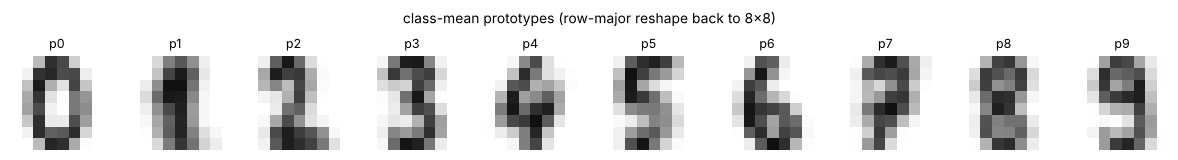

{'dot': 0.8699, '-Euclidean': 0.8832, 'cosine': 0.8843, 'Pearson': 0.8832}


In [68]:
X_dig, y_dig = load_digits(return_X_y=True)                     # X_dig: (1797, 64), values 0..16
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(X_dig, y_dig, test_size=0.5, random_state=SEED, stratify=y_dig)
protos = np.stack([Xd_tr[yd_tr == k].mean(axis=0) for k in range(10)])   # (10, 64): one prototype per row


def similarity_scores(Xq, P, how):
    """Score matrix (n_queries, n_prototypes), where larger means more similar."""
    if how == "dot":
        return Xq @ P.T
    if how == "-Euclidean":
        return -np.linalg.norm(Xq[:, None, :] - P[None, :, :], axis=2)
    if how == "cosine":
        Xn = Xq / np.linalg.norm(Xq, axis=1, keepdims=True)
        Pn = P / np.linalg.norm(P, axis=1, keepdims=True)
        return Xn @ Pn.T
    if how == "Pearson":
        return similarity_scores(Xq - Xq.mean(axis=1, keepdims=True), P - P.mean(axis=1, keepdims=True), "cosine")
    raise ValueError(how)


fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for k, ax in enumerate(axes):
    ax.imshow(protos[k].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"p{k}", fontsize=9)
    ax.axis("off")
fig.suptitle("class-mean prototypes (row-major reshape back to 8x8)", fontsize=10)
fig.tight_layout()
plt.show()
methods_sim = ["dot", "-Euclidean", "cosine", "Pearson"]
print({m: round(float((similarity_scores(Xd_te, protos, m).argmax(axis=1) == yd_te).mean()), 4) for m in methods_sim})

On clean data all four work about equally well (around 87% to 88%, impressive for a classifier with no training beyond averaging). The differences appear when the **exposure** varies, which happens constantly with real cameras and scanners. We simulate two situations: every *query* image gets its own random gain $g \in [0.25, 4]$ (some scans too faint, some too dark), and the *prototypes* come from batches scanned with different gains.

In [69]:
g_exp = np.random.default_rng(7)
q_gain = np.exp(g_exp.uniform(np.log(0.25), np.log(4.0), size=(len(Xd_te), 1)))   # one gain per query image
p_gain = np.exp(g_exp.uniform(np.log(0.4), np.log(2.5), size=(10, 1)))              # one gain per prototype
exposure_cases = {
    "clean": (Xd_te, protos),
    "query gains": (q_gain * Xd_te, protos),
    "prototype gains": (Xd_te, p_gain * protos),
    "both gains": (q_gain * Xd_te, p_gain * protos),
    "both gains + offset 3": (q_gain * Xd_te + 3, p_gain * protos),
}
acc_table = pd.DataFrame({case: {m: (similarity_scores(Xq, Pp, m).argmax(axis=1) == yd_te).mean() for m in methods_sim}
                          for case, (Xq, Pp) in exposure_cases.items()}).T
display(acc_table.round(4))
print("prototype gains:", p_gain.ravel().round(2))
pred_dot = similarity_scores(Xd_te, p_gain * protos, "dot").argmax(axis=1)
print("dot product with prototype gains -> how often each class is predicted:", np.bincount(pred_dot, minlength=10))

,dot,-Euclidean,cosine,Pearson
clean,0.8699,0.8832,0.8843,0.8832
query gains,0.8699,0.8676,0.8843,0.8832
prototype gains,0.2392,0.4983,0.8843,0.8832
both gains,0.2392,0.4071,0.8843,0.8832
both gains + offset 3,0.1713,0.3993,0.8799,0.8832


prototype gains: [0.48 0.64 1.17 2.29 1.79 1.29 1.04 0.41 2.05 0.45]
dot product with prototype gains -> how often each class is predicted: [  0   0   0 510  63   0   0   0 326   0]


Read the table column by column:

* **Dot product.** Query gains do not change its predictions at all: multiplying a query by $g > 0$ multiplies all ten of its scores by $g$, and the winner stays the same (this is the "normalize only the query" situation from 10.3 in disguise). Prototype gains are fatal: accuracy falls to about 24%, because the prototypes scanned with the largest gains win for almost every query.
* **Euclidean distance** is hurt by both kinds of gain, since a rescaled vector is far from its prototype even when the pattern matches.
* **Cosine similarity** is completely unaffected by any positive gain on either side: identical accuracy in the first four rows. Only the constant **offset** in the last row (a gray haze added to every pixel) moves it slightly, because adding a constant changes a vector's direction.
* **Pearson correlation** subtracts each vector's mean before taking the cosine, so it is immune to gains *and* offsets: identical accuracy in every row.

> **Key idea.** Choose the similarity whose invariances match the nuisance in your data. Gains: cosine. Gains and offsets: Pearson (zero-mean, normalized). Absolute brightness actually matters: Euclidean. The raw dot product is rarely the right choice when vector lengths vary for reasons unrelated to the class.

### 11.2 Template matching: similarity at every position

To **find** a known pattern (a logo, an icon, a marker) inside a larger image, slide the template $T$ ($h \times w$) over every position $(r, c)$, cut out the window $P_{rc}$ of the same size, and score how similar the window is to the template. The four classic scores are the four similarities you know, applied to the flattened window and template:

| OpenCV name | score at $(r, c)$ | it is ... | best = |
|---|---|---|---|
| `TM_CCORR` | $\sum P_{rc} \odot T$ | dot product | max |
| `TM_SQDIFF` | $\sum (P_{rc} - T)^2$ | squared Euclidean distance | min |
| `TM_CCORR_NORMED` | $\dfrac{\sum P_{rc} \odot T}{\lVert P_{rc}\rVert \,\lVert T\rVert }$ | cosine similarity | max |
| `TM_CCOEFF_NORMED` | cosine of $P_{rc} - \bar P_{rc}$ and $T - \bar T$ | Pearson correlation (zero-mean NCC) | max |

Our test scene contains a target icon (a ring with a dot) printed with **low contrast on a bright label**, and three distractors: a bright lamp, a bright flat panel and a plus sign. The template is the icon as stored in our database, with *different* brightness and contrast.

In [70]:
yy_t, xx_t = np.mgrid[-7:8, -7:8]
rad_t = np.sqrt(yy_t ** 2 + xx_t ** 2)
icon = ((rad_t >= 4.5) & (rad_t <= 6.5)).astype(float) + (rad_t <= 2).astype(float)   # ring + center dot, 15 x 15
template = (40 + 160 * icon).astype(np.float32)                    # stored template: dark background, bright icon

H_T, W_T = 96, 160
Yg, Xg = np.mgrid[0:H_T, 0:W_T].astype(float)
target_rc = (55, 92)                                               # top-left corner of the true target
search = 70 + 50 * Xg / W_T                                        # background with a brightness gradient
search[(Yg - 30) ** 2 + (Xg - 125) ** 2 <= 16 ** 2] = 245          # distractor 1: a bright lamp
search[60:85, 15:45] = 200                                         # distractor 2: a bright flat panel
search[20:35, 52:55] = 170                                         # distractor 3: a plus sign ...
search[26:29, 46:61] = 170
r0, c0 = target_rc
search[r0 - 6:r0 + 21, c0 - 6:c0 + 21] = 200                       # a bright label ...
search[r0:r0 + 15, c0:c0 + 15] = 200 + 40 * icon                   # ... with the icon printed on it (low contrast)
search = to_uint8(search + np.random.default_rng(0).normal(0, 3, search.shape)).astype(np.float32)

tm_methods = {"dot (TM_CCORR)": cv2.TM_CCORR, "squared distance (TM_SQDIFF)": cv2.TM_SQDIFF,
              "cosine (TM_CCORR_NORMED)": cv2.TM_CCORR_NORMED, "Pearson (TM_CCOEFF_NORMED)": cv2.TM_CCOEFF_NORMED}
tm_maps, tm_best = {}, {}
for name, m in tm_methods.items():
    res = cv2.matchTemplate(search, template, m)                   # shape (H - h + 1, W - w + 1) = (82, 146)
    tm_maps[name] = res
    tm_best[name] = np.unravel_index(np.argmin(res) if m == cv2.TM_SQDIFF else np.argmax(res), res.shape)
    print(f"{name:28s} best top-left corner {tuple(int(v) for v in tm_best[name])}"
          f" -> {'found the target' if tm_best[name] == target_rc else 'WRONG'}")

dot (TM_CCORR)               best top-left corner (17, 120) -> WRONG
squared distance (TM_SQDIFF) best top-left corner (16, 91) -> WRONG
cosine (TM_CCORR_NORMED)     best top-left corner (55, 92) -> found the target
Pearson (TM_CCOEFF_NORMED)   best top-left corner (55, 92) -> found the target


The dot product is drawn to the brightest region (the lamp), and the squared distance is drawn to a region whose *brightness* resembles the template's (it does not care about the pattern, only about matching numbers). Both normalized scores find the target. Let us implement the Pearson score from scratch, check it against OpenCV, and look at **how clearly** each normalized score separates the target from everything else.

from scratch vs cv2.TM_CCOEFF_NORMED: max abs difference = 2.2e-05
cosine (TM_CCORR_NORMED)     peak 0.839, best elsewhere 0.806, margin 0.032
Pearson (TM_CCOEFF_NORMED)   peak 0.991, best elsewhere 0.292, margin 0.698


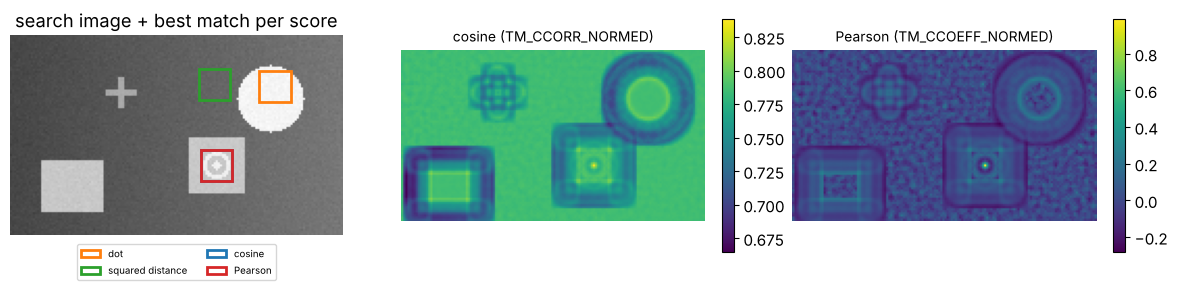

In [71]:
def ncc_map(img, tmpl):
    """Zero-mean normalized cross-correlation (Pearson) of tmpl with every window of img, from scratch."""
    win = sliding_window_view(img.astype(np.float64), tmpl.shape)      # (H-h+1, W-w+1, h, w), a view: no copy
    t0 = tmpl.astype(np.float64) - tmpl.mean()
    w0 = win - win.mean(axis=(2, 3), keepdims=True)                    # center every window
    num = (w0 * t0).sum(axis=(2, 3))
    den = np.sqrt((w0 ** 2).sum(axis=(2, 3)) * (t0 ** 2).sum())
    return num / den


ncc = ncc_map(search, template)
print("from scratch vs cv2.TM_CCOEFF_NORMED: max abs difference =",
      f"{np.abs(ncc - tm_maps['Pearson (TM_CCOEFF_NORMED)']).max():.1e}")


def peak_and_runner_up(score, best_rc, exclude=7):
    """Best score and the best score at least `exclude` pixels away from it (in both directions)."""
    rest = score.copy()
    r, c = best_rc
    rest[max(r - exclude, 0):r + exclude + 1, max(c - exclude, 0):c + exclude + 1] = -np.inf
    return float(score[r, c]), float(rest.max())


for name in ["cosine (TM_CCORR_NORMED)", "Pearson (TM_CCOEFF_NORMED)"]:
    top, second = peak_and_runner_up(tm_maps[name], tm_best[name])
    print(f"{name:28s} peak {top:.3f}, best elsewhere {second:.3f}, margin {top - second:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].imshow(search, cmap="gray", vmin=0, vmax=255)
for (name, (r, c)), col in zip(tm_best.items(), ["C1", "C2", "C0", "C3"]):
    axes[0].add_patch(plt.Rectangle((c - 0.5, r - 0.5), 15, 15, fill=False, ec=col, lw=2, label=name.split(" (")[0]))
axes[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2)
axes[0].set_title("search image + best match per score")
axes[0].axis("off")
for ax, name in zip(axes[1:], ["cosine (TM_CCORR_NORMED)", "Pearson (TM_CCOEFF_NORMED)"]):
    im = ax.imshow(tm_maps[name], cmap="viridis")
    ax.set_title(name, fontsize=10)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.035)
fig.tight_layout()
plt.show()

Both normalized scores peak at the target, but look at the margins. Cosine similarity of **nonnegative** vectors (all pixel values are $\ge 0$) is always fairly large: every window is "roughly the same direction" as the template, because the all-positive brightness dominates the direction. The target wins by only about 0.03. Pearson correlation first removes each window's mean, so a flat bright panel or lamp has nothing left to correlate with, and the target stands out by about 0.7. That is why `TM_CCOEFF_NORMED` is the usual default for template matching.

> **Going deeper.** Template matching is exact only for the same size and orientation, and a rotated or scaled target needs a search over rotations and scales (or features designed to be invariant, the topic of later computer-vision courses). The sliding dot product $\sum P_{rc} \odot T$ is precisely what a **convolutional layer** of a neural network computes (strictly, a cross-correlation), with the difference that the templates are *learned*.

**Quick check 10.** (a) Why does `TM_CCORR` (raw dot product) prefer the lamp? (b) A template matches a window with Pearson correlation $-0.95$. What does that tell you? (c) Why does the dot-product classifier with prototype gains predict almost only 3s, 8s and 4s?

<details>
<summary>Answer</summary>

(a) The dot product grows with the window's brightness: $\sum P \odot T$ is large wherever $P$ is large, whatever the pattern, and the lamp is the brightest object. (b) The window has the template's pattern with **inverted** contrast (dark where the template is bright, and vice versa). Pearson is $\pm 1$ for perfect linear relations with positive or negative slope. (c) Those three prototypes got the largest gains (2.29, 2.05 and 1.79), so their dot products with almost any query are the largest, because the dot product is measuring prototype brightness, not shape.
</details>

## 12. Capstone: the tiny virtual-background pipeline by hand

Exam problems compress this whole notebook into one chain of small matrix computations, where every step feeds the next and one slip anywhere changes the final answer. Here is a complete original example. Try it with pencil and paper before reading the solution.

> **Problem.** A camera records $2 \times 4$ grayscale images. The background model, the current frame and the virtual background are
>
> $$
> B = \begin{bmatrix} 60 & 62 & 95 & 97 \\ 64 & 66 & 99 & 101 \end{bmatrix}, \quad
> I = \begin{bmatrix} 61 & 82 & 88 & 140 \\ 65 & 25 & 160 & 100 \end{bmatrix}, \quad
> F = \begin{bmatrix} 180 & 175 & 170 & 165 \\ 20 & 30 & 40 & 50 \end{bmatrix}.
> $$
>
> 1. Compute $A = |I - B|$ and the mask $M$ with $M_{ij} = 1$ if $A_{ij} \ge 20$, else $0$.
> 2. Compute the composite $O = M \odot I + (1 - M) \odot F$.
> 3. Flatten $O$ in **row-major** order into $\mathbf x \in \mathbb R^8$ and compute $\mathbf z = W\mathbf x$ with
>
> $$
> W = \begin{bmatrix} 1 & 1 & 1 & 1 & 0 & 0 & 0 & 0 \\ 0 & 0 & 0 & 0 & 1 & 1 & 1 & 1 \\ 1 & 1 & -1 & -1 & 1 & 1 & -1 & -1 \end{bmatrix}.
> $$
>
> 4. Three scene prototypes are $\mathbf p_1 = (2, 1, -2)$, $\mathbf p_2 = (8, -1, -4)$, $\mathbf p_3 = (2, 2, 1)$. Which prototype is most similar to $\mathbf z$ by **cosine similarity**?

**Step 1: difference and mask.** Entry by entry, $|61 - 60| = 1$, $|82 - 62| = 20$, $|88 - 95| = 7$, $|140 - 97| = 43$, and in the second row $|65 - 64| = 1$, $|25 - 66| = 41$, $|160 - 99| = 61$, $|100 - 101| = 1$:

$$
A = \begin{bmatrix} 1 & 20 & 7 & 43 \\ 1 & 41 & 61 & 1 \end{bmatrix}, \qquad
M = \begin{bmatrix} 0 & 1 & 0 & 1 \\ 0 & 1 & 1 & 0 \end{bmatrix}.
$$

The entry $A_{01} = 20$ equals the threshold, so "$\ge$" makes it foreground.

**Step 2: composite.** Where $M = 1$ copy $I$, where $M = 0$ copy $F$:

$$
O = \begin{bmatrix} 180 & 82 & 170 & 140 \\ 20 & 25 & 160 & 50 \end{bmatrix}.
$$

**Step 3: flatten and project.** Row-major: $\mathbf x = (180, 82, 170, 140, 20, 25, 160, 50)$. The rows of $W$ are "sum of the top row", "sum of the bottom row" and "left half minus right half":

$$
z_1 = 180 + 82 + 170 + 140 = 572, \quad z_2 = 20 + 25 + 160 + 50 = 255,
$$
$$
z_3 = (180 + 82 + 20 + 25) - (170 + 140 + 160 + 50) = 307 - 520 = -213 .
$$

**Step 4: cosine similarities.** $\|\mathbf z\|_2 = \sqrt{572^2 + 255^2 + 213^2} = \sqrt{327{,}184 + 65{,}025 + 45{,}369} = \sqrt{437{,}578} \approx 661.50$, and the prototype norms are $\|\mathbf p_1\| = \sqrt{4 + 1 + 4} = 3$, $\|\mathbf p_2\| = \sqrt{64 + 1 + 16} = 9$, $\|\mathbf p_3\| = \sqrt{4 + 4 + 1} = 3$.

| prototype | $\mathbf p^\top \mathbf z$ | $\lVert \mathbf p\rVert $ | cosine |
|---|---|---|---|
| $\mathbf p_1$ | $1144 + 255 + 426 = 1825$ | 3 | $1825 / 1984.49 \approx$ **0.9196** |
| $\mathbf p_2$ | $4576 - 255 + 852 = 5173$ | 9 | $5173 / 5953.47 \approx 0.8689$ |
| $\mathbf p_3$ | $1144 + 510 - 213 = 1441$ | 3 | $1441 / 1984.49 \approx 0.7261$ |

**Answer: $\mathbf p_1$.** Note that $\mathbf p_2$ has by far the largest *dot product*, and only the normalization reveals that $\mathbf p_1$ points in the most similar direction.

In [72]:
B_c = np.array([[60, 62, 95, 97], [64, 66, 99, 101]])
I_c = np.array([[61, 82, 88, 140], [65, 25, 160, 100]])
F_c = np.array([[180, 175, 170, 165], [20, 30, 40, 50]])
W_c = np.array([[1, 1, 1, 1, 0, 0, 0, 0],
                [0, 0, 0, 0, 1, 1, 1, 1],
                [1, 1, -1, -1, 1, 1, -1, -1]])
P_c = np.array([[2, 1, -2], [8, -1, -4], [2, 2, 1]], dtype=float)
tau_c = 20


def capstone(mask_rule=">=", flatten="C", reverse=False, naive_uint8=False):
    """Run the four steps, where the keyword arguments switch on one classic mistake each."""
    if naive_uint8:
        A = I_c.astype(np.uint8) - B_c.astype(np.uint8)          # wraps around for negative differences!
    else:
        A = np.abs(I_c - B_c)
    M = (A >= tau_c) if mask_rule == ">=" else (A > tau_c)
    M = M.astype(int)
    O = (1 - M) * I_c + M * F_c if reverse else M * I_c + (1 - M) * F_c
    z = W_c @ O.ravel(order=flatten)
    cos = P_c @ z / (np.linalg.norm(P_c, axis=1) * np.linalg.norm(z))
    return A, M, O, z, cos


A_c, M_c, O_c, z_c, cos_c = capstone()
print("A =\n", A_c, "\nM =\n", M_c, "\nO =\n", O_c)
print("x =", O_c.ravel(), "\nz =", z_c, f"| ||z|| = {np.linalg.norm(z_c):.4f}")
print("dot products:", P_c @ z_c, "| cosines:", cos_c.round(4), "-> answer: p" + str(int(cos_c.argmax()) + 1))

A =
 [[ 1 20  7 43]
 [ 1 41 61  1]] 
M =
 [[0 1 0 1]
 [0 1 1 0]] 
O =
 [[180  82 170 140]
 [ 20  25 160  50]]
x = [180  82 170 140  20  25 160  50] 
z = [ 572  255 -213] | ||z|| = 661.4968
dot products: [1825. 5173. 1441.] | cosines: [0.9196 0.8689 0.7261] -> answer: p1


Now the instructive part: what each classic mistake does to the final answer.

In [73]:
variants = {
    "correct": {},
    "'>' instead of '>='": {"mask_rule": ">"},
    "mask reversed": {"reverse": True},
    "column-major flatten": {"flatten": "F"},
    "uint8 I - B (wraparound)": {"naive_uint8": True},
}
rows = []
for name, kw in variants.items():
    A, M, O, z, cos = capstone(**kw)
    rows.append({"variant": name, "mask M (row-major)": "".join(map(str, M.ravel())), "z": z.tolist(),
                 "cosines": cos.round(4).tolist(), "pick": f"p{int(cos.argmax()) + 1}"})
display(pd.DataFrame(rows).set_index("variant"))

zc_unit = z_c / np.linalg.norm(z_c)
P_unit = P_c / np.linalg.norm(P_c, axis=1, keepdims=True)
other = {
    "raw dot product": P_c @ z_c,
    "only z normalized": P_c @ zc_unit,
    "only prototypes normalized": P_unit @ z_c,
    "-Euclidean distance (raw)": -np.linalg.norm(P_c - z_c, axis=1),
    "-Euclidean distance (unit vectors)": -np.linalg.norm(P_unit - zc_unit, axis=1),
}
for name, score in other.items():
    print(f"{name:36s} scores {np.round(score, 4)} -> p{int(score.argmax()) + 1}")

,mask M (row-major),z,cosines,pick
variant,,,,
correct,01010110,"[572, 255, -213]","[0.9196, 0.8689, 0.7261]",p1
'>' instead of '>=',00010110,"[665, 255, -120]","[0.8423, 0.853, 0.7938]",p2
mask reversed,01010110,"[489, 235, -62]","[0.8161, 0.7986, 0.846]",p3
column-major flatten,01010110,"[307, 520, 233]","[0.344, 0.1724, 0.9718]",p3
uint8 I - B (wraparound),01110111,"[490, 305, -181]","[0.9076, 0.797, 0.7765]",p1


raw dot product                      scores [1825. 5173. 1441.] -> p2
only z normalized                    scores [2.7589 7.8201 2.1784] -> p2
only prototypes normalized           scores [608.3333 574.7778 480.3333] -> p1
-Euclidean distance (raw)            scores [-658.7389 -653.6918 -659.3216] -> p2
-Euclidean distance (unit vectors)   scores [-0.4009 -0.512  -0.7401] -> p1


Every one of the four pipeline mistakes is "small", yet three of them change the final answer: "$>$" drops the tie pixel $A_{01} = 20$ and the pick becomes $\mathbf p_2$, while reversing the mask or flattening column-major both lead to $\mathbf p_3$. The `uint8` mistake is the most treacherous: it changes the mask (the wrapped differences $88 - 95 \to 249$ and $100 - 101 \to 255$ pass the threshold) and the vector $\mathbf z$, yet by luck the final pick is still $\mathbf p_1$. A wrong method can produce a right answer, which is why exam questions often ask for **intermediate** values too.

On the similarity side: the raw dot product and "only $\mathbf z$ normalized" both pick $\mathbf p_2$ (same ranking, as shown in Section 10.3), "only the prototypes normalized" happens to agree with cosine, and raw Euclidean distance also picks $\mathbf p_2$: in the expansion $\|\mathbf z - \mathbf p\|^2 = \|\mathbf z\|^2 + \|\mathbf p\|^2 - 2\,\mathbf p^\top\mathbf z$ of Section 10.3, the first term ($437{,}578$) is the same for every prototype and $\|\mathbf p\|^2 \le 81$ is tiny next to $2\,\mathbf p^\top\mathbf z$ (up to $10{,}346$), so the distance ranking is essentially the dot-product ranking, and Euclidean distance between **unit** vectors agrees with cosine, as the identity $\|\hat{\mathbf a} - \hat{\mathbf b}\|^2 = 2 - 2\cos$ guarantees.

> **Olympiad tip.** For multi-step matrix problems, write every intermediate matrix explicitly, and double-check the three "binary" decisions that exam writers love: the comparison ($\ge$ or $>$), which side of the mask is the foreground, and the flattening order. Then, at the end, normalize **both** vectors.

## 13. Exam-style questions

Twelve multiple-choice questions in the style of written olympiad rounds: small numbers, computed by hand, with distractors built from the classic mistakes. Work each one on paper before opening the answer. Every explanation says why the right option is right **and** why each wrong option is wrong.

---

**Q1.** The six pixel values $4, 8, 6, 10, 2, 6$ are a *sample* from a large image. Using the unbiased variance estimator (Bessel's correction), the sample standard deviation is closest to

(A) 2.58  (B) 2.83  (C) 6.67  (D) 8.00

<details>
<summary>Answer</summary>

**(B).** The mean is $36/6 = 6$, and the deviations $-2, 2, 0, 4, -4, 0$ have squares summing to $40$. The sample variance is $40/(6-1) = 8$ and its square root is $\sqrt 8 \approx 2.83$.
(A) $\sqrt{40/6} \approx 2.58$ divides by $n$: the *population* standard deviation. (C) $40/6 \approx 6.67$ is the population variance, not a standard deviation. (D) $8$ is the correct sample *variance*, but the question asks for the standard deviation.
</details>

**Q2.** You compute the population-formula variance (divide by $n$) of many independent samples of size $n = 4$ drawn from a population with variance $\sigma^2 = 12$. The average of these estimates is closest to

(A) 3  (B) 9  (C) 12  (D) 16

<details>
<summary>Answer</summary>

**(B).** Dividing by $n$ underestimates on average: $\mathbb E\big[\tfrac1n\sum (x_i - \bar x)^2\big] = \tfrac{n-1}{n}\sigma^2 = \tfrac34 \cdot 12 = 9$ (Section 3).
(A) $3 = \sigma^2/n$ is the variance of the sample *mean*, a different quantity. (C) $12$ would be the average of the $n-1$ (unbiased) estimator. (D) $16 = \tfrac{n}{n-1}\sigma^2$ applies the correction factor in the wrong direction.
</details>

**Q3.** A $3 \times 3$ image has pixel values $\begin{bmatrix} 2 & 5 & 5 \\ 1 & 2 & 7 \\ 5 & 3 & 2 \end{bmatrix}$. Let $X$ be the value of a uniformly random pixel. Which pair $\big(P(X = 2),\; F_X(5)\big)$ is correct?

(A) $(3/9,\ 8/9)$  (B) $(4/9,\ 8/9)$  (C) $(3/9,\ 5/9)$  (D) $(3/9,\ 3/9)$

<details>
<summary>Answer</summary>

**(A).** Value 2 occurs 3 times, so $P(X = 2) = 3/9$. $F_X(5) = P(X \le 5)$ counts the values $1, 2, 2, 2, 3, 5, 5, 5$: 8 of 9.
(B) $4/9 = P(X \le 2)$ is the CDF at 2, not the PMF. (C) $5/9 = P(X < 5)$ uses strict inequality and forgets the three 5s. (D) $3/9 = P(X = 5)$ is the PMF at 5, not the CDF.
</details>

**Q4.** For the data $3, 9, 4, 12, 7, 1, 10, 6$, what does `np.percentile(data, 30)` (NumPy's default linear interpolation) return?

(A) 3.7  (B) 4.0  (C) 4.2  (D) 5.0

<details>
<summary>Answer</summary>

**(C).** Sort: $1, 3, 4, 6, 7, 9, 10, 12$ ($n = 8$, positions $0..7$). The default method places the $q$-quantile at position $h = (n-1)q = 7 \cdot 0.3 = 2.1$, i.e. 10% of the way from $x_{(2)} = 4$ to $x_{(3)} = 6$: $4 + 0.1 \cdot 2 = 4.2$.
(A) $3.7$ is the `weibull` convention ($h = (n+1)q - 1 = 1.7$). (B) $4.0$ is what the `lower`, `nearest` and `inverted_cdf` conventions give. (D) $5.0$ is the `midpoint` convention, the average of the two neighbors. All are legitimate definitions (Section 4.1), but only (C) is NumPy's default.
</details>

**Q5.** `a = np.array([[30, 200]], dtype=np.uint8)` and `b = np.array([[50, 180]], dtype=np.uint8)`. What does `np.abs(a - b)` return?

(A) `[[20, 20]]`  (B) `[[236, 20]]`  (C) `[[-20, 20]]`  (D) `[[236, 236]]`

<details>
<summary>Answer</summary>

**(B).** The subtraction happens in `uint8`, modulo 256: $30 - 50 = -20 \equiv 236$, and $200 - 180 = 20$. `np.abs` of an unsigned number does nothing, so the wrapped value survives.
(A) is the mathematically intended answer, obtained only after widening (`a.astype(np.int16)`) or with `cv2.absdiff`. (C) would need a signed type, and `np.abs` would then have made it positive anyway. (D) assumes both entries wrap, but $200 - 180$ is in range.
</details>

**Q6.** A grayscale image has shape $(4, 5)$ (4 rows, 5 columns). At which index does pixel $(r, c) = (2, 3)$ appear after flattening in row-major order and in column-major order, respectively?

(A) 13 and 14  (B) 11 and 17  (C) 14 and 13  (D) 13 and 17

<details>
<summary>Answer</summary>

**(A).** Row-major: $k = rW + c = 2 \cdot 5 + 3 = 13$. Column-major: $k = cH + r = 3 \cdot 4 + 2 = 14$.
(B) uses the height in the row-major formula and the width in the column-major one ($2 \cdot 4 + 3$ and $3 \cdot 5 + 2$). (C) swaps the two orders. (D) is right for row-major but multiplies by the width in column-major order.
</details>

**Q7.** A 3-bit image ($L = 8$) is $\begin{bmatrix} 2 & 4 & 1 & 2 & 6 \\ 3 & 1 & 5 & 2 & 4 \end{bmatrix}$. Histogram equalization uses $b_{\text{new}} = \lfloor (L-1)\,\mathrm{CDF}(b) + 0.5\rfloor$. Gray level 2 is mapped to ..., and the equalized image contains ... distinct gray levels.

(A) 4, 4  (B) 3, 6  (C) 4, 6  (D) 2, 4

<details>
<summary>Answer</summary>

**(A).** Counts: level 1: 2, level 2: 3, level 3: 1, level 4: 2, level 5: 1, level 6: 1 ($N = 10$). CDF: $0.2, 0.5, 0.6, 0.8, 0.9, 1.0$. Times 7: $1.4, 3.5, 4.2, 5.6, 6.3, 7.0$, and rounding half up: $1, 4, 4, 6, 6, 7$. So level 2 becomes 4, and levels 2 and 3 merge (both 4), as do 4 and 5 (both 6): the distinct outputs are $\{1, 4, 6, 7\}$, four levels.
(B) truncates instead of rounding ($\lfloor 3.5 \rfloor = 3$), which also avoids every merge here. (C) has the right mapping for level 2 but forgets that equalization can merge levels. (D) uses the PMF instead of the CDF ($\lfloor 7 \cdot 0.3 + 0.5\rfloor = 2$).
</details>

**Q8.** With $B = \begin{bmatrix} 104 & 99 & 101 \\ 52 & 58 & 49 \end{bmatrix}$, $I = \begin{bmatrix} 112 & 140 & 80 \\ 47 & 30 & 61 \end{bmatrix}$, $F = \begin{bmatrix} 230 & 220 & 235 \\ 150 & 135 & 120 \end{bmatrix}$, the mask $M_{ij} = 1$ if $|I_{ij} - B_{ij}| \ge 12$ (else 0) and $O = M \odot I + (1 - M) \odot F$, the **second row** of $O$ is

(A) $(150, 30, 61)$  (B) $(150, 30, 120)$  (C) $(47, 30, 61)$  (D) $(47, 135, 120)$

<details>
<summary>Answer</summary>

**(A).** Second row of $|I - B|$: $|47 - 52| = 5$, $|30 - 58| = 28$, $|61 - 49| = 12$, so the mask row is $(0, 1, 1)$ (12 counts because of $\ge$), giving $(F, I, I) = (150, 30, 61)$.
(B) uses $>$: the tie $12$ becomes background and takes $F = 120$. (C) computes $I - B$ in `uint8`: $47 - 52$ wraps to 251 and passes the threshold, so the whole row is copied from $I$. (D) reverses the mask: $(1 - M) \odot I + M \odot F$.
</details>

**Q9.** Query $\mathbf z = (1, 2, 2)$, with prototypes $\mathbf p_1 = (2, 4, 3)$, $\mathbf p_2 = (10, 0, 5)$, $\mathbf p_3 = (0, 3, 3)$. A student divides $\mathbf z$ by its norm, then picks the prototype with the largest dot product with it. Which prototype does the student pick, and which is the correct cosine-similarity pick?

(A) student $\mathbf p_2$, correct $\mathbf p_1$  (B) student $\mathbf p_1$, correct $\mathbf p_1$  (C) student $\mathbf p_2$, correct $\mathbf p_2$  (D) student $\mathbf p_3$, correct $\mathbf p_1$

<details>
<summary>Answer</summary>

**(A).** Dot products: $16, 20, 12$. Dividing $\mathbf z$ by $\|\mathbf z\| = 3$ divides all three by the same number, so the student still picks the largest dot product, $\mathbf p_2$. With both sides normalized: $16/(3\sqrt{29}) \approx 0.990$, $20/(3\sqrt{125}) \approx 0.596$, $12/(3\sqrt{18}) \approx 0.943$, so the cosine pick is $\mathbf p_1$.
(B) would be true only if the student had normalized the prototypes. (C) treats the dot-product pick as the cosine pick. (D) is wrong for the student: $\mathbf p_3$ has the smallest dot product.
</details>

**Q10.** A 20-pixel image with gray levels $0..5$ has the histogram $(4, 6, 2, 1, 5, 2)$. Otsu's method (class 0 = levels $\le t$) gives the threshold $t^*$, and the foreground is $\{\text{levels} > t^*\}$. What are $t^*$ and the number of foreground pixels?

(A) $t^* = 2$, 8 pixels  (B) $t^* = 3$, 7 pixels  (C) $t^* = 2$, 10 pixels  (D) $t^* = 1$, 10 pixels

<details>
<summary>Answer</summary>

**(A).** $\sigma_B^2(t) = \omega_0\omega_1(\mu_0 - \mu_1)^2$ for $t = 0..4$ is about $1.156, 2.403, 2.600, 2.456, 0.903$. For example, at $t = 2$: class 0 has 12 pixels with mean $10/12$, class 1 has 8 pixels with mean $33/8$, so $\sigma_B^2 = 0.6 \cdot 0.4 \cdot (0.8333 - 4.125)^2 \approx 2.600$. The maximum is at $t^* = 2$, and the foreground (levels 3, 4, 5) has $1 + 5 + 2 = 8$ pixels.
(B) puts the threshold in the deepest valley (level 3 has 1 pixel), a natural guess, but $\sigma_B^2(3) \approx 2.456 < 2.600$. (C) counts levels $\ge t^*$ instead of $> t^*$. (D) $\sigma_B^2(1) \approx 2.403$ is not the maximum (and its foreground would have 10 pixels).
</details>

**Q11.** A binary mask contains, far from the image border, a $3 \times 3$ square of ones whose **center** pixel is 0 (a ring), and far away from it a single isolated 1. A morphological **opening** with a $3 \times 3$ square structuring element is applied. What remains?

(A) Nothing: the mask becomes all zeros  (B) The ring, unchanged, and the speck is removed  (C) A filled $3 \times 3$ square, and the speck is removed  (D) Both the ring and the speck, unchanged

<details>
<summary>Answer</summary>

**(A).** The erosion keeps a pixel only if its whole $3 \times 3$ neighborhood is 1. Only the ring's center has its neighborhood inside the square, and the center itself is 0, so the erosion is empty, and dilating nothing gives nothing.
(B) is the intuitive answer, but an opening cannot keep any structure that fails to contain a full copy of the structuring element. (C) is what a closing followed by an opening produces (the closing fills the hole first). (D) ignores the erosion entirely.
</details>

**Q12.** A template-matching window $\mathbf w$ is replaced by $0.5\,\mathbf w + 40$ (half the contrast plus a uniform haze). Which similarity to the template stays **exactly** the same?

(A) the dot product  (B) the Euclidean distance  (C) the cosine similarity  (D) the Pearson correlation (zero-mean normalized cross-correlation)

<details>
<summary>Answer</summary>

**(D).** Pearson subtracts the window's mean (removing the $+40$) and divides by the centered norm (removing the factor $0.5$), so for any gain $a > 0$ and offset $b$ the score of $a\mathbf w + b$ equals that of $\mathbf w$.
(A) The dot product changes with both the gain and the offset. (B) Distances change whenever the window's values change. (C) Cosine ignores the gain $0.5$ but not the offset: adding 40 to every entry changes the vector's direction.
</details>

## 14. Summary and going further

### Key formulas and takeaways

| topic | formula / rule | remember |
|---|---|---|
| image arrays | grayscale `(H, W)`, color `(H, W, C)`, pixel `img[r, c]` | rows first, and OpenCV sizes are `(width, height)` |
| `uint8` arithmetic | results wrap modulo 256 ($10 - 20 = 246$) | widen (`astype(np.int16)` / float) or use `cv2.absdiff`, `cv2.add` |
| flattening | row-major $k = rW + c$, column-major $k = cH + r$ | flatten and reshape with the **same** order |
| Hadamard product | $(A \odot B)_{ij} = A_{ij}B_{ij}$ (`A * B`) | not the matrix product `A @ B` |
| mean, median | $\bar x = \frac1N\sum x_i$, middle of the sorted data | mean minimizes squared error, median absolute error |
| variance | population $\frac1N\sum(x_i - \mu)^2$, sample $\frac{1}{n-1}\sum(x_i - \bar x)^2$ | $\mathbb E[\text{divide by } n] = \frac{n-1}{n}\sigma^2$, NumPy `ddof=0`, pandas `ddof=1` |
| quantiles | NumPy default: position $h = (n-1)q$, interpolate | several conventions exist, so state which one |
| robust statistics | median, MAD, IQR, Tukey fences, median filter | breakdown point: mean 0%, median 50% |
| PMF / CDF | $p(x) = P(X = x)$, $F(t) = P(X \le t)$ | $P(X < t) = F(t-1)$ for integers, and $\le$ vs $<$ matters |
| contrast stretch | $s = \mathrm{clip}\big(\frac{r - a}{b - a}\cdot 255\big)$ | use percentiles, not min/max |
| gamma | $s = 255\,(r/255)^\gamma$ | $\gamma < 1$ brightens shadows, and LUTs that merge levels are not invertible |
| histogram equalization | $b_{\text{new}} = \lfloor (L-1)F(b) + 0.5\rfloor$ | half **up**, exact integers, and OpenCV normalizes differently |
| CLAHE | per-tile equalization, clipped histogram, bilinear blending | `clipLimit` caps the gain, and `tileGridSize = (across, down)` |
| background subtraction | $D = \lvert I - B\rvert $, $M = [D \ge \tau]$ | $\ge$ vs $>$, and average many frames for $B$ |
| statistical threshold | $\tau = k\,\sigma\sqrt{1 + 1/n}$, FP rate $2(1 - \Phi(k))$ | estimate $\sigma$ from empty frames or robustly (MAD) |
| Otsu | $t^* = \arg\max_t\ \omega_0\omega_1(\mu_0 - \mu_1)^2$ | class 0 = levels $\le t$, great for bimodal histograms only |
| morphology | opening = erode then dilate, closing = dilate then erode | opening removes specks, closing fills holes, and order matters |
| compositing | $O = M \odot I + (1 - M) \odot F$, soft: $\alpha$ in place of $M$ | which side is the foreground? |
| linear features | $\mathbf z = W\mathbf x$, $z_k = \mathbf w_k^\top \mathbf x$ | each row of $W$ is a filter image |
| norms | $\lVert \mathbf v\rVert _1, \lVert \mathbf v\rVert _2, \lVert \mathbf v\rVert _\infty$, unit vector $\mathbf v/\lVert \mathbf v\rVert _2$ | `np.linalg.norm(P, axis=1)` for row norms |
| similarity | $\cos = \frac{\mathbf a^\top\mathbf b}{\lVert \mathbf a\rVert \lVert \mathbf b\rVert }$, Pearson = cosine of centered vectors | normalize **both** sides, and match invariances to the nuisance |

**The big picture.** Pixel values are data, so the tools of descriptive statistics apply directly: means and variances describe an image, the CDF *is* the equalization curve, a noise model gives a principled threshold, robust statistics survive outliers, and similarity measures are dot products with the right normalization. Many "image processing tricks" are statistics in disguise.

### Going further

* R. C. Gonzalez and R. E. Woods, *Digital Image Processing* (Pearson): chapters on intensity transformations (histogram equalization, gamma), morphology and segmentation (Otsu).
* N. Otsu, "A Threshold Selection Method from Gray-Level Histograms", *IEEE Transactions on Systems, Man, and Cybernetics*, 1979: the original paper, short and readable.
* K. Zuiderveld, "Contrast Limited Adaptive Histogram Equalization", in *Graphics Gems IV*, 1994: the classic description of CLAHE.
* C. Stauffer and W. E. L. Grimson, "Adaptive Background Mixture Models for Real-Time Tracking", CVPR 1999: per-pixel Gaussian mixtures for background subtraction.
* R. J. Hyndman and Y. Fan, "Sample Quantiles in Statistical Packages", *The American Statistician*, 1996: the nine quantile definitions behind NumPy's `method=` options.
* Official documentation: [OpenCV histogram equalization tutorial](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html), [OpenCV thresholding tutorial](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html), [OpenCV morphological transformations](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html), [OpenCV template matching](https://docs.opencv.org/4.x/d4/dc6/tutorial_py_template_matching.html), [`numpy.quantile`](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html), [`numpy.var`](https://numpy.org/doc/stable/reference/generated/numpy.var.html).

**Where this leads.** Cosine similarity between learned feature vectors (embeddings) is how modern systems retrieve images and text, masks and alpha compositing are the output format of segmentation networks, and the sliding dot product of template matching is the core operation of convolutional neural networks.